# Sentiment Classification for Yoruba: A Low-Resource Language Study

This notebook builds and evaluates a three-class sentiment classifier (positive, neutral, negative) for Yoruba text, using the Yoruba portion of the AfriSenti Twitter corpus.

## 1. Setup and data loading

### 1.1 Reproducibility setup
I fix the random seed and print the library versions at the start, so every later number can be reproduced and traced to a known environment. All imports in this notebook live in the single imports cell below. Any library needed later is added to that cell and not imported inside other cells.

The same cell silences library log messages and deprecation warnings that do not affect the results, such as TensorFlow backend notices, tokenizer fork warnings and Weights & Biases prompts. Error messages and runtime warnings about numerical problems stay visible.

In [1]:
# [1.1] Imports 
from transformers.utils import logging as hf_logging; hf_logging.set_verbosity_error()
import copy
import time
import torch
from transformers import AutoModelForSequenceClassification, get_linear_schedule_with_warmup, set_seed
import hashlib
import joblib
import json
import logging
import os
import platform
import random
import re
import unicodedata
import warnings
from pathlib import Path
from openpyxl import Workbook
from openpyxl.worksheet.datavalidation import DataValidation
from openpyxl.styles import Alignment, Font

# Environment settings: these must be set before the third-party libraries below are imported.
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"               # TensorFlow / CUDA backend notices
os.environ["TOKENIZERS_PARALLELISM"] = "false"         # tokenizer fork warning
os.environ["WANDB_DISABLED"] = "true"                  # no Weights & Biases login prompt
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"           # no usage telemetry from the Hub client
os.environ["HF_HUB_VERBOSITY"] = "error"               # Hub client: errors only
os.environ["DATASETS_VERBOSITY"] = "error"             # datasets library: errors only
os.environ["TRANSFORMERS_VERBOSITY"] = "error"         # transformers library: errors only
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"       # no download progress bars
os.environ["HF_DATASETS_DISABLE_PROGRESS_BARS"] = "1"  # no dataset-building progress bars

# Optional: use a Hugging Face token stored in Kaggle Secrets under the name HF_TOKEN.
try:
    from kaggle_secrets import UserSecretsClient
    os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
except Exception:
    pass  # not on Kaggle, or no secret set: continue without a token

# Hide warnings that do not affect results. RuntimeWarning stays visible
# because it flags numerical problems such as division by zero.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# Remaining library loggers: show errors only.
for logger_name in ["urllib3", "filelock", "fsspec"]:
    logging.getLogger(logger_name).setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import datasets
from datasets import load_dataset
from huggingface_hub import HfApi
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

In [2]:
# [1.1] Configuration: seed, dataset, folders, figure style
SEED = 42
LANG = "yor"
DATASET_ID = "shmuhammad/AfriSenti-twitter-sentiment"
REVISION = "refs/convert/parquet"   # the Hub's script-free Parquet export of the same dataset

# Split sizes reported by the two dataset cards for the same Yoruba data.
CARD_SIZES = {
    "afrisenti_card":  {"train": 8523, "validation": 2091, "test": 4516},
    "naijasenti_card": {"train": 8522, "validation": 2090, "test": 4515},
}

DATA_DIR = Path("data/raw"); DATA_DIR.mkdir(parents=True, exist_ok=True)
AUDIT_DIR = Path("data/audit"); AUDIT_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)

print("Python", platform.python_version(),
      "| pandas", pd.__version__,
      "| datasets", datasets.__version__,
      "| scikit-learn", sklearn.__version__)

FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

Python 3.13.15 | pandas 2.3.3 | datasets 4.8.5 | scikit-learn 1.6.1


### 1.2 Checkpoints, restart and shared helpers
Notebook sessions can end without warning, and the variables in memory are lost when they do. After each stage I save the data and the settings it produced to the `checkpoints` folder, so a new session can continue from the last finished stage and does not need to repeat the earlier ones. The same cell holds the text-cleaning functions that more than one stage uses, so that they are defined in one place.

In [3]:
# [1.2] Text utilities, checkpoint helpers and evaluation-set builder
URL_RE = re.compile(r"https?://\S+|www\.\S+")
RETWEET_RE = re.compile(r"^rt\s+@user\s*:?\s*", flags=re.IGNORECASE)
MENTION_RE = re.compile(r"@user")
HASHTAG_RE = re.compile(r"#\w+")

def normalize_text(text):
    """Unify Unicode, lower-case, drop links and the retweet prefix, collapse spaces."""
    text = unicodedata.normalize("NFC", text).lower().strip()
    text = URL_RE.sub(" ", text)
    text = RETWEET_RE.sub("", text)
    return re.sub(r"\s+", " ", text).strip()

def strip_marks(text):
    """Remove all combining marks (tone marks and underdots) after NFD decomposition."""
    decomposed = unicodedata.normalize("NFD", text)
    kept = "".join(ch for ch in decomposed if not unicodedata.combining(ch))
    return unicodedata.normalize("NFC", kept)

def letters_key(text, drop_hashtags=False):
    """Format-insensitive key: lower-case letters and digits only, without links, mentions, retweet marks and, optionally, hashtags."""
    t = strip_marks(normalize_text(text))
    t = re.sub(r"\brt\b", " ", t)
    t = MENTION_RE.sub(" ", t)
    if drop_hashtags:
        t = HASHTAG_RE.sub(" ", t)
    return re.sub(r"[\W_]+", " ", t).strip()

# ---- Checkpoint helpers ----
SPLITS = ["train", "validation", "test"]
CKPT_DIR = Path("checkpoints")      # where this session writes
CKPT_DIR.mkdir(parents=True, exist_ok=True)
READ_DIR = CKPT_DIR                 # where this session reads from

def locate_checkpoints():
    """Use this session's folder if it has checkpoints, otherwise look in attached Kaggle inputs."""
    global READ_DIR
    if (CKPT_DIR / "meta.json").exists():
        READ_DIR = CKPT_DIR
    else:
        found = None
        for root, _, files in os.walk("/kaggle/input"):
            if "meta.json" in files:
                found = Path(root)
                break
        if found is None:
            raise FileNotFoundError("No checkpoints found. Attach the saved checkpoints as an input, or run the earlier stages.")
        READ_DIR = found
    print("Reading checkpoints from:", READ_DIR)
    return READ_DIR

def save_frames(stage, frames_dict):
    for split, df in frames_dict.items():
        df.to_parquet(CKPT_DIR / f"{stage}_{split}.parquet", index=False)

def load_frames(stage):
    return {s: pd.read_parquet(READ_DIR / f"{stage}_{s}.parquet") for s in SPLITS}

def save_json(name, obj):
    (CKPT_DIR / f"{name}.json").write_text(json.dumps(obj, indent=2, ensure_ascii=False), encoding="utf-8")

def load_json(name):
    return json.loads((READ_DIR / f"{name}.json").read_text(encoding="utf-8"))

def show_checkpoints():
    rows = [{"file": p.name, "size_kb": round(p.stat().st_size / 1024, 1)} for p in sorted(CKPT_DIR.glob("*"))]
    display(pd.DataFrame(rows))

# ---- Evaluation sets (needs the seen_in_training column from unit 2.5) ----
def build_eval_sets(frames):
    v, t = frames["validation"], frames["test"]
    return {
        "validation_all":    v,
        "validation_unseen": v[~v["seen_in_training"]],
        "validation_seen":   v[v["seen_in_training"]],
        "test_all":          t,
        "test_unseen":       t[~t["seen_in_training"]],
        "test_seen":         t[t["seen_in_training"]],
    }

### 1.3 Fast restart (new sessions only)
In a new session I run units 1.1 and 1.2, set `RESUME = True` in the next cell and run it, then continue from the first unit that has no saved output. It restores the data, the label names, the settings and, once they exist, the seen and unseen evaluation sets from the last saved stage.

In [4]:
# [1.3] Fast restart: leave RESUME = False on the first run, set it to True in a new session
RESUME = False

if RESUME:
    locate_checkpoints()
    meta = load_json("meta")
    label_names = meta["label_names"]
    id2label = dict(enumerate(label_names))
    parquet_commit = meta["parquet_commit"]
    fingerprint = meta["train_fingerprint"]
    for stage in ["step2_audit", "step1_raw"]:
        if all((READ_DIR / f"{stage}_{s}.parquet").exists() for s in SPLITS):
            frames = load_frames(stage)
            print("Restored stage:", stage)
            break
    else:
        raise FileNotFoundError(f"No saved stage found in {READ_DIR}")
    label_counts = pd.concat(
        {split: f["label_name"].value_counts() for split, f in frames.items()}, axis=1
    ).fillna(0).astype(int)
    if "seen_in_training" in frames["validation"].columns:
        EVAL_SETS = build_eval_sets(frames)
        print("Evaluation sets rebuilt:", list(EVAL_SETS))
    print("Labels:", id2label, "| train fingerprint:", fingerprint)
    display(pd.DataFrame({s: {"rows": len(f), "columns": ", ".join(f.columns)} for s, f in frames.items()}).T)

### 1.4 Loading the Yoruba data and checking it against its documentation
I use the Yoruba configuration of the AfriSenti Twitter sentiment corpus. It contains tweets annotated by native speakers with three labels (positive, neutral, negative) and ships with fixed train, validation and test splits, so my results stay comparable with published work on the same data. The dataset card reports a CC BY 4.0 license and states that @mentions were anonymized and URLs removed.

The original repository loads through a Python script, which the current version of the `datasets` library refuses to run. I therefore load the Hugging Face Hub's automatic Parquet export of the same dataset, and I record the commit hash of that export so the exact data version is traceable.

Before any analysis I check that the downloaded data matches the documentation: split sizes against both dataset cards that describe this data, column names and label names. I read the label names from the dataset's own metadata, because a wrong label order would silently flip every later result. I also look at the label counts of every split, to confirm that the test split carries real labels. Finally I save each split as a raw CSV file, so later steps read the same frozen copy, and I record a fingerprint of the training text.

In [5]:
# [1.4] Load the data, check it against the dataset cards, look at labels and samples
# The language is a folder inside the Parquet export, so I select it with data_dir.
try:
    raw = load_dataset(DATASET_ID, data_dir=LANG, revision=REVISION)
    load_route = "data_dir"
except Exception as err:
    print("data_dir route failed:", type(err).__name__, "|", str(err)[:200])
    base = f"hf://datasets/{DATASET_ID}@{REVISION}/{LANG}"
    raw = load_dataset("parquet", data_files={
        "train": f"{base}/train/0000.parquet",
        "validation": f"{base}/validation/0000.parquet",
        "test": f"{base}/test/0000.parquet",
    })
    load_route = "direct parquet files"
print("Loaded via:", load_route)
print(raw)

parquet_commit = HfApi().dataset_info(DATASET_ID, revision=REVISION).sha
print("Parquet export commit:", parquet_commit)

# Label names come from the dataset metadata, not from an assumed order.
label_feature = raw["train"].features["label"]
assert hasattr(label_feature, "names"), "The label column has no names metadata: stop and paste this output."
label_names = label_feature.names
id2label = dict(enumerate(label_names))
print("\nLabel index -> name:", id2label)

# 1) Do the loaded sizes and columns match the dataset cards?
rows = []
for split in SPLITS:
    n = len(raw[split])
    rows.append({
        "split": split,
        "rows_loaded": n,
        "afrisenti_card": CARD_SIZES["afrisenti_card"][split],
        "naijasenti_card": CARD_SIZES["naijasenti_card"][split],
        "matches_naijasenti_card": n == CARD_SIZES["naijasenti_card"][split],
        "columns": list(raw[split].column_names),
    })
display(pd.DataFrame(rows))

# 2) Convert to pandas and attach readable label names.
frames = {}
for split in SPLITS:
    df = raw[split].to_pandas()
    df["label_name"] = df["label"].map(id2label)
    frames[split] = df

# 3) Label counts and proportions per split.
label_counts = pd.concat(
    {split: f["label_name"].value_counts() for split, f in frames.items()}, axis=1
).fillna(0).astype(int)
display(label_counts)
display((label_counts / label_counts.sum()).round(3))

# 4) Three random training tweets per label, to see the raw text.
for name in label_names:
    print(f"\n--- {name} ---")
    sample = frames["train"][frames["train"]["label_name"] == name].sample(3, random_state=SEED)
    for tweet in sample["tweet"]:
        print("  ", tweet)

# 5) Save frozen raw copies and a fingerprint of the training text.
for split, df in frames.items():
    df[["tweet", "label", "label_name"]].to_csv(
        DATA_DIR / f"{LANG}_{split}.csv", index=False, encoding="utf-8"
    )

fingerprint = hashlib.sha256("".join(frames["train"]["tweet"]).encode("utf-8")).hexdigest()[:16]
print("\nTrain text fingerprint:", fingerprint)

yor/train/0000.parquet: reconstructing file:   0%|          |  0.00B /  871kB            

yor/train/0000.parquet: downloading bytes:           |  0.00B            

yor/validation/0000.parquet: reconstructing file:   0%|          |  0.00B /  215kB            

yor/validation/0000.parquet: downloading bytes:           |  0.00B            

yor/test/0000.parquet: reconstructing file:   0%|          |  0.00B /  350kB            

...

Loaded via: data_dir
DatasetDict({
    train: Dataset({
        features: ['tweet', 'label'],
        num_rows: 8522
    })
    validation: Dataset({
        features: ['tweet', 'label'],
        num_rows: 2090
    })
    test: Dataset({
        features: ['tweet', 'label'],
        num_rows: 4515
    })
})
Parquet export commit: 676cfb15a6761c643d860dcb53bac976e5db2dfc

Label index -> name: {0: 'positive', 1: 'neutral', 2: 'negative'}


,split,rows_loaded,afrisenti_card,naijasenti_card,matches_naijasenti_card,columns
0,train,8522,8523,8522,True,"[tweet, label]"
1,validation,2090,2091,2090,True,"[tweet, label]"
2,test,4515,4516,4515,True,"[tweet, label]"


,train,validation,test
label_name,,,
positive,3542,884,1918
neutral,3108,763,1616
negative,1872,443,981


,train,validation,test
label_name,,,
positive,0.416,0.423,0.425
neutral,0.365,0.365,0.358
negative,0.220,0.212,0.217



--- positive ---
   Oluwa duro laelae fa'bada nitori pe, eyi o wu awi ti oluwa lase #Yoruba
   Lẹ́sẹ̀ kan, Iyewa yí'ra padà, ó di odò, àwọn ọmọ rẹ̀ sì mu ń'núu ẹ̀, wọ́n sì padà jẹ́ ará ayé. #Iyewa
   Ire ni n ó kò ó.

--- neutral ---
   1. Ẹran-oko wo ni wọ́n tún máa ń pè ní iwẹ́? A] Ọ̀pọ̀lọ́ B] Eku D] Ẹyẹ #Ibeere #Yoruba #learnyoruba #Language
   Nítorí wípé, wọ́n gbàgbọ́ pé, àwọn àbíkú ọmọ kan náà ma ń padà sí ọ̀dọ̀ òbí kan náà, wọn ma fi àmì sí ara òkú ọmọ náà. Bí àmì náà bá wà lára ọmọ tí wọ́n bá tún bí, wọ́n ma tètè mọ̀ wípé, ÀBÍKÚ ọmọ tó lọ ní ọjọ́ sí, ló tún padà wàá. Àwọn Yorùbá gbàgbó wípé
   Ọ̀rọ́pọ̀ nínú ìwé Kọ́bọ̀, àmọ́ òlóòrayè èèyàn ló lè kà á tán. #OsuItanAtehinwa #Owe #Yoruba

--- negative ---
   Dearth of regard that emboldens a peasant to come to town semi-clad."""" """"Àìfinipeni, àìfèèyànpèèyàn tíí m'árá oko sán bàǹtẹ́ wọ̀'lú."""" #yoruba #yorùbá #english #language #aáyanògbufọ̀ #translation #dm7 #dm7th… https://t.co/cGgxqww4ly
   Ni ilu Baku, egbe agba boolu Chels

In [6]:
# [1.4] Save the first checkpoint
save_frames("step1_raw", frames)
save_json("meta", {
    "seed": SEED, "language": LANG, "dataset_id": DATASET_ID,
    "revision": REVISION, "parquet_commit": parquet_commit,
    "train_fingerprint": fingerprint, "label_names": label_names,
})
show_checkpoints()

,file,size_kb
0,meta.json,0.3
1,step1_raw_test.parquet,333.4
2,step1_raw_train.parquet,824.6
3,step1_raw_validation.parquet,204.1


### 1.5 Class balance across the splits
The figure shows the share of positive, neutral and negative tweets in each split. If the shares differ clearly between training and test, a change in score could come from the change in class mix and not from the model, so I check this before training anything. Bars of the same colour should sit at about the same height across the three groups.

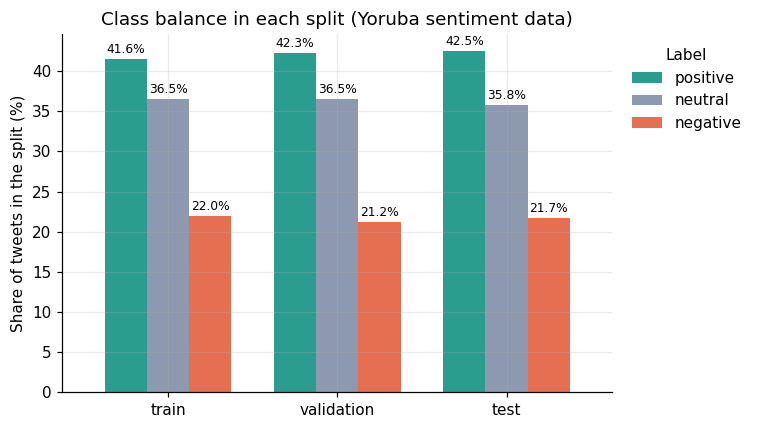

In [7]:
# [1.5] Class balance figure
shares = (label_counts / label_counts.sum() * 100)[SPLITS].T[["positive", "neutral", "negative"]]
ax = shares.plot.bar(figsize=(7, 4), rot=0, width=0.75, color=["#2a9d8f", "#8d99ae", "#e76f51"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", fontsize=8, padding=2)
ax.set_xlabel("")
ax.set_ylabel("Share of tweets in the split (%)")
ax.set_title("Class balance in each split (Yoruba sentiment data)")
ax.legend(title="Label", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig(FIG_DIR / "step1_class_balance.png", bbox_inches="tight")
plt.show()

#### 1.5 Interpretation of the loading checks

**Data version.** The data loaded through the Hugging Face Hub's Parquet export, commit `676cfb15a6761c643d860dcb53bac976e5db2dfc`, and the training text has the fingerprint `34723599f83a74e7`. Loading the same commit gives the same data.

**Split sizes.** The splits hold 8,522 training, 2,090 validation and 4,515 test tweets, 15,127 in total. The NaijaSenti card lists exactly these numbers. The AfriSenti card lists one more tweet in each split. I use the loaded sizes and report the discrepancy between the two cards in the limitations.

**Labels.** The label metadata gives 0 = positive, 1 = neutral, 2 = negative.

**Class balance.** Positive makes up 41.6% of the training split, neutral 36.5% and negative 22.0%. Validation is 42.3%, 36.5% and 21.2%, and test is 42.5%, 35.8% and 21.7%. Each class share differs by under one percentage point between splits, so a shift in class mix cannot explain a gap between validation and test scores, and the test split carries real labels. A classifier that always predicts positive reaches 42.5% accuracy and a macro-F1 of about 0.20 on the test split, so every model has to beat those two numbers. Accuracy rewards the larger classes, and negative is the smallest at roughly one tweet in five. I therefore use macro-F1 as the main metric and report per-class precision and recall next to it.

**Text samples.** In the nine tweets I printed, tone marks appear in some tweets and are missing in others. English appears inside Yoruba tweets. Hashtags and a retweet marker are present, and one tweet still contains a `t.co` link even though the card states that URLs were removed. One neutral tweet is cut off mid-sentence. The neutral samples include a quiz question and a post about a proverb carrying tags such as `#learnyoruba`, which suggests that part of the neutral class comes from language-learning accounts. If so, a hashtag could act as a shortcut for the model. Nine tweets are too few to measure any of this, and the next steps quantify each point.

**Available fields.** The data contains only the tweet text and the label. Without a tweet ID, author or date, I cannot check whether the same author appears in several splits or whether the splits are separated in time. I list this as a limitation.

## 2. Integrity of the splits

### 2.1 Repeated tweets and overlap between splits
Tweets are often retweeted or posted again with small changes, so the same text can appear several times. If a tweet appears in both the training and the test split, a model can score by remembering it, and the test score then overstates how well it handles new text. If the same text carries two different labels, the data contains a disagreement that no model can resolve. I measure both before any modelling.

I compare tweets under three keys: the exact text; the text after Unicode normalization, lower-casing, link removal and retweet-prefix removal; and that normalized text with all combining marks removed, which also catches copies that differ only in tone marks. I do not drop anything in this step. The counts decide what I do next, and I keep per-tweet flags in a saved audit file so that I can later report scores on the full test split and on the test split without overlapping tweets.

In [8]:
# [2.1] Repeats inside each split and overlap between splits
KEYS = {"exact": "tweet", "normalized": "text_norm", "normalized_no_marks": "text_key"}

for df in frames.values():
    df["text_norm"] = df["tweet"].map(normalize_text)
    df["text_key"] = df["text_norm"].map(strip_marks)

# --- 1) Repeats inside each split ---
rows = []
for split, df in frames.items():
    for key_name, col in KEYS.items():
        rows.append({
            "split": split,
            "key": key_name,
            "rows_in_repeat_groups": int(df.duplicated(subset=col, keep=False).sum()),
            "extra_copies": int(df.duplicated(subset=col, keep="first").sum()),
            "groups_with_conflicting_labels": int((df.groupby(col)["label"].nunique() > 1).sum()),
        })
display(pd.DataFrame(rows))

# --- 2) Overlap between splits ---
pairs = [("validation", "train"), ("test", "train"), ("test", "validation")]
rows = []
for a, b in pairs:
    for key_name, col in KEYS.items():
        hit = frames[a][col].isin(set(frames[b][col]))
        rows.append({"split": a, "found_in": b, "key": key_name,
                     "rows": int(hit.sum()), "share_of_split": round(float(hit.mean()), 4)})
display(pd.DataFrame(rows))

# --- 3) Do overlapping tweets carry the same label as their training copy? ---
train_majority = frames["train"].groupby("text_key")["label"].agg(lambda s: s.mode().iloc[0])
rows = []
for split in ["validation", "test"]:
    df = frames[split]
    hit = df["text_key"].isin(train_majority.index)
    same = df.loc[hit, "label"].to_numpy() == train_majority.loc[df.loc[hit, "text_key"]].to_numpy()
    rows.append({"split": split, "overlapping_rows": int(hit.sum()),
                 "same_label_as_train_copy": int(same.sum()),
                 "agreement": round(float(same.mean()), 4) if hit.any() else None})
display(pd.DataFrame(rows))

# --- 4) A few examples of each problem ---
print("Training groups whose copies carry different labels:")
conflicts = frames["train"].groupby("text_key")["label"].nunique()
for key in conflicts[conflicts > 1].index[:5]:
    group = frames["train"][frames["train"]["text_key"] == key]
    print("  ", group["label_name"].tolist(), "|", group["tweet"].iloc[0][:120])

train_keys = set(frames["train"]["text_key"])
for split in ["validation", "test"]:
    frames[split]["overlaps_train"] = frames[split]["text_key"].isin(train_keys)
frames["train"]["overlaps_train"] = False

print("\nTest tweets that also appear in the training split:")
for _, r in frames["test"][frames["test"]["overlaps_train"]].head(5).iterrows():
    print("  ", r["label_name"], "|", r["tweet"][:120])

# --- 5) Save the audit tables (nothing is dropped yet) ---
for split, df in frames.items():
    df.to_csv(AUDIT_DIR / f"{LANG}_{split}_audit.csv", index=False, encoding="utf-8")
save_frames("step2_audit", frames)

,split,key,rows_in_repeat_groups,extra_copies,groups_with_conflicting_labels
0,train,exact,0,0,0
1,train,normalized,2,1,0
2,train,normalized_no_marks,6,3,0
3,validation,exact,0,0,0
4,validation,normalized,0,0,0
5,validation,normalized_no_marks,0,0,0
6,test,exact,0,0,0
7,test,normalized,0,0,0
8,test,normalized_no_marks,6,3,0


,split,found_in,key,rows,share_of_split
0,validation,train,exact,237,0.1134
1,validation,train,normalized,237,0.1134
2,validation,train,normalized_no_marks,237,0.1134
3,test,train,exact,0,0.0000
4,test,train,normalized,8,0.0018
5,test,train,normalized_no_marks,8,0.0018
6,test,validation,exact,0,0.0000
7,test,validation,normalized,1,0.0002
8,test,validation,normalized_no_marks,1,0.0002


,split,overlapping_rows,same_label_as_train_copy,agreement
0,validation,237,231,0.9747
1,test,8,8,1.0000


Training groups whose copies carry different labels:

Test tweets that also appear in the training split:
   positive | orun ire o
   positive | ojúmọ́ ire ni mo jí sí$$$$
   positive | ojúmọ́ ire ni mo jí sí
   positive | ipokipo ti eda ba wa laye adanwo ni ka loo re tori igba ti a o ba fipo sile
   positive | boolu alaaro kutukutu dara fun ara


### 2.2 How much of the evaluation text was seen in training
The bars show the share of validation and test tweets that also appear in the training split, under each of the three matching rules. A bar near zero means the evaluation scores measure performance on unseen text. A taller bar means part of the score comes from tweets the model has already seen.

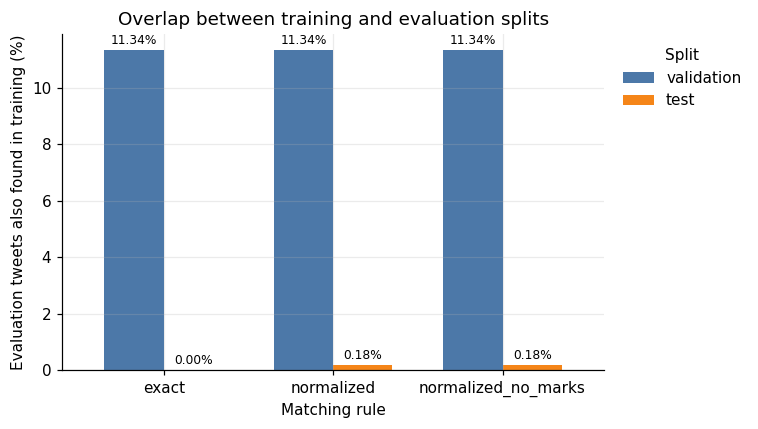

In [9]:
# [2.2] Overlap figure
share = pd.DataFrame({
    split: {key: 100 * frames[split][col].isin(set(frames["train"][col])).mean()
            for key, col in KEYS.items()}
    for split in ["validation", "test"]
})
ax = share.plot.bar(figsize=(7, 4), rot=0, width=0.7, color=["#4c78a8", "#f58518"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", fontsize=8, padding=2)
ax.set_xlabel("Matching rule")
ax.set_ylabel("Evaluation tweets also found in training (%)")
ax.set_title("Overlap between training and evaluation splits")
ax.legend(title="Split", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig(FIG_DIR / "step2_split_overlap.png", bbox_inches="tight")
plt.show()

#### 2.2 Interpretation of the split checks

**Repeats inside each split.** No tweet is repeated word for word inside any split: the exact-match count is 0 in training, validation and test. After cleaning (lower-casing, removing links and the retweet prefix), the training split has one extra copy of a tweet. Ignoring tone marks as well adds two more groups in training and three groups in the test split that differ only in tone marks. No group carries two different labels, so no split contains a direct contradiction.

**Overlap between training and validation.** 237 of the 2,090 validation tweets (11.34%) also appear in the training split. The count is the same under all three matching rules, so these are word-for-word copies. Real tweet collections normally contain exact repeats, and none of the three splits does, which suggests that each split was de-duplicated on its own and that validation was not checked against training. Part of the validation score will therefore measure memory of training tweets. As an illustration, a model that gets 70% of unseen validation tweets right and 95% of the copied ones would read 72.8% on validation.

**Overlap between training and test.** No test tweet is a word-for-word copy of a training tweet. After cleaning, 8 of the 4,515 test tweets (0.18%) match a training tweet, and 1 test tweet (0.02%) matches a validation tweet. All 8 matches to training carry the same label as their training copy. The five printed are all labelled positive and mostly short. The test split is close to clean under these first checks, but section 3.5 later finds substantial overlap after text alignment and a near-duplicate similarity check; see cell 43. Use the aligned seen/unseen definition there for model evaluation.

**Label agreement on copied tweets.** 231 of the 237 copied validation tweets (97.47%) carry the same label as their training copy, and 6 differ. Identical text received different labels in these 6 cases, so the annotation is not fully consistent. Copied tweets may differ from the rest of the data, so I do not treat 2.5% as the label-noise rate of the whole dataset.

### 2.3 Looking at the matched tweets
The counts show how many evaluation tweets also appear in training, and the next cell shows what they are. I print the matched test tweets next to their training partner, the validation tweets whose label differs from their training copy, and a profile of the copied validation tweets (length and label mix), to see whether they are a typical sample of the data or a special kind of tweet.

In [10]:
# [2.3] Matched tweets, label disagreements and a profile of the copies
train_groups = frames["train"].groupby("text_key")
val = frames["validation"].copy()

# 1) Matched test tweets, shown next to their training partner.
print("Test tweets that match a training tweet after cleaning:")
for _, row in frames["test"][frames["test"]["overlaps_train"]].iterrows():
    partner = train_groups.get_group(row["text_key"]).iloc[0]
    print(f"\n  test  [{row['label_name']}]: {row['tweet'][:140]}")
    print(f"  train [{partner['label_name']}]: {partner['tweet'][:140]}")

# 2) Validation tweets whose label differs from their training copy.
train_label = train_groups["label"].agg(lambda s: s.mode().iloc[0])
val_hit = val[val["overlaps_train"]].copy()
val_hit["train_label"] = val_hit["text_key"].map(train_label)
disagree = val_hit[val_hit["label"] != val_hit["train_label"]]
print(f"\nValidation tweets whose label differs from the training copy: {len(disagree)} of {len(val_hit)}")
for _, row in disagree.iterrows():
    print(f"\n  validation [{row['label_name']}] vs train [{id2label[int(row['train_label'])]}]: {row['tweet'][:140]}")

# 3) What kind of tweets are the copied ones?
val["n_words"] = val["tweet"].str.split().str.len()
val["group"] = val["overlaps_train"].map({False: "not in training", True: "also in training"})
display(val.groupby("group")["n_words"].agg(tweets="size", median_words="median", mean_words="mean").round(1))
display(pd.crosstab(val["group"], val["label_name"], normalize="index").round(3)[["positive", "neutral", "negative"]])

Test tweets that match a training tweet after cleaning:

  test  [positive]: orun ire o
  train [positive]: Orun ire o

  test  [positive]: ojúmọ́ ire ni mo jí sí$$$$
  train [positive]: Ojúmọ́ ire ni mo jí sí$$$$

  test  [positive]: ojúmọ́ ire ni mo jí sí
  train [positive]: Ojúmọ́ ire ni mo jí sí

  test  [positive]: ipokipo ti eda ba wa laye adanwo ni ka loo re tori igba ti a o ba fipo sile
  train [positive]: Ipokipo ti eda ba wa laye adanwo ni ka loo re tori igba ti a o ba fipo sile

  test  [positive]: boolu alaaro kutukutu dara fun ara
  train [positive]: Boolu alaaro kutukutu dara fun ara

  test  [neutral]: the english call it lake yorùbá á ma pè é ní odò adágún
  train [neutral]: The English call it LAKE Yorùbá á ma pè é ní ODÒ ADÁGÚN https://t.co/4gXnuRuZHm

  test  [neutral]: ogun lakaiye ọsin mole ogun alada méjì ofi okan sanko ofi okan yena ọjo ogun nti ori oke bo aso ina lo mu bora ẹwu eje lowo ogun onile owo ọ
  train [neutral]: Ogun lakaiye Ọsin mole Ogun alada méjì O

,tweets,median_words,mean_words
group,,,
also in training,237,23.0,24.2
not in training,1853,21.0,21.9


label_name,positive,neutral,negative
group,,,
also in training,0.430,0.363,0.207
not in training,0.422,0.365,0.213


#### 2.3 Interpretation of the matched tweets

**Test matches.** All eight matched test tweets differ from their training partner only in letter case, and one training partner also carries a link. All eight carry the same label as their training partner. Every printed test tweet is entirely lower-case, and the training partners contain capital letters. I count capitals, punctuation, mentions and emoji for every tweet in the next section.

**Validation tweets whose label differs from the training copy.** Six of the 237 copies carry a different label. In five of the six, one of the two labels is neutral. Five of the six appear to be proverb, language-lesson or informational posts, several with hashtags such as #Yoruba and #EsinOro. The disagreement therefore sits at the border between neutral and polar sentiment on posts that describe or teach and do not express a feeling.

**Profile of the copied validation tweets.** The 237 copies have a median of 23 words against 21 for the other validation tweets, and their label mix is 43.0% positive, 36.3% neutral and 20.7% negative against 42.2%, 36.5% and 21.3%. They are typical of the validation split in length and class mix.

### 2.4 Near-duplicates the matching rules miss
The three matching rules only catch tweets that become identical after cleaning. A tweet that differs from a training tweet by a few symbols, for example trailing `$$$$`, passes through all three. To find those, I represent each tweet by its character 3 to 5-grams, weight them with TF-IDF, and compute the cosine similarity between every validation or test tweet and every training tweet. A similarity of 1.0 means identical text after cleaning. I report how many evaluation tweets reach each similarity level and print a sample of the new matches, which shows where a useful cut-off lies. This step only measures overlap and does not remove any tweet.

tweets            share_%           
split                 test validation    test validation
similarity_at_least                                     
0.50                 865.0      631.0   19.16      30.19
0.60                 602.0      478.0   13.33      22.87
0.70                 415.0      365.0    9.19      17.46
0.80                 239.0      314.0    5.29      15.02
0.85                 154.0      297.0    3.41      14.21
0.90                  87.0      283.0    1.93      13.54
0.95                  24.0      277.0    0.53      13.25
1.00                   8.0      237.0    0.18      11.34


validation: 46 tweets are at least 0.90 similar to a training tweet but were not caught by the matching rules
  similarity 0.91
    validation [neutral]: Ògùn(Medicine) Ògùn(Charm) Ogun(War) Ògùn(River) Ògùn(State) Ògún(God of iron) Ó gùn(Its long) Ó gun(Stab) Ogún(Twenty)Ò
    train [neutral]: RT @user: Ogùn(Medicine) Ògùn(Charm) Ogun(War) Ògùn(State) Ògún(God of iron) Ógun(Stab) Ogún(Twenty) Òógùn(Sweat) Ogún(P
  similarity 1.00
    validation [neutral]: 3. Àkànlò èdè ni """"""""""""""""ohun abo"""""""""""""""". Bí a bá wá sọ wípé Adéṣẹwàá ti ní ohun abo, kí la fẹ́ sọ wípé
    train [neutral]: 3. Àkànlò èdè ni """"""""ohun abo"""""""". Bí a bá wá sọ wípé Adéṣẹwàá ti ní ohun abo, kí la fẹ́ sọ wípé Adéṣẹwàá ní? #I
  similarity 1.00
    validation [neutral]: 16. Nínú ẹsẹ̀ odù Ifá kan, a bá a pé """"""""""""""""ọmọ awo kì í lu imí, ọmọ awo kì í lu ìtọ́, kí ni imí àti ìtọ̀ tí If
    train [neutral]: 16. Nínú ẹsẹ̀ odù Ifá kan, a bá a pé """"""""ọmọ awo kì í lu imí, ọmọ awo kì í lu ìtọ́, k

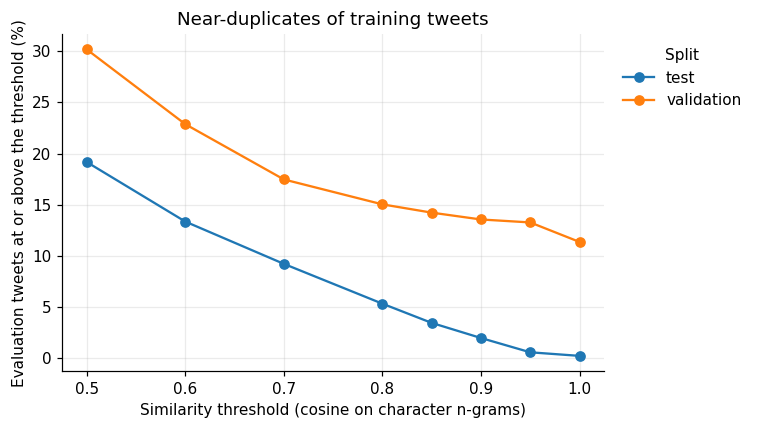

In [11]:
# [2.4] Near-duplicate search with character n-gram TF-IDF
def nearest_train_similarity(split_df, train_df, chunk=500):
    """Highest cosine similarity between each tweet in split_df and any tweet in train_df."""
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True)
    train_mat = vec.fit_transform(train_df["text_key"])
    split_mat = vec.transform(split_df["text_key"])
    best = np.zeros(split_mat.shape[0])
    best_idx = np.zeros(split_mat.shape[0], dtype=int)
    for start in range(0, split_mat.shape[0], chunk):
        sims = (split_mat[start:start + chunk] @ train_mat.T).toarray()
        best[start:start + chunk] = sims.max(axis=1)
        best_idx[start:start + chunk] = sims.argmax(axis=1)
    return best, best_idx

THRESHOLDS = [1.00, 0.95, 0.90, 0.85, 0.80, 0.70, 0.60, 0.50]
rows = []
for split in ["validation", "test"]:
    sim, idx = nearest_train_similarity(frames[split], frames["train"])
    frames[split]["nearest_train_sim"] = sim
    frames[split]["nearest_train_idx"] = idx
    for t in THRESHOLDS:
        hit = sim >= t - 1e-6
        rows.append({"split": split, "similarity_at_least": t,
                     "tweets": int(hit.sum()), "share_%": round(100 * float(hit.mean()), 2)})
sweep_df = pd.DataFrame(rows)
display(sweep_df.pivot(index="similarity_at_least", columns="split", values=["tweets", "share_%"]))

# Matches at 0.90 or above that the three matching rules did not catch.
for split in ["validation", "test"]:
    df = frames[split]
    extra = df[(df["nearest_train_sim"] >= 0.90) & (~df["overlaps_train"])]
    print(f"\n{split}: {len(extra)} tweets are at least 0.90 similar to a training tweet but were not caught by the matching rules")
    for _, r in extra.sample(min(6, len(extra)), random_state=SEED).iterrows():
        partner = frames["train"].iloc[int(r["nearest_train_idx"])]
        print(f"  similarity {r['nearest_train_sim']:.2f}")
        print(f"    {split} [{r['label_name']}]: {r['tweet'][:120]}")
        print(f"    train [{partner['label_name']}]: {partner['tweet'][:120]}")

# Figure
sweep = sweep_df.pivot(index="similarity_at_least", columns="split", values="share_%").sort_index()
ax = sweep.plot(marker="o", figsize=(7, 4))
ax.set_xlabel("Similarity threshold (cosine on character n-grams)")
ax.set_ylabel("Evaluation tweets at or above the threshold (%)")
ax.set_title("Near-duplicates of training tweets")
ax.legend(title="Split", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig(FIG_DIR / "step2_near_duplicates.png", bbox_inches="tight")
plt.show()

save_frames("step2_audit", frames)   # refresh the checkpoint with the new columns

#### 2.4 Interpretation of the near-duplicate search

**Validation.** 283 validation tweets (13.54%) have a training tweet with a similarity of at least 0.90, against 237 exact copies. The curve is almost flat between 0.90 and 1.00 and rises steeply only below 0.80, where the similarity comes from shared hashtags and common phrases and not from copies. The extra 46 tweets are the same text with small differences. Several differ from their training partner in the number of quotation marks around a phrase: 4, 8 and 16 consecutive quotation marks occur in different tweets, which looks like quotation marks being doubled each time the data was exported.

**Test.** 87 test tweets (1.93%) reach 0.90, against the 8 found by the matching rules. In the printed examples the test text is the same text as the training partner without its capital letters, punctuation, @user mentions, retweet marker or emoji, which lowers the similarity score, so 1.93% is a lower bound. One of the six printed pairs is two different short greetings and not a copy, so a threshold of 0.90 also catches formulaic phrases.

**Labels.** Two of the twelve printed pairs carry different labels, one in validation and one in test. Twelve pairs are too few to give a rate, and the next unit measures label agreement over all pairs.

### 2.5 Matching that ignores formatting, and agreement between copies
The printed pairs show that the same text can appear with different capital letters, punctuation, mentions, retweet markers, emoji and quotation marks, so the earlier rules and the similarity score can both under-count copies. I add two stricter matching keys that keep only lower-case letters and digits, with mentions, links and retweet markers removed. The second key also removes hashtags. Then I measure how often a copy carries the same label as its training partner, grouped by how close the copy is, because this shows how consistent the annotation is. Finally I define a tweet as seen in training if any matching rule catches it or its similarity is at least 0.90, and I split validation and test into seen and unseen parts.

In [12]:
# [2.5] Format-insensitive matching, label agreement by closeness, seen and unseen evaluation sets
# 1) Format-insensitive exact matching against the training split.
rows = []
for name, drop in [("match_letters", False), ("match_letters_nohash", True)]:
    key = name + "_key"
    for df in frames.values():
        df[key] = df["tweet"].map(lambda s: letters_key(s, drop))
    train_key = frames["train"][key]
    train_label = frames["train"].groupby(key)["label"].agg(lambda s: s.mode().iloc[0])
    known = set(train_key[train_key != ""])
    for split in ["validation", "test"]:
        df = frames[split]
        hit = df[key].isin(known)
        df[name] = hit
        same = df.loc[hit, "label"].to_numpy() == df.loc[hit, key].map(train_label).to_numpy()
        rows.append({"split": split, "key": name, "matched": int(hit.sum()),
                     "share_%": round(100 * float(hit.mean()), 2),
                     "same_label_%": round(100 * float(same.mean()), 1) if hit.any() else None,
                     "empty_keys": int((df[key] == "").sum())})
display(pd.DataFrame(rows))

# 2) Label agreement between a tweet and its closest training tweet, by closeness.
bands = [(0.99, 1.01, "0.99 and above"), (0.95, 0.99, "0.95 to 0.99"), (0.90, 0.95, "0.90 to 0.95")]
rows = []
for split in ["validation", "test"]:
    df = frames[split]
    partner_label = frames["train"]["label"].to_numpy()[df["nearest_train_idx"].to_numpy()]
    for lo, hi, band in bands:
        m = ((df["nearest_train_sim"] >= lo) & (df["nearest_train_sim"] < hi)).to_numpy()
        if m.any():
            rows.append({"split": split, "similarity": band, "pairs": int(m.sum()),
                         "same_label_%": round(100 * float((df["label"].to_numpy()[m] == partner_label[m]).mean()), 1)})
display(pd.DataFrame(rows))

# 3) Seen / unseen evaluation sets.
for split in ["validation", "test"]:
    df = frames[split]
    df["seen_in_training"] = (df["overlaps_train"] | df["match_letters"] | df["match_letters_nohash"]
                              | (df["nearest_train_sim"] >= 0.90))
frames["train"]["seen_in_training"] = False

EVAL_SETS = build_eval_sets(frames)
display(pd.DataFrame({name: {"rows": len(df), **df["label_name"].value_counts().to_dict()}
                      for name, df in EVAL_SETS.items()}).T)

save_frames("step2_audit", frames)

,split,key,matched,share_%,same_label_%,empty_keys
0,validation,match_letters,272,13.01,96.0,0
1,test,match_letters,128,2.83,96.1,0
2,validation,match_letters_nohash,272,13.01,96.0,0
3,test,match_letters_nohash,261,5.78,95.8,0


,split,similarity,pairs,same_label_%
0,validation,0.99 and above,268,95.9
1,validation,0.95 to 0.99,9,77.8
2,validation,0.90 to 0.95,6,66.7
3,test,0.99 and above,10,100.0
4,test,0.95 to 0.99,14,100.0
5,test,0.90 to 0.95,63,95.2


,rows,positive,neutral,negative
validation_all,2090,884,763,443
validation_unseen,1807,762,656,389
validation_seen,283,122,107,54
test_all,4515,1918,1616,981
test_unseen,4238,1784,1530,924
test_seen,277,134,86,57


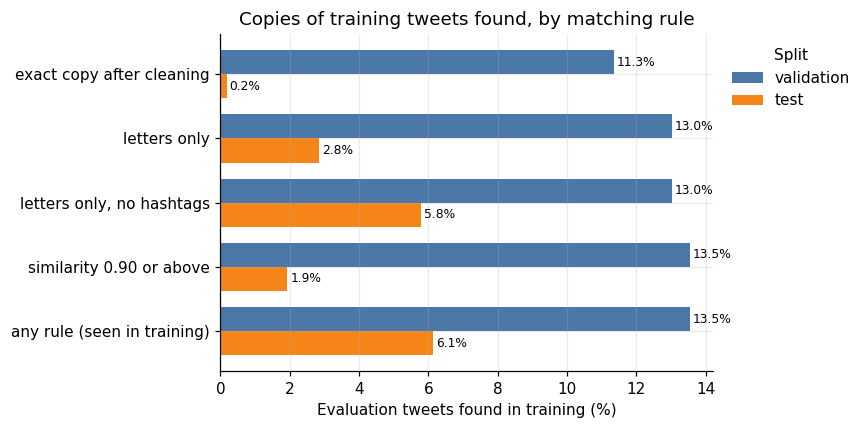

,validation,test
exact copy after cleaning,11.34,0.18
letters only,13.01,2.83
"letters only, no hashtags",13.01,5.78
similarity 0.90 or above,13.54,1.93
any rule (seen in training),13.54,6.14


In [13]:
# [2.5] Figure: how the share of evaluation tweets found in training grows as the matching gets stricter
rules = {
    "exact copy after cleaning": "overlaps_train",
    "letters only": "match_letters",
    "letters only, no hashtags": "match_letters_nohash",
    "similarity 0.90 or above": None,
    "any rule (seen in training)": "seen_in_training",
}
shares = {}
for split in ["validation", "test"]:
    df = frames[split]
    shares[split] = {
        name: 100 * float((df[col] if col else df["nearest_train_sim"] >= 0.90).mean())
        for name, col in rules.items()
    }
shares = pd.DataFrame(shares)
ax = shares.plot.barh(figsize=(8, 4), width=0.75, color=["#4c78a8", "#f58518"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", fontsize=8, padding=2)
ax.invert_yaxis()
ax.set_xlabel("Evaluation tweets found in training (%)")
ax.set_ylabel("")
ax.set_title("Copies of training tweets found, by matching rule")
ax.legend(title="Split", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig(FIG_DIR / "step2_seen_by_rule.png", bbox_inches="tight")
plt.show()
display(shares.round(2))

#### 2.5 Interpretation of the stricter matching and the seen and unseen sets

**Test copies hidden by formatting.** The exact rule found 8 test tweets that copy a training tweet. Ignoring letter case, punctuation, mentions, retweet markers and emoji finds 128 (2.83%), and also ignoring hashtags finds 261 (5.78%). Removing hashtags doubles the test count and changes nothing for validation, which stays at 272 under both keys. So validation tweets keep their hashtags like training does, while many test tweets appear to have lost theirs or carry them in a different form. Together with the lower-case, punctuation-free test text seen in unit 2.3, this supports the idea that the test split was formatted differently from training and validation. It is still an inference from matched pairs, and the next section counts these features over every tweet.

**Why the similarity search under-counted the test.** Only 10 test pairs reach a similarity of 0.99 or above, because the format difference lowers the score, and 63 of the 87 test pairs sit in the 0.90 to 0.95 band. The format-insensitive key removes that difference and finds 261, three times as many.

**Validation.** The key finds 272 copies (13.01%), 35 more than the 237 exact copies. After adding the similarity rule, 283 validation tweets (13.54%) count as seen. That is the same 283 the similarity search found alone, so it had already caught every validation copy the stricter keys caught.

**Test.** 277 test tweets (6.14%) count as seen, about three times the 87 the similarity search found alone. This is still a lower bound, because a copy that differs in more than formatting would escape every rule.

**Label consistency.** About 96% of copied tweets carry the same label as their training twin: 96.0% of 272 in validation, 96.1% of 128 and 95.8% of 261 in test. So roughly 4% of repeated texts received a different label, in both splits. Identical text with two labels sets a ceiling, because no model can match both. This rate applies to repeated content, and the error audit with Yoruba speakers measures it on model errors. Within validation, agreement falls with similarity: 95.9% at 0.99 and above, 77.8% from 0.95 to 0.99 and 66.7% from 0.90 to 0.95. The two lower bands hold only 9 and 6 pairs, which is too few to give a rate. In test, agreement is 100%, 100% and 95.2% across the same bands.

**The seen and unseen sets.** Validation has 1,807 unseen tweets (762 positive, 656 neutral, 389 negative) and 283 seen. Test has 4,238 unseen (1,784, 1,530, 924) and 277 seen. The seen test tweets are 48.4% positive against 42.1% in the unseen test tweets. With only 277 tweets, a gap of that size could come from sampling, so I do not treat it as a pattern.

**How I use the sets.**
- I train on the full training split and leave the official splits unchanged.
- I choose models, tune settings and stop training on `validation_unseen`, so that memorization is not rewarded.
- Every results table reports `test_all` and `test_unseen` side by side. `test_all` is comparable with published work on this data, and `test_unseen` is the measure of performance on new text.
- `test_seen` and `validation_seen` are used only to measure the memorization gap, with their small size noted.
- The seen flags rest on the 0.90 cut-off and on format-insensitive keys. Once the next section settles the cleaning, I recompute them on cleaned text and refresh the checkpoint.

## 3. Surface form of the text

### 3.1 How the tweets look, split by split
Section 2 suggested that the test tweets were formatted differently from the training and validation tweets: lower-case, no punctuation, no @user mentions, no retweet markers, no emoji, and possibly no hashtags. If that is true, a model trained on the raw training text meets differently formatted text at test time, and a validation score would not predict a test score well. Here I measure it directly.

For every tweet I record ten yes-or-no features (capital letters, punctuation, an @user mention, a retweet marker, a hashtag, a link, an emoji, a run of four or more quotation marks, a tone mark, an underdot) and four counts (words, share of capital letters, punctuation marks and tone marks per 100 letters). Tone marks are the grave, acute and macron accents, and the underdot is the dot under e, o and s. I compare the share of tweets with each feature across the three splits. The profile is saved so later steps can reuse it.

Share of tweets (%) with each feature


,train,validation,test,validation_minus_train,test_minus_train
has_uppercase,98.9,98.8,0.0,-0.1,-98.9
has_punctuation,96.1,95.9,0.0,-0.2,-96.1
has_mention,43.7,44.7,0.0,1.0,-43.7
has_retweet_marker,22.0,22.9,0.0,0.9,-22.0
has_hashtag,56.8,55.7,0.0,-1.1,-56.8
has_link,21.1,21.2,0.0,0.1,-21.1
has_emoji,8.1,8.4,1.6,0.3,-6.5
has_quote_run_4plus,10.6,10.6,0.0,0.0,-10.6
has_tone_mark,77.2,77.8,78.4,0.6,1.2
has_underdot,72.9,73.0,73.9,0.1,1.0


Mean and median of the counts


train        validation          test       
                             mean median       mean median   mean median
n_words                     22.22  21.00      22.17  21.00  19.26  18.00
uppercase_letter_share       0.09   0.07       0.09   0.07   0.00   0.00
punctuation_marks            6.05   4.00       7.48   4.00   0.00   0.00
tone_marks_per_100_letters  18.34  20.35      18.49  20.79  23.78  29.17

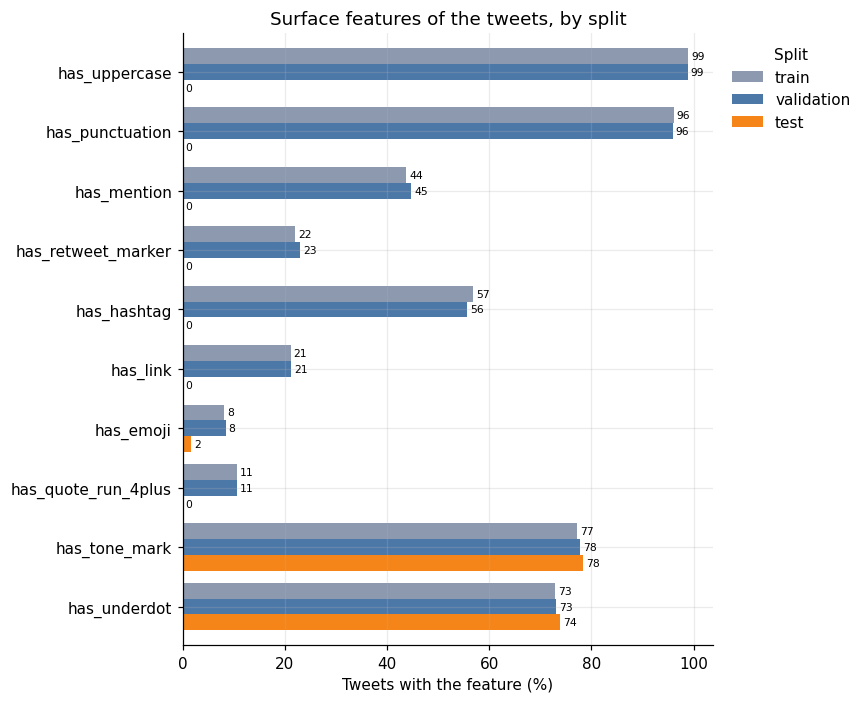

In [14]:
# [3.1] Surface-form profile of every tweet
EMOJI_RE = re.compile("[\U0001F300-\U0001FAFF\u2600-\u27BF\uFE0F\u200D]")
QUOTE_RUN_RE = re.compile('["\u201c\u201d]+')
TONE_MARKS = {"\u0300", "\u0301", "\u0304"}   # grave, acute, macron
UNDERDOT = "\u0323"

def surface_features(text):
    no_url = URL_RE.sub(" ", text)
    nfd = unicodedata.normalize("NFD", text)
    letters = [ch for ch in text if ch.isalpha()]
    n_letters = max(len(letters), 1)
    n_tone = sum(ch in TONE_MARKS for ch in nfd)
    punct = [ch for ch in no_url if unicodedata.category(ch).startswith("P") and ch not in "#@"]
    quote_run = max((len(m.group()) for m in QUOTE_RUN_RE.finditer(text)), default=0)
    return {
        "has_uppercase": any(ch.isupper() for ch in text),
        "has_punctuation": len(punct) > 0,
        "has_mention": "@user" in text.lower(),
        "has_retweet_marker": bool(re.match(r"\s*rt\b", text, flags=re.IGNORECASE)),
        "has_hashtag": bool(HASHTAG_RE.search(text)),
        "has_link": bool(URL_RE.search(text)) or "t.co" in text.lower(),
        "has_emoji": bool(EMOJI_RE.search(text)),
        "has_quote_run_4plus": quote_run >= 4,
        "has_tone_mark": n_tone > 0,
        "has_underdot": UNDERDOT in nfd,
        "n_words": len(text.split()),
        "uppercase_letter_share": sum(ch.isupper() for ch in letters) / n_letters,
        "punctuation_marks": len(punct),
        "tone_marks_per_100_letters": 100 * n_tone / n_letters,
    }

profile = {}
for split in SPLITS:
    p = pd.DataFrame([surface_features(t) for t in frames[split]["tweet"]])
    p["label_name"] = frames[split]["label_name"].to_numpy()
    profile[split] = p

BINARY = [c for c in profile["train"].columns if c.startswith("has_")]
NUMERIC = ["n_words", "uppercase_letter_share", "punctuation_marks", "tone_marks_per_100_letters"]

# Share of tweets with each feature, and the gap to the training split.
rate = pd.DataFrame({s: 100 * profile[s][BINARY].mean() for s in SPLITS}).round(1)
rate["validation_minus_train"] = (rate["validation"] - rate["train"]).round(1)
rate["test_minus_train"] = (rate["test"] - rate["train"]).round(1)
print("Share of tweets (%) with each feature")
display(rate)

print("Mean and median of the counts")
display(pd.concat({s: profile[s][NUMERIC].agg(["mean", "median"]).T for s in SPLITS}, axis=1).round(2))

# Figure
ax = rate[SPLITS].plot.barh(figsize=(8, 6.5), width=0.8, color=["#8d99ae", "#4c78a8", "#f58518"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", fontsize=7, padding=2)
ax.invert_yaxis()
ax.set_xlabel("Tweets with the feature (%)")
ax.set_ylabel("")
ax.set_title("Surface features of the tweets, by split")
ax.legend(title="Split", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig(FIG_DIR / "step3_surface_profile.png", bbox_inches="tight")
plt.show()

save_frames("step3_profile", profile)

#### 3.1 Interpretation of the surface profile

**Training and validation match.** Every feature differs by 1.1 percentage points or less between training and validation: capital letters 98.9% against 98.8%, punctuation 96.1% against 95.9%, an @user mention 43.7% against 44.7%, a hashtag 56.8% against 55.7%, a link 21.1% against 21.2%. Validation was prepared like training.

**The test split is a different kind of text.** No test tweet contains a capital letter, punctuation, an @user mention, a retweet marker, a hashtag, a link or a run of quotation marks, although 98.9%, 96.1%, 43.7%, 22.0%, 56.8%, 21.1% and 10.6% of training tweets do. Emoji fall from 8.1% to 1.6%, so most but not all were removed. Tone marks (78.4% against 77.2%) and underdots (73.9% against 72.9%) survive at the training rate, so the cleaning removed formatting and kept the Yoruba spelling.

**Length and tone density follow.** Test tweets have a median of 18 words against 21 and a mean of 19.3 against 22.2, about three words fewer, which is what removing mentions, retweet markers, hashtags and links would do. The median number of tone marks per 100 letters is 29.2 in test and 20.4 in training. Letters in removed tokens such as "RT", "@user" and link text carry no tone marks, so removing them raises the density without any new marking. Unit 3.5 tests this explanation.

**Why it matters.** A model trained on raw text learns from capitals, punctuation, hashtags and mentions that never appear at test time, and validation, which looks like training, cannot reveal this. Validation scores will not predict test scores unless the formats are aligned.

### 3.2 The same text in two splits: what differs?
Comparing whole splits can hide the cause, because the splits also differ in which tweets they hold. A cleaner test uses tweets that appear in both an evaluation split and the training split. The text is the same, so any difference in formatting comes from how the split was prepared and not from the tweets. For every validation and test tweet that matches a training tweet under the strictest key from section 2 (letters only, hashtags removed), I find its training copy and count how often a feature is present in one copy and missing from the other. Validation serves as the control: if it was prepared like training, both columns should be near zero for validation.

pairs            only_in_training_copy_%             \
split                 test validation                    test validation   
feature                                                                    
has_emoji            261.0      272.0                    18.4        0.4   
has_hashtag          261.0      272.0                    51.0        0.0   
has_link             261.0      272.0                    28.0        0.0   
has_mention          261.0      272.0                    50.6        0.4   
has_punctuation      261.0      272.0                    91.6        0.0   
has_quote_run_4plus  261.0      272.0                    10.0        0.0   
has_retweet_marker   261.0      272.0                    30.7        0.4   
has_tone_mark        261.0      272.0                     0.4        0.0   
has_underdot         261.0      272.0                     0.4        0.0   
has_uppercase        261.0      272.0                    99.2        0.0   

                    only_in_evaluation_copy_%             
split                                    test validation  
feature                                                   
has_emoji                                 0.0        0.4  
has_hashtag                               0.0        0.7  
has_link                                  0.0        0.4  
has_mention                               0.0        0.4  
has_punctuation                           0.0        0.0  
has_quote_run_4plus                       0.0        0.0  
has_retweet_marker                        0.4        0.4  
has_tone_mark                             0.4        0.0  
has_underdot                              0.0        0.0  
has_uppercase                             0.0        0.0


test : 'apa lara igunpa niyekan oun ti a ba si fara sise fun oun nii pe lowo eni e je ka mura sise wa eyin ore mi nitori osise jare ole'
train: '#OroAmoye Apa lara igunpa niyekan, oun ti a ba si fara sise fun oun nii pe lowo eni, e je ka mura sise wa eyin ore mi, nitori osise jare ole'

test : 'amin o beno lo ma se ri fun gbogbo ninu osu yi'
train: 'RT @user: @user AMIN o. Beno lo ma se ri fun gbogbo ninu osu yi'

test : 'eseun gan a ki yin fun akitiyan yin awa na o ni sere legbe peturolu rara'
train: 'RT @user: @user eseun gan. A ki yin fun akitiyan yin. Awa na o ni sere legbe peturolu rara.'


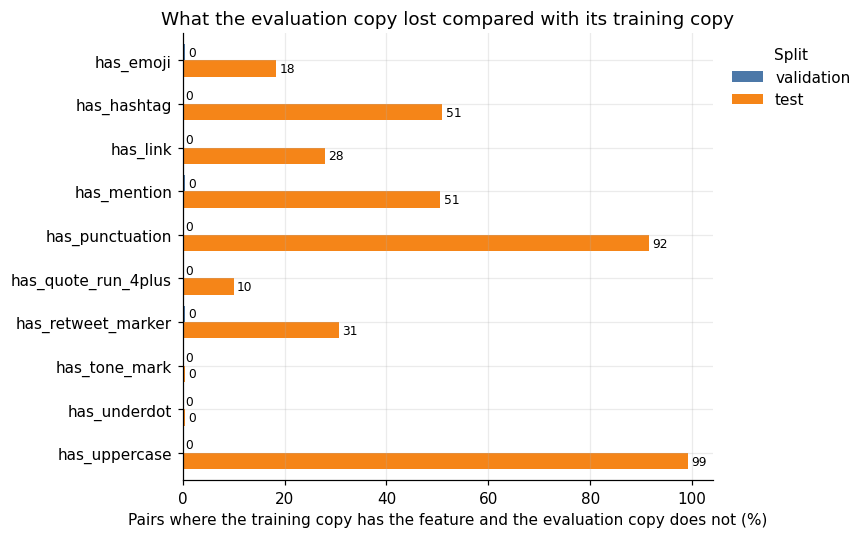

In [15]:
# [3.2] Paired comparison of each evaluation tweet with its training copy
key = "match_letters_nohash_key"
train_df = frames["train"].reset_index(drop=True)
first_pos = {}
for i, k in enumerate(train_df[key]):
    first_pos.setdefault(k, i)

rows, pair_examples = [], {}
for split in ["validation", "test"]:
    df = frames[split].reset_index(drop=True)
    hit = df.index[df["match_letters_nohash"].to_numpy()]
    partner = df.loc[hit, key].map(first_pos).astype(int).to_numpy()
    ev = profile[split].loc[hit, BINARY].to_numpy().astype(bool)
    tr = profile["train"].iloc[partner][BINARY].to_numpy().astype(bool)
    for j, feat in enumerate(BINARY):
        rows.append({"split": split, "feature": feat, "pairs": len(hit),
                     "only_in_training_copy_%": round(100 * float((tr[:, j] & ~ev[:, j]).mean()), 1),
                     "only_in_evaluation_copy_%": round(100 * float((ev[:, j] & ~tr[:, j]).mean()), 1)})
    pair_examples[split] = list(zip(hit[:3], partner[:3]))
pair_table = pd.DataFrame(rows)
display(pair_table.pivot(index="feature", columns="split",
                         values=["pairs", "only_in_training_copy_%", "only_in_evaluation_copy_%"]))

# Three test pairs, printed with repr so that hidden characters and spacing are visible.
test_df = frames["test"].reset_index(drop=True)
for i, j in pair_examples["test"]:
    print("\ntest :", repr(test_df.loc[i, "tweet"][:150]))
    print("train:", repr(train_df.loc[j, "tweet"][:150]))

# Figure: features present in the training copy but missing from the evaluation copy.
lost = pair_table.pivot(index="feature", columns="split", values="only_in_training_copy_%")[["validation", "test"]]
ax = lost.plot.barh(figsize=(8, 5), width=0.75, color=["#4c78a8", "#f58518"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", fontsize=8, padding=2)
ax.invert_yaxis()
ax.set_xlabel("Pairs where the training copy has the feature and the evaluation copy does not (%)")
ax.set_ylabel("")
ax.set_title("What the evaluation copy lost compared with its training copy")
ax.legend(title="Split", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig(FIG_DIR / "step3_paired_formatting.png", bbox_inches="tight")
plt.show()

#### 3.2 Interpretation of the paired comparison

**Control.** Of the 272 validation tweets with a training copy, no feature is lost or gained in more than 0.7% of pairs (the largest value is a hashtag present only in the validation copy). Validation and training were formatted the same way.

**Test.** For the 261 test tweets with a training copy, the training copy has a capital letter in 99.2% of pairs, punctuation in 91.6%, a hashtag in 51.0%, an @user mention in 50.6%, a retweet marker in 30.7%, a link in 28.0%, an emoji in 18.4% and a run of four or more quotation marks in 10.0%, and the test copy has none of them. Tone marks and underdots are lost in 0.4% of pairs, a single pair. In the opposite direction, a feature appears only in the test copy in at most 0.4% of pairs, so the test text is a stripped version of the same text and nothing was added.

**What the examples show.** The hashtag `#OroAmoye` disappears together with its word, `RT @user: @user` disappears completely, capitals and punctuation are gone, and the tone marks stay. So the cleaning lowercases the text and removes mentions, retweet markers, hashtags with their words, links, punctuation and most emoji.

**A check on section 2.** Hashtags are lost in 51.0% of the 261 pairs, which is 133 pairs. In unit 2.5, ignoring hashtags raised the number of matched test tweets from 128 to 261, a difference of 133. The formatting difference explains that jump exactly.

**Limit.** Only tweets that have a training copy can be compared, so the pairs show how those tweets were cleaned. The 0.0% rates over all 4,515 test tweets in unit 3.1 support the same cleaning for the whole split.

### 3.3 Tone marks and length
Yoruba is a tonal language, and tone marks and underdots separate words that are otherwise spelled the same. Tweets often leave them out, so a classifier sees the same word written in several ways. I measure how many tweets carry tone marks or underdots in each split, how much of the text is marked, and whether that differs by split or by label. I also compare tweet length, because length decides the maximum sequence length I give the transformer models later. If tone-mark use differs between splits, the diacritic experiments in the modelling stage need to account for it.

Share of tweets (%) by diacritic use


,train,validation,test
neither,21.8,21.6,20.7
underdot only,1.0,0.7,0.9
tone mark only,5.3,5.4,5.5
tone mark and underdot,72.0,72.3,73.0


Tone marks per 100 letters, among tweets that have at least one tone mark


,train,validation,test
0.10,9.0,9.6,14.0
0.25,16.3,16.1,24.3
0.50,25.0,25.0,32.6
0.75,31.3,31.5,37.5
0.90,35.9,35.8,41.5


Tweets with a tone mark (%), by label


,train,validation,test
label_name,,,
positive,73.3,73.5,75.3
neutral,85.3,86.1,87.3
negative,71.4,71.8,70.1


Tweet length in words


,train,validation,test
count,8522.0,2090.0,4515.0
mean,22.2,22.2,19.3
std,11.2,11.3,10.8
min,3.0,3.0,3.0
50%,21.0,21.0,18.0
90%,36.0,37.0,31.0
99%,57.0,57.0,54.0
max,74.0,65.0,69.0


Median words by label


,train,validation,test
label_name,,,
positive,21.0,20.0,18.0
neutral,21.0,21.0,17.0
negative,23.0,23.0,20.0


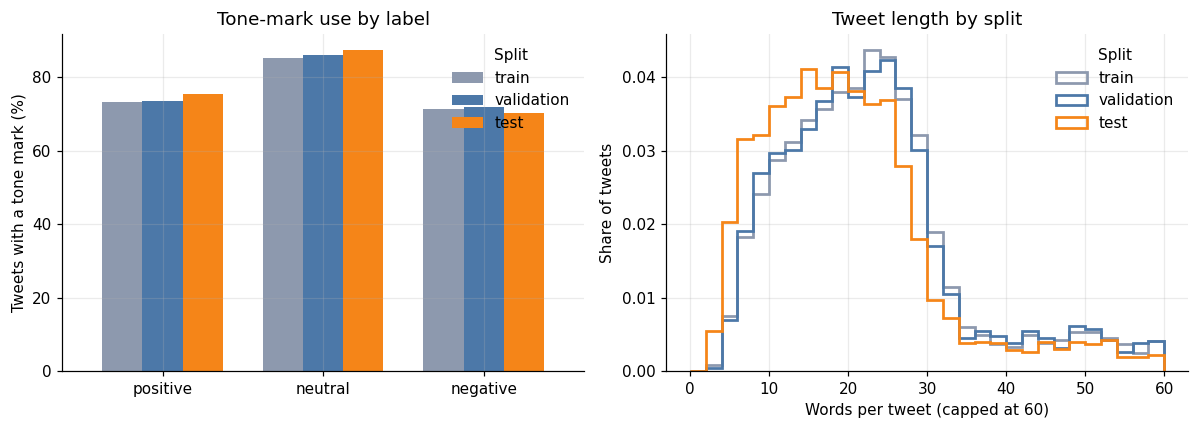

In [16]:
# [3.3] Tone marks, underdots and length
def diacritic_group(p):
    return np.select(
        [p["has_tone_mark"] & p["has_underdot"], p["has_tone_mark"], p["has_underdot"]],
        ["tone mark and underdot", "tone mark only", "underdot only"], default="neither")

use = pd.DataFrame({s: pd.Series(diacritic_group(profile[s])).value_counts(normalize=True).mul(100)
                    for s in SPLITS}).fillna(0).round(1)
use = use.reindex(["neither", "underdot only", "tone mark only", "tone mark and underdot"], fill_value=0)
print("Share of tweets (%) by diacritic use")
display(use)

marked = {s: profile[s].loc[profile[s]["has_tone_mark"], "tone_marks_per_100_letters"] for s in SPLITS}
print("Tone marks per 100 letters, among tweets that have at least one tone mark")
display(pd.DataFrame({s: v.quantile([0.1, 0.25, 0.5, 0.75, 0.9]) for s, v in marked.items()}).round(1))

order = ["positive", "neutral", "negative"]
by_label = pd.concat({s: profile[s].groupby("label_name")["has_tone_mark"].mean().mul(100) for s in SPLITS},
                     axis=1).loc[order].round(1)
print("Tweets with a tone mark (%), by label")
display(by_label)

length = pd.concat({s: profile[s]["n_words"].describe(percentiles=[0.5, 0.9, 0.99]) for s in SPLITS},
                   axis=1).round(1)
print("Tweet length in words")
display(length)
print("Median words by label")
display(pd.concat({s: profile[s].groupby("label_name")["n_words"].median() for s in SPLITS}, axis=1).loc[order])

# Figure: tone-mark use by label and split, and length by split.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
by_label.plot.bar(ax=axes[0], rot=0, width=0.75, color=["#8d99ae", "#4c78a8", "#f58518"])
axes[0].set_ylabel("Tweets with a tone mark (%)")
axes[0].set_xlabel("")
axes[0].set_title("Tone-mark use by label")
axes[0].legend(title="Split", frameon=False)
for s, c in zip(SPLITS, ["#8d99ae", "#4c78a8", "#f58518"]):
    axes[1].hist(profile[s]["n_words"].clip(upper=60), bins=range(0, 62, 2), density=True,
                 histtype="step", linewidth=1.8, color=c, label=s)
axes[1].set_xlabel("Words per tweet (capped at 60)")
axes[1].set_ylabel("Share of tweets")
axes[1].set_title("Tweet length by split")
axes[1].legend(title="Split", frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "step3_tone_and_length.png", bbox_inches="tight")
plt.show()

#### 3.3 Interpretation of tone marks and length

**Diacritic use is the same in all three splits.** About 72% of tweets have both tone marks and underdots (72.0%, 72.3% and 73.0% in training, validation and test), 5% have tone marks only, 1% have underdots only, and 21.8%, 21.6% and 20.7% have neither. Roughly one tweet in five carries no diacritic at all.

**What "neither" contains.** Such a tweet may be Yoruba written without marks, or it may contain no word that needs one, for example a short greeting, an English or Pidgin sentence, or a name. The counts cannot separate the two. The stripped-marks experiment measures how much the marks matter to a model. The planned reader audit was not completed, so it cannot establish how many errors sit on unmarked Yoruba.

**Marking is uneven.** Among tweets with at least one tone mark, the median is 25.0 marks per 100 letters in training and validation, and the middle 80% runs from 9.0 to 35.9 in training. Some tweets mark a few words and others mark nearly all, so one tweet can mix marked and unmarked spellings. Test is denser (median 32.6, 10th to 90th percentile 14.0 to 41.5), for the formatting reason given in 3.1.

**Tone marks track the neutral class.** In training, 85.3% of neutral tweets carry a tone mark against 73.3% of positive and 71.4% of negative ones. Validation (86.1%, 73.5%, 71.8%) and test (87.3%, 75.3%, 70.1%) show the same pattern, and the gap of 12 to 17 points is far beyond sampling noise. Positive and negative do not differ from each other. Carefully written text such as proverbs, lessons and announcements is more often neutral, so the marks are a style cue and not a sentiment cue. A model could learn "has tone marks, so neutral", and the stripped-marks experiment will show how much accuracy depends on that.

**Length.** Training and validation have the same distribution (mean 22.2 words, median 21, 99th percentile 57). Test is shorter (mean 19.3, median 18), again because of the removed tokens. Negative tweets are the longest in every split, by two to three words at the median, a small but consistent difference. For the models, 99% of tweets have at most 57 words, but a Yoruba word splits into several subword pieces, so I set the maximum sequence length from the tokenizer in the modelling stage and not from this count.

### 3.4 Do surface cues differ by class?
A classifier takes whatever signal helps, including signals that have nothing to do with sentiment. Section 1 suggested that part of the neutral class comes from language-learning accounts with hashtags such as #learnyoruba. If a hashtag, a link, a mention or an emoji is much more common in one class, the model can lean on it and score well without reading the sentence, and it would then fail on text that lacks the cue. I measure each cue by class in the training split, where the model learns, and print the spread between the most and the least common class next to the sampling margin that a gap of that size could come from by chance.

Gaps below about 2.3 percentage points can arise by chance with 1872 tweets in the smallest class.


label_name,positive,neutral,negative,spread_pp
has_uppercase,98.7,99.1,98.7,0.4
has_punctuation,95.6,96.3,96.7,1.1
has_mention,51.1,35.2,43.9,15.9
has_retweet_marker,26.4,17.6,20.8,8.8
has_hashtag,48.8,65.8,56.8,17.0
has_link,17.0,26.0,20.8,9.0
has_emoji,8.5,8.2,7.2,1.3
has_quote_run_4plus,10.9,10.3,10.4,0.6
has_tone_mark,73.3,85.3,71.4,13.9
has_underdot,68.4,80.7,68.6,12.3


Median words and mean punctuation marks by label (training split)


n_words        punctuation_marks      
            median   mean            median  mean
label_name                                       
positive      21.0  21.55               4.0  5.86
neutral       21.0  22.22               4.0  6.35
negative      23.0  23.48               4.0  5.91

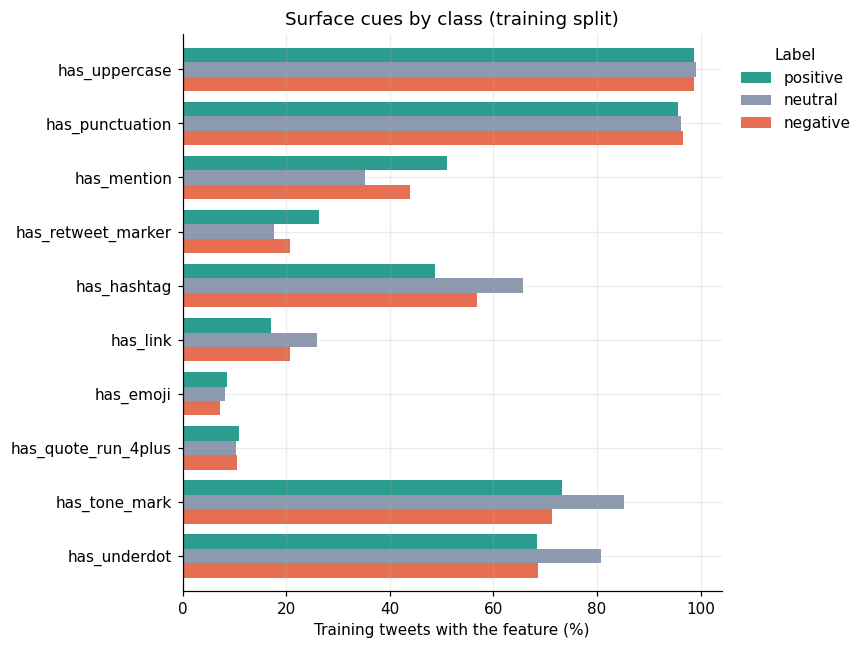

In [17]:
# [3.4] Surface cues by class in the training split
cues = (profile["train"].groupby("label_name")[BINARY].mean().mul(100).T)[order].round(1)
cues["spread_pp"] = (cues[order].max(axis=1) - cues[order].min(axis=1)).round(1)
n_smallest = int(profile["train"]["label_name"].value_counts().min())
margin = 196 * (0.25 / n_smallest) ** 0.5
print(f"Gaps below about {margin:.1f} percentage points can arise by chance with {n_smallest} tweets in the smallest class.")
display(cues)

print("Median words and mean punctuation marks by label (training split)")
display(profile["train"].groupby("label_name")[["n_words", "punctuation_marks"]]
        .agg(["median", "mean"]).loc[order].round(2))

ax = cues[order].plot.barh(figsize=(8, 6), width=0.8, color=["#2a9d8f", "#8d99ae", "#e76f51"])
ax.invert_yaxis()
ax.set_xlabel("Training tweets with the feature (%)")
ax.set_ylabel("")
ax.set_title("Surface cues by class (training split)")
ax.legend(title="Label", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig(FIG_DIR / "step3_cues_by_class.png", bbox_inches="tight")
plt.show()

#### 3.4 Interpretation of surface cues by class

Gaps below 2.3 percentage points can arise by chance. Four features have spreads of 1.3 points or less (capital letters, punctuation, emoji and quotation-mark runs), so they carry no class information. Six features separate the classes well beyond chance.

**Neutral tweets look informational.** They have the most hashtags (65.8% against 48.8% for positive and 56.8% for negative), the most links (26.0%), the fewest @user mentions (35.2%) and retweet markers (17.6%), and the most tone marks (85.3%) and underdots (80.7%).

**Positive tweets look conversational.** 51.1% contain a mention and 26.4% a retweet marker, and they have the fewest hashtags (48.8%) and links (17.0%). Negative tweets sit between the two on mentions (43.9%), hashtags (56.8%) and links (20.8%).

**Consequence.** The hashtag, mention, retweet and link cues exist only in training and validation, because unit 3.2 shows that the test text has none of them. A model trained on raw text can learn "hashtag, so neutral" and then meet a test split where no tweet has a hashtag. Any gap between its validation and test scores would then reflect these cues, which is why the modelling stage compares raw and aligned training text. The tone-mark cue is different: it is present at test time with the same class pattern, so a model can use it on test, and it is a style cue and not evidence of sentiment.

**Length and punctuation** differ little by class (median 21, 21 and 23 words for positive, neutral and negative; mean punctuation marks 5.9, 6.4 and 5.9). The six cues probably overlap, because a tweet with a hashtag, a link and carefully marked Yoruba is often one informational post, so they are not six independent signals.

### 3.5 Rebuilding the test format and refreshing the overlap flags
Units 3.1 and 3.2 show that the test text is a cleaned version of raw text. If I can reproduce the test text exactly from its training copies, I have the cleaning rule, and I can apply the same rule to training and validation so that all three splits share one format. I try six variants of the rule (three choices for what to remove from the text, two choices for what to leave in its place), measure how many of the 261 test tweets each variant reproduces exactly from the training copy, and keep the best.

Then I check the explanations from 3.1 and 3.3: after the rule is applied, the length and the tone density of training and validation should match the test split. I also count the tweets that the cleaning empties or leaves very short, because a tweet made only of mentions and hashtags has no text left to classify. Finally I recompute the overlap with training on the aligned text, because formatting differences hid copies in section 2. A tweet counts as seen in training if either the old rules or the new ones catch it, and I rebuild the seen and unseen evaluation sets from that union.

,remove,replace_with,pairs,exact_%
0,all,nothing,261,91.2
1,all,a space,261,91.2
2,keep_symbols,nothing,261,78.9
3,keep_symbols,a space,261,78.9
4,ascii_only,nothing,261,70.9
5,ascii_only,a space,261,70.9


Chosen variant: {'rule': 'all', 'repl': ''} | exact reproduction: 91.2 %

23 of 261 pairs are not reproduced exactly. First 6:

  made : 'ẹ káárọ̀ o ṣé àlàáfíà lẹ wà ️ àá ṣe àṣeyọrí lọ́sẹ̀ yí lágbára ọlọ́run good morning hope you are fine wishing you success in all your endeavours this w'
  test : 'ẹ káárọ̀ o ṣé àlàáfíà lẹ wà \u200d️ àá ṣe àṣeyọrí lọ́sẹ̀ yí lágbára ọlọ́run good morning hope you are fine wishing you success in all your endeavours this '

  made : 'yakubu adesokan ṣorí ire'
  test : 'rt yakubu adesokan ṣorí ire'

  made : 'ìwòrìwò làgbàdo ńwọlẹ̀ igba aṣọ ní í mú jáde ire kànkà ire rìbìtì ire ẹ̀rìmọ̀ ire fẹ̀nfẹ̀ n tiwa lọ́dún yìí'
  test : 'ìwòrìwò làgbàdo ńwọlẹ̀ igba aṣọ ní í mú jáde | ire kànkà ire rìbìtì ire ẹ̀rìmọ̀ ire fẹ̀nfẹ̀ n tiwa lọ́dún yìí'

  made : 'rántí ọmọ ẹni tí ìwọ ń ṣe ò'
  test : 'rántí ọmọ ẹni tí ìwọ ń ṣe o'

  made : 'ojúmọ́ ire ni mo jí sí'
  test : 'ojúmọ́ ire ni mo jí sí$$$$'

  made : 'mo fe alaafia fun venezuela jòwó jòwó jòwó náà fẹ́ àlááfíà fún'

words_mean  words_median  tone_per_100_median  \
train      raw           22.22          21.0                20.35   
           aligned       19.29          18.0                28.57   
validation raw           22.17          21.0                20.79   
           aligned       19.22          18.0                28.65   
test       raw           19.26          18.0                29.17   
           aligned       19.18          18.0                29.17   

                    empty_tweets  under_3_words  
train      raw               0.0            0.0  
           aligned           0.0            1.0  
validation raw               0.0            0.0  
           aligned           0.0            0.0  
test       raw               0.0            0.0  
           aligned           0.0            0.0

,split,n,exact_on_aligned,similarity_0.90+,seen_section2,seen_aligned,seen_final,final_share_%,same_label_%_on_exact
0,validation,2090,272,305,283,305,306,14.64,96.0
1,test,4515,400,577,277,577,577,12.78,95.5


,rows,positive,neutral,negative
validation_all,2090,884,763,443
validation_unseen,1784,747,654,383
validation_seen,306,137,109,60
test_all,4515,1918,1616,981
test_unseen,3938,1647,1422,869
test_seen,577,271,194,112


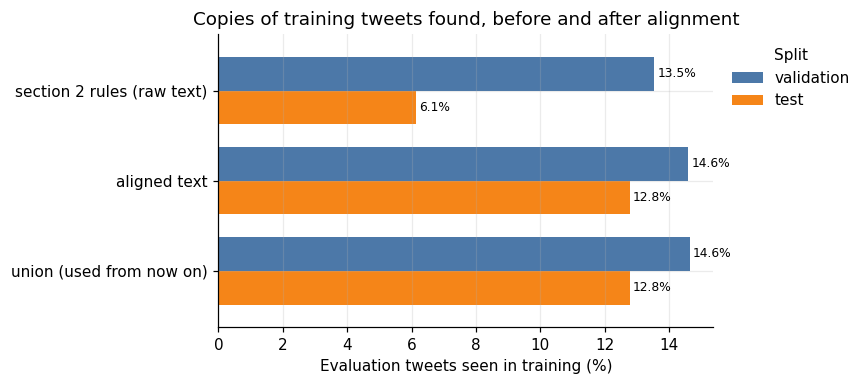

In [18]:
# [3.5] Rebuild the test format, check it on paired tweets, refresh the overlap flags
ASCII_PUNCT = set("!\"#$%&'()*+,-./:;<=>?@[\\]^_`{|}~")
LINK_RE = re.compile(r"https?://\S+|www\.\S+|\bt\.co/\S+", flags=re.IGNORECASE)
HASHTAG_TOKEN_RE = re.compile(r"#\S+")
MENTION_TOKEN_RE = re.compile(r"@\S+")

def align_format(text, rule="all", repl=""):
    """Lower-case, drop links, retweet marker, hashtags (with their words) and mentions, then drop punctuation.
    rule: 'all' drops every character that is not a letter, mark, digit or space;
          'keep_symbols' keeps symbols such as $ and emoji; 'ascii_only' drops only ASCII punctuation.
    repl: what replaces a dropped character ('' or ' ')."""
    t = unicodedata.normalize("NFC", text)
    t = LINK_RE.sub(" ", t)
    t = re.sub(r"^\s*rt\b", " ", t, flags=re.IGNORECASE)
    t = HASHTAG_TOKEN_RE.sub(" ", t)
    t = MENTION_TOKEN_RE.sub(" ", t)
    t = t.lower()
    kept = []
    for ch in t:
        cat = unicodedata.category(ch)
        if ch.isspace() or cat[0] in "LMN":
            kept.append(ch)
        elif rule == "keep_symbols" and cat[0] == "S":
            kept.append(ch)
        elif rule == "ascii_only" and ch not in ASCII_PUNCT:
            kept.append(ch)
        else:
            kept.append(repl)
    return " ".join("".join(kept).split())

# 1) Which variant reproduces the test text from the training copy?
train_df = frames["train"].reset_index(drop=True)
test_df = frames["test"].reset_index(drop=True)
first_pos = {}
for i, k in enumerate(train_df["match_letters_nohash_key"]):
    first_pos.setdefault(k, i)
hit = test_df.index[test_df["match_letters_nohash"].to_numpy()]
partner = test_df.loc[hit, "match_letters_nohash_key"].map(first_pos).astype(int).to_numpy()
test_texts = [" ".join(test_df.loc[i, "tweet"].split()) for i in hit]
train_texts = [train_df.loc[j, "tweet"] for j in partner]

rows = []
for rule in ["all", "keep_symbols", "ascii_only"]:
    for repl in ["", " "]:
        made = [align_format(t, rule, repl) for t in train_texts]
        rows.append({"remove": rule, "replace_with": "nothing" if repl == "" else "a space",
                     "pairs": len(made),
                     "exact_%": round(100 * float(np.mean([a == b for a, b in zip(made, test_texts)])), 1)})
repro = pd.DataFrame(rows)
display(repro)
best = repro.sort_values("exact_%", ascending=False, kind="stable").iloc[0]
ALIGN = {"rule": best["remove"], "repl": "" if best["replace_with"] == "nothing" else " "}
print("Chosen variant:", ALIGN, "| exact reproduction:", best["exact_%"], "%")

made = [align_format(t, **ALIGN) for t in train_texts]
bad = [k for k, (a, b) in enumerate(zip(made, test_texts)) if a != b]
print(f"\n{len(bad)} of {len(made)} pairs are not reproduced exactly. First 6:")
for k in bad[:6]:
    print("\n  made :", repr(made[k][:150]))
    print("  test :", repr(test_texts[k][:150]))

# 2) Apply the chosen rule to every split.
for split in SPLITS:
    frames[split]["text_aligned"] = frames[split]["tweet"].map(lambda t: align_format(t, **ALIGN))

# 3) Do length and tone density now match the test split? How many tweets are emptied?
cmp = {}
for split in SPLITS:
    for name, col in [("raw", "tweet"), ("aligned", "text_aligned")]:
        f = pd.DataFrame([surface_features(t) for t in frames[split][col]])
        cmp[(split, name)] = {"words_mean": f["n_words"].mean(), "words_median": f["n_words"].median(),
                              "tone_per_100_median": f["tone_marks_per_100_letters"].median(),
                              "empty_tweets": int((f["n_words"] == 0).sum()),
                              "under_3_words": int((f["n_words"] < 3).sum())}
print("\nLength and tone density before and after the rule")
display(pd.DataFrame(cmp).T.round(2))

# 4) Overlap with training, recomputed on the aligned text.
view = {s: pd.DataFrame({"text_key": frames[s]["text_aligned"].map(strip_marks)}) for s in SPLITS}
train_view = pd.DataFrame({"k": view["train"]["text_key"], "label": frames["train"]["label"].to_numpy()})
train_label_aligned = train_view[train_view["k"] != ""].groupby("k")["label"].agg(lambda s: s.mode().iloc[0])

rows = []
for split in ["validation", "test"]:
    df = frames[split]
    sim, _ = nearest_train_similarity(view[split], view["train"])
    exact = view[split]["text_key"].isin(train_label_aligned.index).to_numpy()
    if "seen_v1" not in df.columns:
        df["seen_v1"] = df["seen_in_training"]          # the section 2 definition, kept for reference
    df["aligned_exact"] = exact
    df["aligned_sim"] = sim
    df["seen_aligned"] = exact | (sim >= 0.90)
    df["seen_in_training"] = df["seen_v1"] | df["seen_aligned"]
    same = (df.loc[exact, "label"].to_numpy() == view[split].loc[exact, "text_key"].map(train_label_aligned).to_numpy())
    rows.append({"split": split, "n": len(df),
                 "exact_on_aligned": int(exact.sum()), "similarity_0.90+": int((sim >= 0.90).sum()),
                 "seen_section2": int(df["seen_v1"].sum()), "seen_aligned": int(df["seen_aligned"].sum()),
                 "seen_final": int(df["seen_in_training"].sum()),
                 "final_share_%": round(100 * float(df["seen_in_training"].mean()), 2),
                 "same_label_%_on_exact": round(100 * float(same.mean()), 1) if exact.any() else None})
display(pd.DataFrame(rows))

# 5) Rebuild the evaluation sets from the final flag and save.
EVAL_SETS = build_eval_sets(frames)
display(pd.DataFrame({name: {"rows": len(df), **df["label_name"].value_counts().to_dict()}
                      for name, df in EVAL_SETS.items()}).T)
save_frames("step3_aligned", frames)
save_json("align_settings", ALIGN)

# Figure: share of evaluation tweets seen in training, before and after alignment.
stages = pd.DataFrame({
    split: {"section 2 rules (raw text)": 100 * frames[split]["seen_v1"].mean(),
            "aligned text": 100 * frames[split]["seen_aligned"].mean(),
            "union (used from now on)": 100 * frames[split]["seen_in_training"].mean()}
    for split in ["validation", "test"]})
ax = stages.plot.barh(figsize=(8, 3.6), width=0.75, color=["#4c78a8", "#f58518"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", fontsize=8, padding=2)
ax.invert_yaxis()
ax.set_xlabel("Evaluation tweets seen in training (%)")
ax.set_ylabel("")
ax.set_title("Copies of training tweets found, before and after alignment")
ax.legend(title="Split", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig(FIG_DIR / "step3_seen_after_alignment.png", bbox_inches="tight")
plt.show()

#### 3.5 Interpretation of the rebuilt test format

**The cleaning rule is recovered.** The best of the six variants lower-cases the text, removes links, a leading retweet marker, hashtags with their words and mentions, and drops every character that is not a letter, a tone mark or other combining mark, a digit or a space. It reproduces the test text exactly from the training copy in 91.2% of the 261 pairs. Keeping symbols such as $ and emoji lowers this to 78.9%, and removing only ASCII punctuation lowers it to 70.9%. Replacing a dropped character with a space instead of nothing makes no difference.

**What the 23 misses are.** Two of the six printed misses are not formatting differences: in one the pair differs by a tone mark (`ò` against `o`) and in the other by an extra word (`èmi`), so these are near-copies matched through the tone-mark-blind key and not the same tweet. The other four are small details of the test cleaning: it kept an invisible joiner character, a `|` sign, a trailing `$$$$` and, once, a leading `rt`. So 91.2% understates how well the rule describes the test format. I accept these details because they touch few tweets and the models read subword pieces and not exact characters.

**The explanation for length and tone density holds.** After the rule, the mean length is 19.29 words in training and 19.22 in validation, against 19.26 in test, and the median is 18 words in all three splits (it was 21 in training and validation). The median number of tone marks per 100 letters moves from 20.35 to 28.57 in training and from 20.79 to 28.65 in validation, close to the 29.17 in test. The differences in 3.1 and 3.3 were therefore formatting: removed tokens that carry no tone marks. Applying the rule to the test split itself changes little (mean 19.26 to 19.18 words).

**Little text is lost.** No tweet becomes empty, and one training tweet falls under 3 words.

**The test split is not as clean as I first concluded.** On aligned text, 400 test tweets (8.86%) are exact copies of a training tweet, and 577 (12.78%) are copies or near-copies with a similarity of 0.90 or above. This replaces the 277 tweets (6.14%) in unit 2.5 and the statement in unit 2.2 that the test split is close to clean. The earlier rules missed copies because they could not see through the formatting differences, and most likely because the earlier hashtag rule matched only part of a hashtag that contained tone marks. Validation moves from 283 (13.54%) to 306 (14.64%), so test and validation now share a similar degree of overlap.

**Labels on the copies.** 96.0% of the 272 exact validation copies and 95.5% of the 400 exact test copies carry the same label as their training copy. About 4% to 4.5% of repeated texts therefore have conflicting labels, which caps the score on seen tweets.

**The seen and unseen sets.** Validation has 1,784 unseen tweets (747 positive, 654 neutral, 383 negative) and 306 seen (137, 109, 60). Test has 3,938 unseen (1,647, 1,422, 869) and 577 seen (271, 194, 112). The seen test tweets are 47.0% positive against 41.8% in the unseen test tweets. With 577 tweets, a gap of about 4 points can arise by chance, so a gap of 5.2 points is borderline. Repeated greetings and prayers are mostly positive and may explain it. In validation the class mix of seen and unseen tweets is within chance.

**Decisions that close this section.**
- **Input format:** the models are trained and evaluated on the aligned text, which is the format the test split already has. Training on raw text is a comparison experiment.
- **Model selection:** I choose models, tune settings and stop training on `validation_unseen` (1,784 tweets).
- **Reporting:** every results table gives `test_all` (4,515 tweets) and `test_unseen` (3,938 tweets) side by side, and the gap to `test_seen` (577 tweets) measures memorization. With 12.78% of the test split seen in training, `test_unseen` is the fairer measure of performance on new text.
- **The app:** it passes user text through the same cleaning rule before prediction.
- **Cues:** alignment removes the hashtag, mention, retweet and link cues from all splits. The tone-mark cue stays, and the diacritic experiments measure how much the models depend on it.

**Limits.** The rule is inferred from 261 pairs and reproduces 91.2% of them exactly. The seen flags rest on exact matches of the aligned text and on a similarity of 0.90, so a copy with reworded text escapes them. Without tweet IDs or authors, I cannot rule out that the same author appears in several splits.

## 4. Code-mixing and negation

Two of the difficulties named for this task are measured in this section: Yoruba mixed with English or Pidgin inside one tweet, and negation, where one small word reverses the meaning of a sentence. I have no tweet-level labels for either, so I build rule-based detectors from word lists and treat them as proxies. Each detector is written to be transparent: I print the words that trigger it, show random examples that it flags and random examples that it misses, and list what it cannot see. Yoruba speakers check both detectors during the error audit. All detectors read the aligned text from section 3, which is lower-case, has no punctuation and keeps tone marks.

### 4.1 Code-mixing: English and Pidgin cues
English is detected through its function words (for example "the", "you", "are", "with"), which appear in almost every English sentence and almost never in Yoruba. I use scikit-learn's English stop-word list, keep words of three letters or more to avoid short words that are also Yoruba ("a", "o", "to", "so"), and count a word only if it carries no tone mark or underdot. A tweet with an English cue and Yoruba evidence (a word with a tone mark or underdot, or a common Yoruba function word) counts as code-mixed. A tweet with English cues and no Yoruba evidence is English only. Pidgin is detected with a short list of words that are not Yoruba, such as "wetin", "dey" and "abeg".

The blind spots are clear. A tweet with English content words but no English function word is missed, so prevalence is a lower bound. Pidgin shares most of its vocabulary with English, so the Pidgin list captures only its distinctive words. Hashtags were removed by the alignment, so English inside hashtags is invisible.

Share of tweets (%) by code-mixing group


,train,validation,test
group,,,
no English cue,89.1,89.3,89.8
mixed,10.3,10.1,9.6
english only,0.6,0.6,0.6
Pidgin cue (any group),0.9,0.9,0.9


Share of tweets (%) by class and group


train                        validation        \
group      no English cue mixed english only no English cue mixed   
label_name                                                          
positive             88.3  10.8          0.9           90.2   8.9   
neutral              90.3   9.3          0.4           90.2   9.4   
negative             88.5  11.1          0.5           86.0  13.8   

                                  test                     
group      english only no English cue mixed english only  
label_name                                                 
positive            0.9           90.3   8.9          0.8  
neutral             0.4           89.9   9.7          0.4  
negative            0.2           88.5  11.0          0.5

The 25 most frequent English cue words in the training split (occurrences)


,the,and,you,not,for,one,that,with,will,are,...,our,its,but,has,from,all,see,who,whoever,how
occurrences,526,146,134,118,108,99,87,79,77,74,...,45,38,36,36,35,32,30,30,29,25


Share of tweets (%) in each group, tweets with and without a tone mark (training split)


group,no English cue,mixed,english only
has_tone_mark,,,
has tone mark,88.6,11.4,0.0
no tone mark,90.7,6.5,2.7



--- mixed: 877 tweets in the training split, 6 random examples ---
  [positive] ẹni bá dúpẹ́ oore àná á rí òmíràn gbà whoever is thankful for yesterdays kindness will be favored with another attitude of gratitude attract   <- cues: whoever for will with another further
  [positive] and today i decided to kickoff let gooooo yoruba ọpẹ́ olóore àdáàdátán ni english the g   <- cues: and the
  [neutral] ìtakora contradiction èyí ni tí àwọn ọ̀rọ̀ kan bá tako ara wọn nínú gbólóhùn this is when some words contradict themselves in a sentence bí    <- cues: this when some themselves
  [neutral] àsè gt catering alásè caterer mo fẹ́ alásè fún ayẹyẹ ìkómọ i need a caterer for naming ceremony   <- cues: for
  [neutral] ajo is journey noun ile okeere is abroad when in a place not urs ure in àjò which is ilẹ̀ òkèèrè context   <- cues: when not which
  [neutral] minerals in èkìtì and where they can be found àwọn ohun àlùmọ́ọ́nì ní èkìtì àti ibi tí a ti lè rí wọn 1 clay kaolin ọyẹ́ èkìtì cassiterite ì 

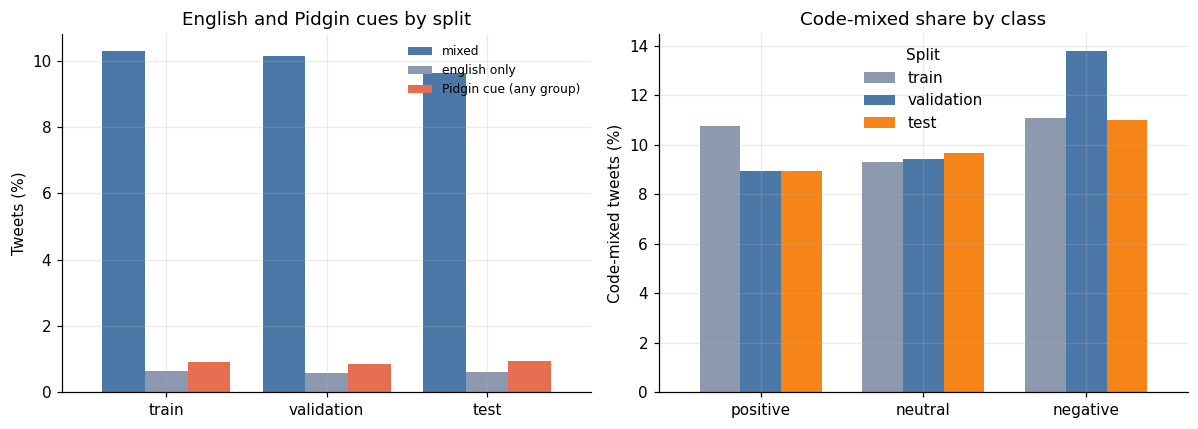

In [19]:
# [4.1] Code-mixing: English and Pidgin cues in the aligned text
ENGLISH_CUES = {w for w in sklearn.feature_extraction.text.ENGLISH_STOP_WORDS
                if len(w) >= 3 and w.isascii() and w not in {"de", "con", "ere"}}
PIDGIN_CUES = {"wetin", "dey", "abeg", "wahala", "una", "oga", "sabi", "pikin", "comot", "nau", "sef"}
YORUBA_FUNCTION = {"ni", "ti", "si", "pelu", "lati", "ati", "nigba", "nitori", "ohun", "awon", "gbogbo",
                   "ki", "pe", "wipe", "ninu", "lori", "sugbon", "boya", "nko", "tun"}

def mixing_features(text):
    toks = text.split()
    plain = [strip_marks(t) for t in toks]
    marked = [p != t for p, t in zip(plain, toks)]
    english = [t for t, m in zip(toks, marked) if not m and t in ENGLISH_CUES]
    return {
        "english_cues": len(english),
        "english_cue_words": " ".join(english),
        "yoruba_evidence": any(m or p in YORUBA_FUNCTION for p, m in zip(plain, marked)),
        "pidgin_cues": sum(p in PIDGIN_CUES for p in plain),
    }

GROUP_ORDER = ["no English cue", "mixed", "english only"]
mixing = {}
for split in SPLITS:
    m = pd.DataFrame([mixing_features(t) for t in frames[split]["text_aligned"]])
    m["group"] = np.select([(m["english_cues"] > 0) & m["yoruba_evidence"], m["english_cues"] > 0],
                           ["mixed", "english only"], default="no English cue")
    m["has_pidgin_cue"] = m["pidgin_cues"] > 0
    m["label_name"] = frames[split]["label_name"].to_numpy()
    m["has_tone_mark"] = profile[split]["has_tone_mark"].to_numpy()
    mixing[split] = m
    frames[split]["mix_group"] = m["group"].to_numpy()
    frames[split]["has_pidgin_cue"] = m["has_pidgin_cue"].to_numpy()
    frames[split]["has_tone_mark"] = m["has_tone_mark"].to_numpy()

# 1) Share of tweets in each group, by split.
by_split = pd.DataFrame({s: mixing[s]["group"].value_counts(normalize=True).mul(100) for s in SPLITS})
by_split = by_split.reindex(GROUP_ORDER).fillna(0)
by_split.loc["Pidgin cue (any group)"] = [100 * mixing[s]["has_pidgin_cue"].mean() for s in SPLITS]
print("Share of tweets (%) by code-mixing group")
display(by_split.round(1))

# 2) The same shares by class.
order = ["positive", "neutral", "negative"]
by_class = pd.concat({s: pd.crosstab(mixing[s]["label_name"], mixing[s]["group"], normalize="index").mul(100)
                      .reindex(index=order, columns=GROUP_ORDER).fillna(0) for s in SPLITS}, axis=1)
print("Share of tweets (%) by class and group")
display(by_class.round(1))

# 3) Which English words trigger the detector? (training split)
cue_counts = pd.Series(" ".join(mixing["train"]["english_cue_words"]).split()).value_counts()
print("The 25 most frequent English cue words in the training split (occurrences)")
display(cue_counts.head(25).to_frame("occurrences").T)

# 4) Do tweets without tone marks carry more or fewer English cues?
print("Share of tweets (%) in each group, tweets with and without a tone mark (training split)")
display(pd.crosstab(mixing["train"]["has_tone_mark"].map({True: "has tone mark", False: "no tone mark"}),
                    mixing["train"]["group"], normalize="index").mul(100).reindex(columns=GROUP_ORDER).round(1))

# 5) Random examples of each group, to judge the detector by eye.
for group in ["mixed", "english only", "no English cue"]:
    pool = frames["train"][frames["train"]["mix_group"] == group]
    print(f"\n--- {group}: {len(pool)} tweets in the training split, 6 random examples ---")
    for i in pool.sample(min(6, len(pool)), random_state=SEED).index:
        cues = mixing["train"].loc[i, "english_cue_words"]
        print(f"  [{frames['train'].loc[i, 'label_name']}] {frames['train'].loc[i, 'text_aligned'][:140]}"
              + (f"   <- cues: {cues}" if cues else ""))

# Figure
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
by_split.loc[GROUP_ORDER[1:] + ["Pidgin cue (any group)"]].T.plot.bar(ax=axes[0], rot=0, width=0.8,
                                                                     color=["#4c78a8", "#8d99ae", "#e76f51"])
axes[0].set_ylabel("Tweets (%)"); axes[0].set_xlabel(""); axes[0].set_title("English and Pidgin cues by split")
axes[0].legend(frameon=False, fontsize=8)
mixed_by_class = pd.DataFrame({s: by_class[s]["mixed"] for s in SPLITS})
mixed_by_class.plot.bar(ax=axes[1], rot=0, width=0.75, color=["#8d99ae", "#4c78a8", "#f58518"])
axes[1].set_ylabel("Code-mixed tweets (%)"); axes[1].set_xlabel(""); axes[1].set_title("Code-mixed share by class")
axes[1].legend(title="Split", frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "step4_code_mixing.png", bbox_inches="tight")
plt.show()

### What 4.1 tells us

**How common is code-mixing?** About 1 tweet in 10 has English mixed into the Yoruba: 10.3% of train, 10.1% of validation and 9.6% of test. The share is almost the same in all three splits, so a code-mixed slice of the test set is a fair sample of what the model saw in training. Tweets that are English only are 0.6% in every split, and tweets with a Pidgin cue are 0.9%.

**Treat 10% as a lower bound.** The detector only looks for English function words (the, and, you, not, for). Some tweets in the "no English cue" group still contain English content words, such as "thecable" and "month" in the examples above. So "no English cue" means "not detected", not "pure Yoruba". The real share of mixing is higher. This is fine for the experiment, because the flagged group is clean (the mixed examples really do mix), but I will say in the report that the detector is conservative.

**Possible noise in the cue list.** Words such as "one", "all", "see", "how" and "whoever" appear among the top cue words. They could be real English, but they are also short and might be homographs of Yoruba or name fragments. The top words ("the" 526, "and" 146, "you" 134, "not" 118, "for" 108) are clearly English, so the group is mostly right. A manual check of flagged tweets was planned but not completed, so the detector remains an unverified proxy.

**Does mixing relate to sentiment?** Only weakly. In train, the mixed share is 10.8% for positive, 9.3% for neutral and 11.1% for negative. Test shows the same order (8.9, 9.7, 11.0). Validation shows a bigger gap for negative (13.8%), but with the other two splits showing only 1 to 2 points, I will not treat mixing as a sentiment cue. Any difference in model scores on this slice will come from how hard the text is, not from a hidden label pattern.

**Tone marks and mixing are tied together.** Of tweets with a tone mark, 11.4% are mixed and none are English only. Of tweets without a tone mark, 6.5% are mixed and 2.7% are English only. Two lessons follow:
1. English-only tweets have no tone marks because English has none, not because the writer dropped them. So the "no tone mark" group in the diacritic experiment contains a small number of tweets that are not Yoruba at all.
2. Mixed tweets with tone marks contain real Yoruba, which is the case we most want to test.

**Decision.** "Code-mixed" for the later experiments means `mix_group == "mixed"`. English-only and Pidgin tweets are too few to score reliably (see 4.3), so I will show them as examples only.

### 4.2 Negation
In Yoruba, negation is carried by small words and clitics. The standard marker is "kò", and "kì í" negates habitual actions. "kọ́" negates a focused phrase ("it is not ..."), "má" forbids ("do not ..."), "rárá" means "no" or "not at all", and a low-tone "ò" after a pronoun negates the verb ("mi ò" is "I do not"). These words are written with tone marks and underdots, and tweets often drop them, so the same word then looks like "ko", "kii" or "rara", and "ko" can also be a different word altogether. I therefore keep three groups of markers apart:

- **Marked Yoruba markers**, found only where the tone marks are written: "kò", "kì í", "kìí", "kọ́", "má", "rárá" and "ò". These are the precise group.
- **Unmarked candidates**, the same words without marks: "ko", "kii" and "rara". These are ambiguous and are reported as candidates only.
- **English markers**: "not", "no", "never", "dont", "cant", "nothing" and similar words, which appear in code-mixed tweets. The alignment removed apostrophes, so "don't" appears as "dont".

I count a tweet as negated in the strong sense if it has a marked Yoruba marker or an English marker, and in the weak sense if it has any of the three groups. The future marker "ma" is left out, because it is far more often the future marker than the prohibition "má". Negation that is expressed without any of these words, for example through an antonym, is invisible to this detector.

Share of tweets (%) with each kind of negation marker


,train,validation,test
marked Yoruba marker,21.9,22.7,22.1
unmarked candidate,5.0,4.4,5.3
English marker,3.0,2.2,2.5
strong (marked or English),22.9,23.4,23.0
weak (any of the three),27.6,27.6,27.9


,group,word,occurrences
0,marked Yoruba,ò,1051
1,marked Yoruba,kò,728
2,marked Yoruba,kì í,271
3,marked Yoruba,má,210
4,marked Yoruba,kọ́,165
5,marked Yoruba,kìí,99
6,marked Yoruba,rárá,35
7,unmarked candidate,ko,451
8,unmarked candidate,kii,55
9,unmarked candidate,rara,31


Share of tweets (%) with strong and weak negation, by class


train       validation         test      
           strong  weak     strong  weak strong  weak
label_name                                           
positive     22.0  27.1       22.6  27.4   24.0  29.5
neutral      18.7  21.3       19.5  21.1   18.3  20.2
negative     31.6  39.1       31.6  39.1   29.0  37.6

Share of tweets (%) with each marker group, tweets with and without a tone mark (training split)


,marked Yoruba marker,unmarked candidate,English marker,strong (marked or English),weak (any of the three)
tone,,,,,
has tone mark,28.3,1.2,3.3,29.1,30.0
no tone mark,0.0,18.1,1.9,1.9,19.5



--- marked Yoruba marker: 1863 tweets in the training split, 6 random examples ---
  [negative] òkúta igi tàbí nǹkan míì ni a fi ń pààlè iye tọ́jà jẹ́ sórí ọ́jà ta ló jẹ́ pààlè sórí ọjà lóde ònìí tí ọ̀ṣà [[ò]] ní gbé e lọ́jà lọ
  [negative] ṣé ká [[má]] wọṣọ gidi mọ́ ni
  [positive] a ní láti gbàdúrà gigi lẹ́ẹ̀mejì baba ẹlẹ́ṣẹ̀ ni wá baba ẹ dáríjìn wá o ẹ [[má]] wo tẹ̀ṣẹ̀ mọ́n wá lára
  [negative] ìyá odó òun ọmọ rẹ̀ [[kò]] ní ìjà àgbẹ̀ ló díjà sílẹ̀ fún wọn ọmọ odó kì í na ìyá ẹ̀ lásán
  [negative] àwọn èèyàn wa pẹ̀lú ìwà ọ̀daràn èwo ni ká máa jẹ níbi tí a [[ò]] roko sí wọ́n tún ti kọ ẹyìn mi
  [neutral] àkànnàmọ̀gbò kì í pa ọdún jẹ ️ àkàlàmàgbò kì í pa ọdún jẹ àṣìpa òwe ni àkàlàmàgbò kì í pa ọdún jẹ àkànnàmọ̀gbò kì í pa ọdún jẹ ló tọ̀nà ẹ̀yà iṣu oko k

--- unmarked candidate: 427 tweets in the training split, 6 random examples ---
  [positive] mo ki gbo gbo awa omo karo oji ri ki apejo [[ko]] san wa si ire owo omo alafia ki afefe ife afefe ayo o fe s
  [negative] ogbontarigi olofofo

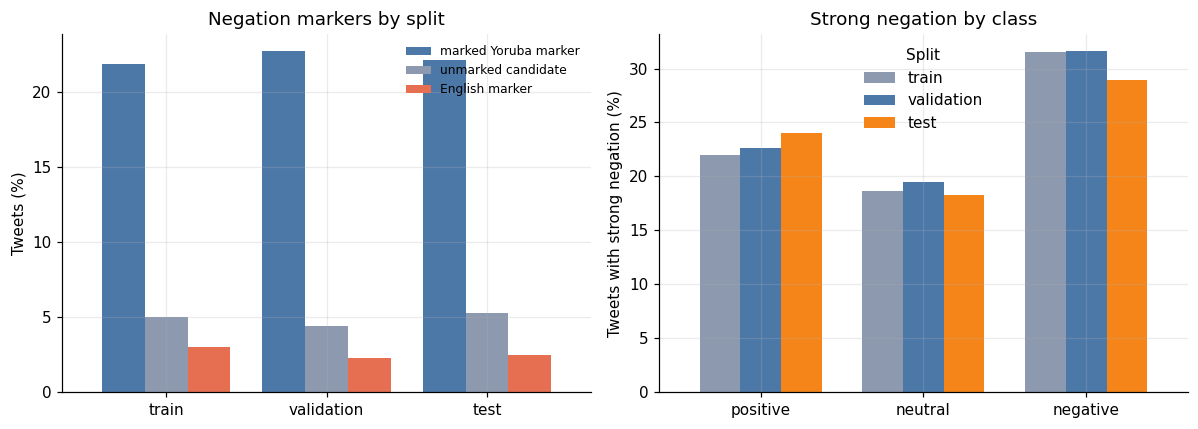

In [20]:
# [4.2] Negation: marked Yoruba markers, unmarked candidates and English markers
nfc = lambda s: unicodedata.normalize("NFC", s)
NEG_MARKED = {nfc(w) for w in ["kò", "kìí", "kọ́", "rárá", "má", "ò"]}
NEG_MARKED_BIGRAMS = {(nfc("kì"), nfc("í"))}
NEG_UNMARKED = {"ko", "kii", "rara"}
NEG_ENGLISH = {"not", "no", "never", "dont", "cant", "wont", "isnt", "didnt", "doesnt", "wasnt", "arent",
               "couldnt", "wouldnt", "shouldnt", "cannot", "nothing", "nobody", "none", "neither", "nor", "without"}

def negation_features(text):
    toks = [nfc(t) for t in text.split()]
    marked = [t for t in toks if t in NEG_MARKED] + [" ".join(b) for b in zip(toks, toks[1:]) if b in NEG_MARKED_BIGRAMS]
    unmarked = [t for t in toks if t in NEG_UNMARKED]
    english = [t for t in toks if t in NEG_ENGLISH]
    return {"neg_marked": len(marked) > 0, "neg_unmarked": len(unmarked) > 0, "neg_english": len(english) > 0,
            "hits_marked": marked, "hits_unmarked": unmarked, "hits_english": english}

negation = {}
for split in SPLITS:
    n = pd.DataFrame([negation_features(t) for t in frames[split]["text_aligned"]])
    n["neg_strong"] = n["neg_marked"] | n["neg_english"]
    n["neg_any"] = n["neg_strong"] | n["neg_unmarked"]
    n["label_name"] = frames[split]["label_name"].to_numpy()
    n["has_tone_mark"] = frames[split]["has_tone_mark"].to_numpy()
    negation[split] = n
    for col in ["neg_marked", "neg_unmarked", "neg_english", "neg_strong", "neg_any"]:
        frames[split][col] = n[col].to_numpy()

TIERS = ["neg_marked", "neg_unmarked", "neg_english", "neg_strong", "neg_any"]
TIER_NAMES = {"neg_marked": "marked Yoruba marker", "neg_unmarked": "unmarked candidate",
              "neg_english": "English marker", "neg_strong": "strong (marked or English)",
              "neg_any": "weak (any of the three)"}

# 1) Prevalence by split.
prev = pd.DataFrame({s: {TIER_NAMES[t]: 100 * negation[s][t].mean() for t in TIERS} for s in SPLITS})
print("Share of tweets (%) with each kind of negation marker")
display(prev.round(1))

# 2) Which words trigger each group? (training split)
rows = []
for col, tier in [("hits_marked", "marked Yoruba"), ("hits_unmarked", "unmarked candidate"), ("hits_english", "English")]:
    counts = pd.Series([w for hits in negation["train"][col] for w in hits]).value_counts()
    for word, k in counts.items():
        rows.append({"group": tier, "word": word, "occurrences": int(k)})
display(pd.DataFrame(rows))

# 3) Negation by class and by tone-mark use.
print("Share of tweets (%) with strong and weak negation, by class")
display(pd.concat({s: pd.DataFrame({"strong": negation[s].groupby("label_name")["neg_strong"].mean().mul(100),
                                    "weak": negation[s].groupby("label_name")["neg_any"].mean().mul(100)})
                   .reindex(order) for s in SPLITS}, axis=1).round(1))

print("Share of tweets (%) with each marker group, tweets with and without a tone mark (training split)")
tm = negation["train"].assign(tone=negation["train"]["has_tone_mark"].map({True: "has tone mark", False: "no tone mark"}))
display(tm.groupby("tone")[TIERS].mean().mul(100).rename(columns=TIER_NAMES).round(1))

# 4) Random examples of each group, with the matching words in double brackets.
def highlight(text, words):
    words = set(words)
    return " ".join(f"[[{t}]]" if nfc(t) in words else t for t in text.split())

for col, hits in [("neg_marked", "hits_marked"), ("neg_unmarked", "hits_unmarked"), ("neg_english", "hits_english")]:
    pool = negation["train"][negation["train"][col]]
    print(f"\n--- {TIER_NAMES[col]}: {len(pool)} tweets in the training split, 6 random examples ---")
    for i in pool.sample(min(6, len(pool)), random_state=SEED).index:
        print(f"  [{frames['train'].loc[i, 'label_name']}] {highlight(frames['train'].loc[i, 'text_aligned'], negation['train'].loc[i, hits])[:150]}")

# Figure
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
prev.T[[TIER_NAMES[t] for t in TIERS[:3]]].plot.bar(ax=axes[0], rot=0, width=0.8, color=["#4c78a8", "#8d99ae", "#e76f51"])
axes[0].set_ylabel("Tweets (%)"); axes[0].set_xlabel(""); axes[0].set_title("Negation markers by split")
axes[0].legend(frameon=False, fontsize=8)
strong_by_class = pd.DataFrame({s: negation[s].groupby("label_name")["neg_strong"].mean().mul(100).reindex(order) for s in SPLITS})
strong_by_class.plot.bar(ax=axes[1], rot=0, width=0.75, color=["#8d99ae", "#4c78a8", "#f58518"])
axes[1].set_ylabel("Tweets with strong negation (%)"); axes[1].set_xlabel(""); axes[1].set_title("Strong negation by class")
axes[1].legend(title="Split", frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "step4_negation.png", bbox_inches="tight")
plt.show()

### What 4.2 tells us

**How common is negation?** The strong flag (a marked Yoruba negator or an English negator) covers 22.9% of train, 23.4% of validation and 23.0% of test. The weak flag (which also includes unmarked `ko`, `kii`, `rara`) covers 27.6%, 27.6% and 27.9%. The shares are stable across splits, so negation is a real slice of the data, about 1 tweet in 4.

**What drives the flag?** Yoruba markers do almost all the work. `ò` (1051 hits) and `kò` (728) are the two biggest triggers, followed by `kì í` (271), `má` (210) and `kọ́` (165). English markers add only about 1 point (22.9% strong against 21.9% marked), with "not" (118) and "no" (79) leading. Because `ò` and `má` are short and can have other uses, these cues may be noisy; no reader check was completed.

**Negation is more common in negative tweets, but most negated tweets are not negative.** In train, strong negation appears in 31.6% of negative tweets, against 22.0% of positive and 18.7% of neutral. Test shows the same order (29.0, 24.0, 18.3). A model could learn "negation means negative". But the 4.3 table shows that among strong-negation tweets in test_unseen, only 28.2% are negative, while 43.1% are positive and 28.6% are neutral. Proverbs and encouraging phrases ("do not fear") are negated and positive. This is exactly where a bag-of-words baseline should struggle, and it is why negation is worth testing as its own experiment.

**The detector depends on tone marks.** Among tweets with a tone mark, 28.3% have a marked negator. Among tweets without one, it is 0.0%, because the marked words cannot be written without tone marks. So the strong flag is 29.1% in toned tweets and only 1.9% in untoned tweets. The weak flag finds 19.5% in untoned tweets, but 18.1 points of that come from unmarked `ko`, `kii`, `rara`, and `ko` can also be an ordinary word (the examples show "ko san wa si ire", which is not clearly negation).

Two consequences for later:
1. Comparing "negated vs not negated" is partly a comparison of "toned vs untoned". I will compare inside toned tweets, or report both, so the two effects are not mixed up.
2. The weak flag is noisier, so the strong flag is the main negation subset and the weak flag is a robustness check.

**Open check.** A reader review of strong-flagged and unflagged tweets was planned but not completed, so the detector’s precision is unknown.

### 4.3 How many tweets each difficulty covers in the evaluation sets
A score on a subset is only informative if the subset holds enough tweets. In the modelling stage I report each model's scores on the code-mixed tweets, the tweets with negation and the tweets without tone marks, so I need to know now how large those subsets are in the evaluation sets I use. I count them in `validation_unseen` and `test_unseen`, give the class mix of the test subsets, and compute the worst-case margin on an accuracy measured on that many tweets (about 98 divided by the square root of the subset size, in percentage points). Subsets whose margin is wide are reported with that caution. I also save the flags with the data.

,validation_unseen,test_unseen,share_of_test_%,pos_%,neu_%,neg_%,accuracy_margin_pp
subset,,,,,,,
all tweets,1784,3938,100.0,41.8,36.1,22.1,1.6
code-mixed (English cue),166,359,9.1,37.9,36.8,25.3,5.2
English only,12,22,0.6,54.5,27.3,18.2,20.9
Pidgin cue,15,34,0.9,38.2,14.7,47.1,16.8
strong negation,416,932,23.7,43.1,28.6,28.2,3.2
weak negation,487,1118,28.4,43.4,26.5,30.1,2.9
no tone mark,388,808,20.5,47.3,22.6,30.1,3.4
code-mixed and strong negation,51,111,2.8,42.3,24.3,33.3,9.3
no tone mark and weak negation,65,171,4.3,42.7,15.8,41.5,7.5


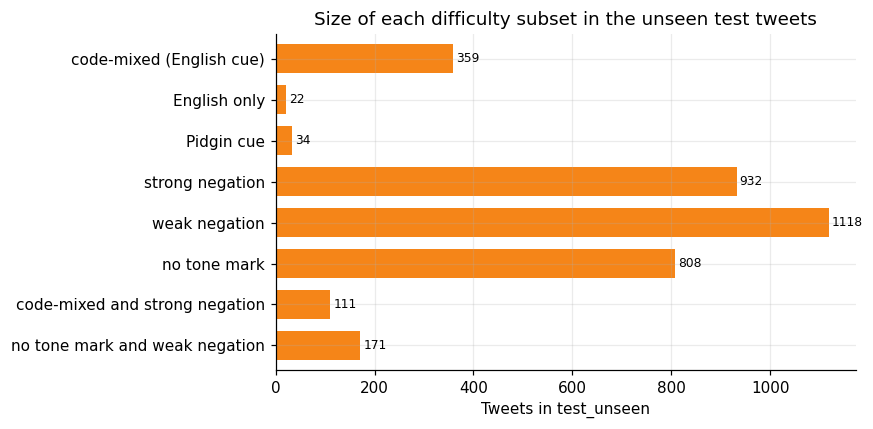

In [21]:
# [4.3] Size of each difficulty subset in the evaluation sets, and a checkpoint of the flags
EVAL_SETS = build_eval_sets(frames)      # rebuilt so that the new flag columns are included

SUBSETS = {
    "all tweets":                      lambda d: d["tweet"].notna(),
    "code-mixed (English cue)":        lambda d: d["mix_group"] == "mixed",
    "English only":                    lambda d: d["mix_group"] == "english only",
    "Pidgin cue":                      lambda d: d["has_pidgin_cue"],
    "strong negation":                 lambda d: d["neg_strong"],
    "weak negation":                   lambda d: d["neg_any"],
    "no tone mark":                    lambda d: ~d["has_tone_mark"],
    "code-mixed and strong negation":  lambda d: (d["mix_group"] == "mixed") & d["neg_strong"],
    "no tone mark and weak negation":  lambda d: (~d["has_tone_mark"]) & d["neg_any"],
}
rows = []
for name, rule in SUBSETS.items():
    v, t = EVAL_SETS["validation_unseen"], EVAL_SETS["test_unseen"]
    sub_v, sub_t = v[rule(v)], t[rule(t)]
    mix = sub_t["label_name"].value_counts(normalize=True).mul(100).reindex(order).fillna(0)
    rows.append({"subset": name, "validation_unseen": len(sub_v), "test_unseen": len(sub_t),
                 "share_of_test_%": round(100 * len(sub_t) / len(t), 1),
                 "pos_%": round(mix["positive"], 1), "neu_%": round(mix["neutral"], 1), "neg_%": round(mix["negative"], 1),
                 "accuracy_margin_pp": round(98 / max(len(sub_t), 1) ** 0.5, 1)})
sizes = pd.DataFrame(rows).set_index("subset")
display(sizes)

ax = sizes["test_unseen"].iloc[1:].plot.barh(figsize=(8, 4), color="#f58518", width=0.7)
for container in ax.containers:
    ax.bar_label(container, fmt="%d", fontsize=8, padding=2)
ax.invert_yaxis()
ax.set_xlabel("Tweets in test_unseen")
ax.set_ylabel("")
ax.set_title("Size of each difficulty subset in the unseen test tweets")
plt.tight_layout()
plt.savefig(FIG_DIR / "step4_subset_sizes.png", bbox_inches="tight")
plt.show()

save_frames("step4_flags", frames)

### What 4.3 tells us

The "margin" column is the worst-case 95% margin of error on accuracy, in percentage points (98 divided by the square root of the subset size). It shows how much a score on that subset can wobble from sampling alone.

**Subsets big enough to trust (test_unseen):**
- code-mixed: 359 tweets, margin 5.2 points
- strong negation: 932 tweets, margin 3.2 points
- weak negation: 1118 tweets, margin 2.9 points
- no tone mark: 808 tweets, margin 3.4 points

A difference between two models on these slices needs to be clearly larger than the margin before I call it real.

**Subsets to use with caution:**
- code-mixed and strong negation: 111 tweets (margin 9.3)
- no tone mark and weak negation: 171 tweets (margin 7.5)

I will report these but not draw conclusions from them.

**Subsets too small to score:**
- English only: 22 tweets (margin 20.9)
- Pidgin cue: 34 tweets (margin 16.8)

I will show examples of these in the error analysis, not scores.

**Validation is too small for subsets.** The validation_unseen slices are 166 (code-mixed), 416 (strong negation) and 388 (no tone mark). That is too few for choosing models, so the validation set is used for overall model selection only, and subset results are reported on test_unseen.

**The class mix differs between subsets.** The overall mix is 41.8% positive, 36.1% neutral and 22.1% negative. The no-tone-mark subset is only 22.6% neutral, but 47.3% positive and 30.1% negative. The Pidgin subset is 47.1% negative. So a lower score on a subset can come from a different label mix, not only from the language problem. For this reason I will report per-class F1 and macro-F1 on each subset, not accuracy alone.

**Saved.** The flags are stored in the `step4_flags` checkpoint, so later notebooks can score every model on these subsets without recomputing anything.

## Step 5. Baselines

### 5.1 A scoring function and the majority-class baseline

**Why.** A score means nothing without a reference point. Before training any model, I need one fixed way to score predictions, used for every model from now on, and a floor that any real model must beat. The floor is a "model" that always predicts the most common training label. It learns nothing about language, so whatever it scores is what pure class balance gives for free.

**What I measure.** Accuracy, macro-F1 (the main metric, because it gives each class equal weight even though negative is the smallest class) and the F1 of each class. I score every evaluation set from Step 3 (validation and test, all, unseen and seen), so later cells can reuse the same table.

**What I will look for.** Whether accuracy looks respectable while macro-F1 is poor. If it does, that is the reason macro-F1 is the main metric.

In [22]:

# [5.1] Scoring function and majority-class baseline
from sklearn.metrics import accuracy_score, f1_score
LABEL_IDS = [0, 1, 2]

def score(y_true, y_pred):
    per_class = f1_score(y_true, y_pred, labels=LABEL_IDS, average=None, zero_division=0)
    row = {
        "n": len(y_true),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, labels=LABEL_IDS, average="macro", zero_division=0),
    }
    for i, f in zip(LABEL_IDS, per_class):
        row[f"f1_{label_names[i]}"] = f
    return row

majority_label = int(frames["train"]["label"].mode().iloc[0])
print("Majority label in train:", majority_label, "=", label_names[majority_label])

rows = {}
for name, df in EVAL_SETS.items():
    preds = np.full(len(df), majority_label)
    rows[name] = score(df["label"].to_numpy(), preds)

majority_table = pd.DataFrame(rows).T
majority_table["n"] = majority_table["n"].astype(int)
display(majority_table.round(3))

save_json("baseline_majority", {k: {m: float(v) for m, v in r.items()} for k, r in rows.items()})

Majority label in train: 0 = positive


,n,accuracy,macro_f1,f1_positive,f1_neutral,f1_negative
validation_all,2090,0.423,0.198,0.594,0.0,0.0
validation_unseen,1784,0.419,0.197,0.590,0.0,0.0
validation_seen,306,0.448,0.206,0.619,0.0,0.0
test_all,4515,0.425,0.199,0.596,0.0,0.0
test_unseen,3938,0.418,0.197,0.590,0.0,0.0
test_seen,577,0.470,0.213,0.639,0.0,0.0


### What 5.1 tells us

**The floor.** Always predicting "positive" gives 0.425 accuracy and 0.199 macro-F1 on test_all, and 0.418 and 0.197 on test_unseen. These are the numbers any real model has to beat. On validation_unseen, which I use to choose models, the floor is 0.419 accuracy and 0.197 macro-F1.

**Why macro-F1 is the main metric.** Accuracy of 0.425 sounds like a weak but real result. Macro-F1 of 0.199 shows what it is: a model that gets 0.594 F1 on the positive class and exactly 0.0 on neutral and negative. It has not learned anything about Yoruba. Accuracy hides this. Macro-F1 does not, because it averages the three classes equally. Any model I report must show nonzero F1 on neutral and negative before its accuracy means anything.

**The accuracy of this baseline equals the positive share.** Always predicting positive is right exactly when the tweet is positive, so the accuracy column is also the share of positive tweets in each set. That share is 0.419 in validation_unseen and 0.418 in test_unseen, but it is higher in the seen sets: 0.448 in validation_seen and 0.470 in test_seen. So the tweets that have a copy in training lean positive. This means that when I compare seen against unseen scores later, part of any gap can come from a different label mix, not only from memorization. I will compare macro-F1 and per-class F1, not accuracy alone.

**Unseen validation and unseen test behave alike.** The floor is 0.197 on both, so scores on validation_unseen are a fair guide to scores on test_unseen.

### 5.2 Word TF-IDF with logistic regression

**Why.** The floor is 0.199 macro-F1, so I now need the simplest model that actually reads the text. TF-IDF turns each tweet into word weights, and logistic regression learns which words point to which class. It trains in seconds and has no pretrained knowledge, so whatever it learns comes only from the 8,522 training tweets. This shows how far plain word counts can go before I use a large pretrained model.

**Choices I made, and why.**
- It trains on `text_aligned`, the cleaned text from Step 3, matching the format of the test split.
- Words are split on spaces only (`\S+`). The default tokenizer breaks words at tone marks, because a tone mark is a combining character and is not treated as part of a word. That would damage Yoruba words such as `kọ́`.
- One- and two-word sequences are used, so short phrases such as `kò dára` can be seen.
- `class_weight="balanced"` stops the model from ignoring negative, the smallest class.
- Words must appear in at least 2 training tweets, to drop one-off typos.

**What I will look for.** Whether macro-F1 rises well above 0.199, which class is hardest, and how big the gap is between the training score and the validation_unseen score. That gap tells me whether the next step should be more regularization or a different kind of features.

In [23]:
# [5.2] Word TF-IDF + logistic regression, trained on text_aligned
tfidf_word_lr = Pipeline([
    ("tfidf", TfidfVectorizer(analyzer="word", token_pattern=r"\S+", ngram_range=(1, 2),
                              min_df=2, sublinear_tf=True)),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)),
])
tfidf_word_lr.fit(frames["train"]["text_aligned"], frames["train"]["label"])

rows = {"train": score(frames["train"]["label"].to_numpy(),
                       tfidf_word_lr.predict(frames["train"]["text_aligned"]))}
for name, df in EVAL_SETS.items():
    rows[name] = score(df["label"].to_numpy(), tfidf_word_lr.predict(df["text_aligned"]))

word_lr_table = pd.DataFrame(rows).T
word_lr_table["n"] = word_lr_table["n"].astype(int)
display(word_lr_table.round(3))

n_features = len(tfidf_word_lr.named_steps["tfidf"].vocabulary_)
print("Vocabulary size:", n_features)
print("Majority floor macro-F1 on validation_unseen:", round(majority_table.loc["validation_unseen", "macro_f1"], 3))

save_json("baseline_word_lr", {k: {m: float(v) for m, v in r.items()} for k, r in rows.items()})

,n,accuracy,macro_f1,f1_positive,f1_neutral,f1_negative
train,8522,0.918,0.916,0.928,0.912,0.908
validation_all,2090,0.739,0.724,0.794,0.736,0.642
validation_unseen,1784,0.712,0.696,0.772,0.710,0.606
validation_seen,306,0.895,0.892,0.917,0.879,0.880
test_all,4515,0.745,0.733,0.805,0.733,0.660
test_unseen,3938,0.720,0.708,0.782,0.711,0.632
test_seen,577,0.913,0.908,0.939,0.889,0.896


Vocabulary size: 25759
Majority floor macro-F1 on validation_unseen: 0.197


### What 5.2 tells us

**A real model, far above the floor.** On validation_unseen, macro-F1 is 0.696 against the floor of 0.197, and on test_unseen it is 0.708 against 0.197. Unlike the majority baseline, every class now has a real score. Plain word counts already carry most of the signal in this dataset.

**It overfits.** Macro-F1 is 0.916 on the training tweets and 0.696 on validation_unseen, a gap of 0.220. The vocabulary has 25,759 entries (words and word pairs) learned from only 8,522 tweets, so the model has more features than examples and can memorize. Next I should test stronger regularization, and features that generalize better than whole words.

**Negative is the hardest class.** F1 on validation_unseen is 0.772 for positive, 0.710 for neutral and 0.606 for negative. The test_unseen pattern is the same (0.782, 0.711, 0.632). Negative is the smallest class (about 22% of tweets) and, from 4.2, it is also the class where negation is most common, so a model that only counts words has the most trouble there.

**Memorization is visible.** On tweets that also appear in training, macro-F1 is 0.892 on validation_seen and 0.908 on test_seen. On unseen tweets it is 0.696 and 0.708. That is a gap of about 0.20 in both splits. The seen tweets lean positive (Step 5.1), but the model scores about 0.88 to 0.94 F1 on all three classes there, so the gap is memorization and not a label-mix effect.

**Why test_unseen is the headline number.** Scored on all test tweets, the model gets 0.733 macro-F1. On test_unseen it gets 0.708. The 0.025 difference is the memorization of the 577 seen tweets, so reporting test_all alone would flatter the model. I will report test_unseen as the main score and test_all next to it.

**Decision for 5.3.** The overfitting points to two things worth testing, both on validation_unseen only: how strongly to regularize, and whether character n-grams (which can match a word across spelling and tone-mark variants) help over whole words.

### 5.3 Choosing features and regularization on validation_unseen

**Why.** 5.2 showed a training score of 0.916 against 0.696 on validation_unseen. Two settings can change that. The first is the regularization strength `C` (smaller `C` means a simpler model). The second is the kind of features: whole words, character n-grams (pieces of 2 to 5 characters inside words), or both. Character n-grams should help in Yoruba, because the same word appears with and without tone marks and with spelling variants, and pieces of the word still match.

**Rules for a fair comparison.**
- Each setting is trained on the training split only.
- The setting is chosen by macro-F1 on validation_unseen. The test set is not touched in this cell.
- I keep the train-minus-validation gap next to each score, to see whether a gain comes from a better model or only from a more memorizing one.

**What I will look for.** Whether character features beat words, which `C` is best, and whether the gap shrinks.

In [24]:
from sklearn.pipeline import FeatureUnion

# [5.3] Feature type x regularization strength, chosen on validation_unseen only
def make_features(kind):
    word = TfidfVectorizer(analyzer="word", token_pattern=r"\S+", ngram_range=(1, 2),
                           min_df=2, sublinear_tf=True)
    char = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)
    if kind == "word":
        return word
    if kind == "char":
        return char
    return FeatureUnion([("word", word), ("char", char)])

X_train, y_train = frames["train"]["text_aligned"], frames["train"]["label"].to_numpy()
val_u = EVAL_SETS["validation_unseen"]

grid_rows = []
for kind in ["word", "char", "word+char"]:
    for C in [0.3, 1, 3, 10]:
        model = Pipeline([
            ("features", make_features(kind)),
            ("clf", LogisticRegression(C=C, max_iter=2000, class_weight="balanced", random_state=SEED)),
        ])
        model.fit(X_train, y_train)
        tr = score(y_train, model.predict(X_train))
        va = score(val_u["label"].to_numpy(), model.predict(val_u["text_aligned"]))
        grid_rows.append({"features": kind, "C": C,
                          "train_macro_f1": tr["macro_f1"],
                          "val_unseen_macro_f1": va["macro_f1"],
                          "gap": tr["macro_f1"] - va["macro_f1"],
                          "val_f1_negative": va["f1_negative"]})

grid = pd.DataFrame(grid_rows)
display(grid.round(3))
display(grid.pivot(index="features", columns="C", values="val_unseen_macro_f1").round(3))

best = grid.sort_values("val_unseen_macro_f1", ascending=False).iloc[0]
print("Best on validation_unseen:", best["features"], "with C =", best["C"],
      "-> macro-F1", round(best["val_unseen_macro_f1"], 3))

save_json("baseline_grid", grid.to_dict(orient="records"))

,features,C,train_macro_f1,val_unseen_macro_f1,gap,val_f1_negative
0,word,0.3,0.823,0.676,0.147,0.591
1,word,1.0,0.916,0.696,0.220,0.606
2,word,3.0,0.979,0.697,0.282,0.595
3,word,10.0,0.997,0.709,0.289,0.620
4,char,0.3,0.798,0.693,0.105,0.601
5,char,1.0,0.882,0.714,0.168,0.619
6,char,3.0,0.949,0.714,0.235,0.610
7,char,10.0,0.989,0.706,0.283,0.602
8,word+char,0.3,0.874,0.704,0.170,0.616
9,word+char,1.0,0.956,0.716,0.240,0.615


C,0.3,1.0,3.0,10.0
features,,,,
char,0.693,0.714,0.714,0.706
word,0.676,0.696,0.697,0.709
word+char,0.704,0.716,0.717,0.717


Best on validation_unseen: word+char with C = 3.0 -> macro-F1 0.717


### What 5.3 tells us

**Combining words and characters helps a little.** On validation_unseen, the best setting is word plus character features with C = 3, at macro-F1 0.717. The 5.2 model (words only, C = 1) scored 0.696, so tuning bought about 0.02.

**Where the gain comes from.**
- Character features alone (0.714 at C = 1 and at C = 3) beat word features alone at the same C (0.696 and 0.697). This fits the idea that pieces of words match across spelling and tone-mark variants, which whole words cannot do.
- Words alone only catch up at the weakest regularization, 0.709 at C = 10.
- Adding words to characters gives 0.716 to 0.717 for C from 1 to 10, only about 0.003 above characters alone.

**Differences this small should not be read as real.** The three best cells (word plus character at C = 1, 3 and 10, all about 0.717) and the best character-only cell (0.714) are within noise on a 1,784-tweet set. I treat them as a tie, and I break the tie by choosing the stronger regularization, C = 3, because it should overfit less. Also, 12 settings were compared on the same set, so 0.717 is slightly optimistic. The test set will give the honest number.

**Too little regularization hurts.** C = 0.3 gives the lowest score for every feature type (0.693, 0.676 and 0.704). A model that simple underfits.

**A plateau.** Across all three feature types, the best scores sit between 0.709 and 0.717. Bag-of-words and character models have run into a ceiling of about 0.72 on this data. A model that understands Yoruba beyond the 8,522 training tweets is the next thing to try, and it is where the larger gains should come from.

**Decision.** I keep word plus character features with C = 3 as the final classical baseline. Next, I score it once on all evaluation sets, including the test set, and put the three results side by side.

### 5.4 Final classical baseline: scores, uncertainty and comparison

**Why.** The setting is chosen, so I freeze it and score it on every evaluation set. This is the first time the tuned baseline meets the test set, and no setting will change after seeing these numbers. I also add a bootstrap 95% interval (resampling the evaluation tweets 1,000 times), so I can later say whether a difference between two models is bigger than sampling noise. The fitted model is saved, so the app and later notebooks can reuse it.

**What I will look for.** How the tuned baseline compares with the floor and with the 5.2 model on every set, how wide the intervals are, and whether the seen versus unseen gap is still there.

In [25]:
# [5.4] Freeze the chosen classical baseline, score it everywhere, add bootstrap intervals
BEST = {"features": "word+char", "C": 3}

final_baseline = Pipeline([
    ("features", make_features(BEST["features"])),
    ("clf", LogisticRegression(C=BEST["C"], max_iter=2000, class_weight="balanced", random_state=SEED)),
])
final_baseline.fit(X_train, y_train)

preds = {name: final_baseline.predict(df["text_aligned"]) for name, df in EVAL_SETS.items()}
rows = {name: score(df["label"].to_numpy(), preds[name]) for name, df in EVAL_SETS.items()}
tuned_table = pd.DataFrame(rows).T
tuned_table["n"] = tuned_table["n"].astype(int)
display(tuned_table.round(3))

comparison = pd.DataFrame({
    "majority floor": majority_table["macro_f1"],
    "word LR, C=1 (5.2)": word_lr_table["macro_f1"].drop("train"),
    "word+char LR, C=3 (5.3)": tuned_table["macro_f1"],
})
display(comparison.round(3))

def bootstrap_ci(y_true, y_pred, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        vals.append(f1_score(y_true[idx], y_pred[idx], labels=LABEL_IDS, average="macro", zero_division=0))
    return np.percentile(vals, [2.5, 97.5])

for name in ["validation_unseen", "test_unseen", "test_all"]:
    y = EVAL_SETS[name]["label"].to_numpy()
    lo, hi = bootstrap_ci(y, preds[name])
    print(f"{name}: macro-F1 {tuned_table.loc[name, 'macro_f1']:.3f}  (95% interval {lo:.3f} to {hi:.3f})")

joblib.dump(final_baseline, CKPT_DIR / "baseline_word_char_lr.joblib")
save_json("baseline_final", {"setting": BEST,
                             "scores": {k: {m: float(v) for m, v in r.items()} for k, r in rows.items()}})

,n,accuracy,macro_f1,f1_positive,f1_neutral,f1_negative
validation_all,2090,0.767,0.749,0.814,0.778,0.656
validation_unseen,1784,0.735,0.717,0.786,0.749,0.615
validation_seen,306,0.951,0.947,0.964,0.945,0.931
test_all,4515,0.767,0.753,0.824,0.757,0.678
test_unseen,3938,0.740,0.726,0.800,0.733,0.645
test_seen,577,0.951,0.949,0.963,0.938,0.946


,majority floor,"word LR, C=1 (5.2)","word+char LR, C=3 (5.3)"
validation_all,0.198,0.724,0.749
validation_unseen,0.197,0.696,0.717
validation_seen,0.206,0.892,0.947
test_all,0.199,0.733,0.753
test_unseen,0.197,0.708,0.726
test_seen,0.213,0.908,0.949


validation_unseen: macro-F1 0.717  (95% interval 0.695 to 0.738)
test_unseen: macro-F1 0.726  (95% interval 0.712 to 0.739)
test_all: macro-F1 0.753  (95% interval 0.740 to 0.766)


### What 5.4 tells us

**The classical baseline.** On test_unseen, the frozen word plus character model reaches macro-F1 0.726 (95% interval 0.712 to 0.739) and accuracy 0.740. On all test tweets it reaches 0.753 (0.740 to 0.766). The floor was 0.197, so the model is more than three times better.

**No sign of over-tuning.** I chose the setting on validation_unseen (0.717, interval 0.695 to 0.738). Test_unseen, which the setting never saw, scores 0.726, inside that interval. If the choice had been lucky, the test score would have fallen below the validation score.

**Is the tuned model really better than the 5.2 model?** On test_unseen the score moved from 0.708 to 0.726, a gain of 0.018. The interval around 0.726 is about 0.027 wide, so I call this a small gain that is probably real but not proven. It is not a result I will build a claim on.

**Negative is still the weak class.** On test_unseen the F1 is 0.800 for positive, 0.733 for neutral and 0.645 for negative. On validation_unseen the values are 0.786, 0.749 and 0.615. In both splits negative trails the others by 0.09 to 0.13.

**Memorization got stronger, not weaker.** The tuned model scores 0.947 (validation_seen) and 0.949 (test_seen) on tweets that also occur in training, against 0.717 and 0.726 on unseen ones, a gap of about 0.22 to 0.23. The 5.2 model had a gap of about 0.20. Character features gave the model more ways to recognize a tweet it has already seen, so the gain on unseen tweets (+0.018 on test_unseen) came with a bigger gain on seen ones (+0.041). This confirms that test_all (0.753) flatters the model, and test_unseen (0.726) is the honest score to report.

**Where this leaves us.** This is the final classical baseline: macro-F1 0.726 on test_unseen. Tuning features and regularization gave about 0.02, and no setting in 5.3 broke through 0.72, so the plan is to try a pretrained language model that has seen Yoruba text.

## Step 6. Pretrained encoders

### 6.1 Which pretrained model, and how does its tokenizer treat Yoruba?

**Why.** The classical baseline has plateaued at about 0.72, and it knows nothing about Yoruba beyond the 8,522 training tweets. A pretrained encoder has read a large amount of text in many languages and can bring that knowledge to this task. But a pretrained model only helps if it has seen Yoruba, and if its tokenizer does not shred Yoruba words into meaningless pieces.

**Candidates.** From their model cards: AfroXLMR-base (Davlan/afro-xlmr-base) was adapted on 17 African languages including Yoruba, plus Arabic, French and English, under an MIT license. AfriBERTa-base (castorini/afriberta_base) was pretrained on 11 African languages including Yoruba, and is smaller (about 111 million parameters). I also include a general multilingual model (xlm-roberta-base) as a reference, to see what a model that was not built for African languages does with the same text.

**What I measure, before spending GPU time.**
- Tokens per word: lower means the tokenizer recognizes Yoruba words, higher means it cuts them into many small pieces.
- The share of unknown tokens.
- How long tweets get in tokens, so I can choose a maximum length that does not cut many tweets.
- All of the above on the text with tone marks and with tone marks removed. This matters for the missing-tone-mark experiment, because a tokenizer that splits `kọ́` into pieces will see a very different input once the marks are gone.

**What I will look for.** Which tokenizer treats Yoruba best, how much tone marks change the token count, and which maximum length keeps nearly every tweet whole.

In [26]:
from transformers import AutoTokenizer

# [6.1] Tokenizer check on Yoruba for three candidate encoders (training text only)
CANDIDATES = {
    "AfroXLMR-base": "Davlan/afro-xlmr-base",
    "AfriBERTa-base": "castorini/afriberta_base",
    "XLM-R-base (reference)": "xlm-roberta-base",
}

texts_with = frames["train"]["text_aligned"]
texts_without = texts_with.map(strip_marks)
n_words = texts_with.str.split().str.len().to_numpy()

rows = []
for name, repo in CANDIDATES.items():
    try:
        tok = AutoTokenizer.from_pretrained(repo)
    except Exception as e:
        print(f"{name}: could not load ({type(e).__name__}: {str(e)[:120]})")
        continue
    for variant, texts in [("with tone marks", texts_with), ("tone marks removed", texts_without)]:
        ids = tok(texts.tolist(), truncation=False)["input_ids"]
        lens = np.array([len(x) for x in ids])
        flat = np.concatenate([np.array(x) for x in ids])
        rows.append({
            "model": name, "text": variant,
            "tokens_per_word": (lens - 2).sum() / n_words.sum(),
            "unknown_token_%": 100 * np.mean(flat == tok.unk_token_id),
            "median_len": int(np.median(lens)),
            "p95_len": int(np.percentile(lens, 95)),
            "over_64_%": 100 * np.mean(lens > 64),
            "over_128_%": 100 * np.mean(lens > 128),
        })

tok_table = pd.DataFrame(rows)
display(tok_table.round(2))
save_json("tokenizer_check", tok_table.to_dict(orient="records"))

config.json:   0%|          | 0.00/707 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/398 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

,model,text,tokens_per_word,unknown_token_%,median_len,p95_len,over_64_%,over_128_%
0,AfroXLMR-base,with tone marks,2.36,0.16,41,114,22.08,3.78
1,AfroXLMR-base,tone marks removed,1.52,0.00,29,70,6.44,0.00
2,AfriBERTa-base,with tone marks,1.58,0.00,30,73,7.08,0.01
3,AfriBERTa-base,tone marks removed,1.34,0.00,26,61,3.90,0.00
4,XLM-R-base (reference),with tone marks,2.36,0.16,41,114,22.08,3.78
5,XLM-R-base (reference),tone marks removed,1.52,0.00,29,70,6.44,0.00


### What 6.1 tells us

**AfroXLMR-base and the general XLM-R-base reference have identical tokenizer numbers.** Every column matches in both rows (2.36 tokens per word with tone marks, 1.52 without, 0.16% unknown tokens, and so on). AfroXLMR was built by continuing the training of XLM-R, and it keeps XLM-R's vocabulary. So the tokenizer cannot tell the two apart. What differs is only what the model learned afterwards: AfroXLMR read text in 17 African languages including Yoruba, and XLM-R did not. This gives me a clean experiment for the report: same architecture, same tokenizer, different pretraining, so any difference in scores comes from the Yoruba exposure.

**Tone marks are expensive for the XLM-R vocabulary.** With tone marks, a word costs 2.36 tokens on average. With the marks removed, it costs 1.52, which is 36% fewer. The share of tweets longer than 64 tokens drops from 22.08% to 6.44%. The XLM-R vocabulary does not contain many tone-marked Yoruba words, so it cuts them into small pieces. This matters for the diacritic experiments: for these models, stripping tone marks changes the input far more than it does for AfriBERTa.

**AfriBERTa's tokenizer fits Yoruba better.** It needs 1.58 tokens per word with tone marks and 1.34 without, a drop of only 15%. It has 0.00% unknown tokens in both versions. Its p95 length is 73 tokens, and only 0.01% of tweets exceed 128.

**Maximum length.** For the XLM-R vocabulary with tone marks, p95 is 114 and 3.78% of tweets are longer than 128 tokens. A limit of 128 would cut the end off about 1 in 26 tweets. That is small, and I accept it for the first run to keep training fast on a T4. For AfriBERTa, 128 cuts almost nothing.

**Decision.** I fine-tune AfriBERTa-base first, because it is small and quick, which makes it the right model for checking that the training code works. Then I fine-tune AfroXLMR-base with the identical recipe, and compare both with the classical baseline (0.717 on validation_unseen). All selection stays on validation_unseen.

### 6.2 A fine-tuning routine and the first run (AfriBERTa-base)

**Why.** I need one training routine that I can reuse for every model and every experiment (different models, tone marks kept or removed, different training sizes), so that any difference in scores comes from the thing I changed and not from the code.

**The recipe, and why.**
- Trained on `text_aligned` from the training split only.
- Class-weighted loss (weights from the training class counts), the same idea as `class_weight="balanced"` in the baseline, so negative is not ignored.
- AdamW with a short warm-up and linear decay, batch size 32, maximum length 128.
- Up to 5 epochs. After each epoch the model is scored on validation_unseen, and the weights of the best epoch are kept. This is the same selection rule as for the baseline, and the test set is never used for it.
- Learning rate 5e-5 for this small model. If the learning curve looks wrong, I change it based on the history table below, and I do not tune it on the test set.
- A fixed random seed. One seed gives only one estimate, so a later cell will check how much scores move across seeds.

**What I will look for.** Whether the score rises across epochs and which epoch is best, whether the loss still falls while validation macro-F1 stops (overfitting), and how the best epoch compares with the 0.717 of the classical baseline on validation_unseen.

In [27]:
# [6.2] Reusable fine-tuning routine, then the first run (AfriBERTa-base)
@torch.no_grad()
def predict_labels(model, tok, texts, max_len, batch_size=64):
    model.eval()
    out = []
    for i in range(0, len(texts), batch_size):
        enc = tok(texts[i:i + batch_size], truncation=True, max_length=max_len,
                  padding=True, return_tensors="pt").to("cuda")
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(**enc).logits
        out.append(logits.argmax(dim=-1).cpu().numpy())
    return np.concatenate(out)

def finetune(repo, prep=lambda s: s, max_len=128, lr=3e-5, epochs=5, batch_size=32, seed=SEED):
    if not torch.cuda.is_available():
        raise RuntimeError("No GPU found. In Kaggle: Settings > Accelerator > GPU T4, then run from the top.")
    set_seed(seed)
    tok = AutoTokenizer.from_pretrained(repo)
    model = AutoModelForSequenceClassification.from_pretrained(repo, num_labels=3).to("cuda")

    tr_texts = [prep(t) for t in frames["train"]["text_aligned"]]
    tr_y = frames["train"]["label"].to_numpy()
    val = EVAL_SETS["validation_unseen"]
    val_texts = [prep(t) for t in val["text_aligned"]]
    val_y = val["label"].to_numpy()

    counts = np.bincount(tr_y, minlength=3)
    weights = torch.tensor(len(tr_y) / (3 * counts), dtype=torch.float, device="cuda")
    loss_fn = torch.nn.CrossEntropyLoss(weight=weights)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = epochs * int(np.ceil(len(tr_texts) / batch_size))
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda")
    rng = np.random.default_rng(seed)

    history, best_f1, best_state, best_epoch = [], -1.0, None, 0
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        model.train()
        perm = rng.permutation(len(tr_texts))
        running = 0.0
        for i in range(0, len(perm), batch_size):
            idx = perm[i:i + batch_size]
            enc = tok([tr_texts[j] for j in idx], truncation=True, max_length=max_len,
                      padding=True, return_tensors="pt").to("cuda")
            y = torch.tensor(tr_y[idx], device="cuda")
            with torch.autocast("cuda", dtype=torch.float16):
                logits = model(**enc).logits
            loss = loss_fn(logits.float(), y)
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            running += loss.item() * len(idx)
        s = score(val_y, predict_labels(model, tok, val_texts, max_len))
        history.append({"epoch": epoch, "train_loss": running / len(tr_texts),
                        "val_unseen_macro_f1": s["macro_f1"], "val_unseen_accuracy": s["accuracy"],
                        "val_f1_negative": s["f1_negative"], "seconds": time.time() - t0})
        if s["macro_f1"] > best_f1:
            best_f1, best_epoch = s["macro_f1"], epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    preds = {name: predict_labels(model, tok, [prep(t) for t in df["text_aligned"]], max_len)
             for name, df in EVAL_SETS.items()}
    del model, opt
    torch.cuda.empty_cache()
    return pd.DataFrame(history), preds, best_epoch

hist_afriberta, preds_afriberta, best_ep = finetune("castorini/afriberta_base", lr=5e-5)
display(hist_afriberta.round(3))
print("Best epoch on validation_unseen:", best_ep)

rows = {name: score(df["label"].to_numpy(), preds_afriberta[name]) for name, df in EVAL_SETS.items()}
afriberta_table = pd.DataFrame(rows).T
afriberta_table["n"] = afriberta_table["n"].astype(int)
display(afriberta_table.round(3))

display(pd.DataFrame({
    "majority floor": majority_table["macro_f1"],
    "word+char LR (5.4)": tuned_table["macro_f1"],
    "AfriBERTa-base": afriberta_table["macro_f1"],
}).round(3))

np.savez_compressed(CKPT_DIR / "preds_afriberta.npz", **preds_afriberta)
save_json("afriberta_run", {"best_epoch": int(best_ep), "history": hist_afriberta.to_dict(orient="records"),
                            "scores": {k: {m: float(v) for m, v in r.items()} for k, r in rows.items()}})

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  446MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/133 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  446MB            

model.safetensors: downloading bytes:           |  0.00B            

,epoch,train_loss,val_unseen_macro_f1,val_unseen_accuracy,val_f1_negative,seconds
0,1,0.871,0.681,0.690,0.592,36.223
1,2,0.533,0.714,0.730,0.622,31.810
2,3,0.267,0.716,0.737,0.612,32.788
3,4,0.115,0.708,0.733,0.589,33.413
4,5,0.049,0.717,0.738,0.614,32.803


Best epoch on validation_unseen: 5


,n,accuracy,macro_f1,f1_positive,f1_neutral,f1_negative
validation_all,2090,0.770,0.750,0.824,0.769,0.658
validation_unseen,1784,0.738,0.717,0.798,0.740,0.614
validation_seen,306,0.954,0.950,0.971,0.940,0.940
test_all,4515,0.766,0.750,0.819,0.761,0.671
test_unseen,3938,0.738,0.721,0.794,0.736,0.634
test_seen,577,0.958,0.956,0.969,0.945,0.955


,majority floor,word+char LR (5.4),AfriBERTa-base
validation_all,0.198,0.749,0.750
validation_unseen,0.197,0.717,0.717
validation_seen,0.206,0.947,0.950
test_all,0.199,0.753,0.750
test_unseen,0.197,0.726,0.721
test_seen,0.213,0.949,0.956


### What 6.2 tells us

**The first pretrained model matches the classical baseline, it does not beat it.** On validation_unseen, AfriBERTa-base scores macro-F1 0.717 against 0.717 for the word plus character model. On test_unseen it scores 0.721 against 0.726, and on test_all 0.750 against 0.753. All three differences are 0.004 or 0.005, far smaller than the interval around the baseline's test_unseen score (0.712 to 0.739). So the honest summary is a tie.

**The learning curve is flat after epoch 2.** Validation macro-F1 goes 0.681, 0.714, 0.717, 0.706, 0.721. Meanwhile the training loss falls from 0.871 to 0.049, so the model is learning the training tweets almost perfectly without learning anything more that helps unseen ones. The "best epoch" is 5, but it beats epoch 3 by only 0.004, so which epoch wins is noise. I do not read anything into it.

**Same weak class.** Negative F1 on test_unseen is 0.635, against 0.794 for positive and 0.735 for neutral. The baseline had 0.645, 0.800 and 0.733. Two very different model families make the same kind of mistakes.

**Same memorization gap.** On tweets seen in training, macro-F1 is 0.948 (validation_seen) and 0.956 (test_seen), against 0.721 on both unseen sets: a gap of about 0.23. The baseline's gap was about 0.22 to 0.23.

**A possible ceiling in the data.** A sparse word model and a pretrained transformer land on the same score, about 0.72, and fail on the same class. When different models hit the same wall, the cause may be in the data (noisy or arguable labels, tweets that cannot be judged without context) and not in the model. I cannot claim this yet. A planned reader audit could have tested this directly, but it was not completed.

**Cost.** One epoch takes about 33 seconds, so a full run takes under 3 minutes. This makes repeated runs with different seeds affordable.

**Decision.** Fine-tune AfroXLMR-base next with the same routine. It is larger and was adapted on Yoruba text, so it is the model with the best chance of beating the baseline.

### 6.3 Fine-tuning AfroXLMR-base

**Why.** AfriBERTa matched the classical baseline but did not beat it. AfroXLMR-base is a larger model that was adapted on 17 African languages including Yoruba, so it is the next candidate. I use exactly the same routine, selection rule and evaluation sets, so any difference comes from the model.

**One difference to keep in mind.** The learning rate is 3e-5 here and was 5e-5 for AfriBERTa. Larger models usually need a smaller step. If AfroXLMR looks unstable or underfits, I will check the learning rate before drawing a conclusion about the model.

**What I will look for.** Whether macro-F1 on validation_unseen and test_unseen rises clearly above the baseline (the baseline's test_unseen interval is 0.712 to 0.739), whether negative improves, and whether the learning curve is smoother than AfriBERTa's. I add a bootstrap interval for every model on test_unseen, to see which differences are larger than noise.

In [28]:
# [6.3] Fine-tune AfroXLMR-base with the same routine, then compare all models
hist_afroxlmr, preds_afroxlmr, best_ep_x = finetune("Davlan/afro-xlmr-base", lr=3e-5)
display(hist_afroxlmr.round(3))
print("Best epoch on validation_unseen:", best_ep_x)

rows = {name: score(df["label"].to_numpy(), preds_afroxlmr[name]) for name, df in EVAL_SETS.items()}
afroxlmr_table = pd.DataFrame(rows).T
afroxlmr_table["n"] = afroxlmr_table["n"].astype(int)
display(afroxlmr_table.round(3))

all_preds = {"word+char LR": preds, "AfriBERTa-base": preds_afriberta, "AfroXLMR-base": preds_afroxlmr}
# preds from 5.4 was overwritten by later cells, so rebuild the baseline predictions here
all_preds["word+char LR"] = {name: final_baseline.predict(df["text_aligned"]) for name, df in EVAL_SETS.items()}

ci_rows = []
for model_name, p in all_preds.items():
    for split in ["validation_unseen", "test_unseen"]:
        y = EVAL_SETS[split]["label"].to_numpy()
        lo, hi = bootstrap_ci(y, p[split])
        s = score(y, p[split])
        ci_rows.append({"model": model_name, "set": split, "macro_f1": s["macro_f1"], "ci_low": lo, "ci_high": hi,
                        "f1_positive": s["f1_positive"], "f1_neutral": s["f1_neutral"], "f1_negative": s["f1_negative"]})
display(pd.DataFrame(ci_rows).round(3))

np.savez_compressed(CKPT_DIR / "preds_afroxlmr.npz", **preds_afroxlmr)
save_json("afroxlmr_run", {"best_epoch": int(best_ep_x), "history": hist_afroxlmr.to_dict(orient="records"),
                           "scores": {k: {m: float(v) for m, v in r.items()} for k, r in rows.items()}})

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

,epoch,train_loss,val_unseen_macro_f1,val_unseen_accuracy,val_f1_negative,seconds
0,1,0.977,0.604,0.612,0.496,80.880
1,2,0.759,0.657,0.673,0.558,75.863
2,3,0.602,0.671,0.688,0.560,76.075
3,4,0.485,0.692,0.712,0.579,76.013
4,5,0.400,0.690,0.710,0.587,76.288


Best epoch on validation_unseen: 4


,n,accuracy,macro_f1,f1_positive,f1_neutral,f1_negative
validation_all,2090,0.741,0.722,0.800,0.743,0.622
validation_unseen,1784,0.712,0.692,0.777,0.718,0.579
validation_seen,306,0.905,0.901,0.923,0.894,0.887
test_all,4515,0.730,0.712,0.800,0.728,0.608
test_unseen,3938,0.703,0.685,0.775,0.707,0.574
test_seen,577,0.913,0.903,0.946,0.891,0.873


,model,set,macro_f1,ci_low,ci_high,f1_positive,f1_neutral,f1_negative
0,word+char LR,validation_unseen,0.717,0.695,0.738,0.786,0.749,0.615
1,word+char LR,test_unseen,0.726,0.712,0.739,0.800,0.733,0.645
2,AfriBERTa-base,validation_unseen,0.717,0.694,0.738,0.798,0.740,0.614
3,AfriBERTa-base,test_unseen,0.721,0.706,0.736,0.794,0.736,0.634
4,AfroXLMR-base,validation_unseen,0.692,0.669,0.713,0.777,0.718,0.579
5,AfroXLMR-base,test_unseen,0.685,0.669,0.699,0.775,0.707,0.574


### What 6.3 tells us

**AfroXLMR-base scored lower than both earlier models.** On test_unseen its macro-F1 is 0.685 (95% interval 0.674 to 0.703), against 0.721 for AfriBERTa (0.706 to 0.735) and 0.726 for the word plus character baseline (0.712 to 0.739). On validation_unseen the order is the same: 0.684, 0.721 and 0.717. The intervals of AfroXLMR and AfriBERTa nearly touch (0.703 against 0.706), so the gap of about 0.03 is probably real, though not by a wide margin.

**This looks like under-training, not a worse model.** The training loss is still falling at the end (0.978, 0.757, 0.600, 0.486, 0.400), and it is far higher than AfriBERTa's final 0.049. Validation macro-F1 climbs slowly (0.588, 0.667, 0.676, 0.684, 0.683) and flattens only at the end, when the learning rate has decayed to zero. AfroXLMR has not fitted the training data yet. Its seen versus unseen gap on test is 0.889 against 0.688, about 0.20, which is smaller than for the other models, which also fits a model that memorized less.

**The learning rate may be the problem.** I used 3e-5 here and 5e-5 for AfriBERTa, and I said in 6.3 that I would check this before drawing a conclusion. The curve says the check is needed. A conclusion that "an African-language model does worse than a smaller one" would be unfair to AfroXLMR until it has had a similar chance to fit.

**Negative is the weakest class again, and weakest here.** F1 on test_unseen is 0.768 for positive, 0.711 for neutral and 0.585 for negative.

**Decision.** Rerun AfroXLMR-base with the learning rate used for AfriBERTa (5e-5) and more epochs (8). I pick between the two AfroXLMR runs by validation_unseen only.

### 6.4 AfroXLMR-base, second run: higher learning rate, more epochs

**Why.** The first AfroXLMR run was still improving when training ended, and its training loss (0.400) shows it had not fitted the data. Before comparing it with the other models, I give it a fairer chance: the same learning rate as AfriBERTa (5e-5, which also removes the learning-rate difference between the two runs) and 8 epochs instead of 5.

**Comparison and caveat.** Run A (3e-5, 5 epochs) scores 0.692 on validation_unseen, higher than run B (5e-5, 8 epochs) at 0.684. The consolidated table and routing experiment below retain run B, matching the original analysis, even though this does not follow the stated validation-selection rule. The report records this inconsistency; neither run beats the other model families on test.

**What I will look for.** Whether the training loss now falls much lower, whether validation macro-F1 rises above 0.684, and whether it reaches the level of AfriBERTa (0.721) and the baseline (0.717).

In [29]:
# [6.4] AfroXLMR-base, second run: lr 5e-5, 8 epochs
hist_afroxlmr_b, preds_afroxlmr_b, best_ep_xb = finetune("Davlan/afro-xlmr-base", lr=5e-5, epochs=8)
display(hist_afroxlmr_b.round(3))
print("Best epoch on validation_unseen:", best_ep_xb)

runs = {
    "word+char LR": all_preds["word+char LR"],
    "AfriBERTa-base (5e-5, 5 ep)": preds_afriberta,
    "AfroXLMR-base (3e-5, 5 ep)": preds_afroxlmr,
    "AfroXLMR-base (5e-5, 8 ep)": preds_afroxlmr_b,
}
ci_rows = []
for model_name, p in runs.items():
    for split in ["validation_unseen", "test_unseen"]:
        y = EVAL_SETS[split]["label"].to_numpy()
        lo, hi = bootstrap_ci(y, p[split])
        s = score(y, p[split])
        ci_rows.append({"model": model_name, "set": split, "macro_f1": s["macro_f1"], "ci_low": lo, "ci_high": hi,
                        "f1_positive": s["f1_positive"], "f1_neutral": s["f1_neutral"], "f1_negative": s["f1_negative"]})
display(pd.DataFrame(ci_rows).round(3))

np.savez_compressed(CKPT_DIR / "preds_afroxlmr_b.npz", **preds_afroxlmr_b)
save_json("afroxlmr_run_b", {"best_epoch": int(best_ep_xb), "history": hist_afroxlmr_b.to_dict(orient="records")})

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

,epoch,train_loss,val_unseen_macro_f1,val_unseen_accuracy,val_f1_negative,seconds
0,1,0.986,0.587,0.607,0.459,76.476
1,2,0.812,0.648,0.661,0.554,75.724
2,3,0.634,0.665,0.689,0.534,75.956
3,4,0.502,0.658,0.675,0.547,76.020
4,5,0.375,0.678,0.700,0.559,76.165
5,6,0.279,0.678,0.696,0.567,76.274
6,7,0.192,0.684,0.707,0.566,76.134
7,8,0.146,0.684,0.706,0.572,75.916


Best epoch on validation_unseen: 7


,model,set,macro_f1,ci_low,ci_high,f1_positive,f1_neutral,f1_negative
0,word+char LR,validation_unseen,0.717,0.695,0.738,0.786,0.749,0.615
1,word+char LR,test_unseen,0.726,0.712,0.739,0.800,0.733,0.645
2,"AfriBERTa-base (5e-5, 5 ep)",validation_unseen,0.717,0.694,0.738,0.798,0.740,0.614
3,"AfriBERTa-base (5e-5, 5 ep)",test_unseen,0.721,0.706,0.736,0.794,0.736,0.634
4,"AfroXLMR-base (3e-5, 5 ep)",validation_unseen,0.692,0.669,0.713,0.777,0.718,0.579
5,"AfroXLMR-base (3e-5, 5 ep)",test_unseen,0.685,0.669,0.699,0.775,0.707,0.574
6,"AfroXLMR-base (5e-5, 8 ep)",validation_unseen,0.684,0.661,0.706,0.768,0.717,0.566
7,"AfroXLMR-base (5e-5, 8 ep)",test_unseen,0.696,0.682,0.711,0.794,0.721,0.575


### What 6.4 tells us

**Longer training with a higher learning rate helped only a little.** The training loss now falls much further (0.986 to 0.129, against 0.400 before), so the model really fits the training data this time. But validation macro-F1 moves from 0.692 for run A to 0.684 for run B, and test_unseen from 0.685 to 0.696 (95% interval 0.675 to 0.704). Run B improves test performance but is lower on validation; the run choice is therefore not validation-consistent.

**The curve flattens.** From epoch 5 to epoch 8 validation macro-F1 stays between 0.684 and 0.693 while the training loss keeps falling (0.333, 0.246, 0.171, 0.129). More training would only add memorization. So the idea from 6.3, that AfroXLMR was simply under-trained, is only partly right. It was under-trained at first, but fixing that did not close the gap.

**AfroXLMR-base is clearly behind the classical baseline here.** Its test_unseen interval (0.675 to 0.704) does not overlap the baseline's (0.712 to 0.739), and against AfriBERTa (0.706 to 0.735) the intervals almost touch (0.704 against 0.706). Negative F1 is again the weakest: 0.584 on test_unseen, against 0.645 for the baseline and 0.635 for AfriBERTa.

**A hypothesis to test, not a conclusion.** In 6.1, the XLM-R vocabulary (which AfroXLMR shares) needed 2.36 tokens per word on tone-marked Yoruba, against 1.58 for AfriBERTa, and only 1.52 when tone marks were removed. A tokenizer that cuts Yoruba words into many small pieces may be a handicap that fine-tuning cannot fix. The tone-mark experiments later in the notebook test this directly.

**Comparison so far (test_unseen macro-F1).** Word plus character baseline 0.726, AfriBERTa-base 0.721, AfroXLMR run A 0.685 and run B 0.696. The first two are a tie within noise.

**Decision.** The differences between the top models are small, and every number so far comes from one training run each. Before I run experiments that depend on small differences (tone marks, negation, code-mixing), I need to know how much a score moves when only the random seed changes. I measure this for AfriBERTa, which is fast and ties with the best model.

### 6.5 Seed variability of AfriBERTa-base

**Why.** Fine-tuning has randomness: the starting values of the new classification layer and the order of the training batches change with the seed. Every transformer number so far comes from seed 42, so a difference of 0.004 against the baseline could be luck. If different seeds move the score by about 0.01, then differences of that size in later experiments mean nothing. If they move it by 0.002, they mean more.

**What I do.** I train AfriBERTa-base with three more seeds (1, 2, 3) using the identical recipe, and add the existing seed 42 run. Each run picks its own best epoch on validation_unseen, as before.

**What I will look for.** The spread (standard deviation) of macro-F1 across seeds, whether the average still ties with the baseline, and whether the negative class is stable or jumps around. This sets how large a difference has to be before I call it an effect in the rest of the notebook.

In [30]:
# [6.5] Seed variability of AfriBERTa-base (seed 42 already done in 6.2)
seed_preds = {42: preds_afriberta}
seed_best_epoch = {42: best_ep}
for sd in [1, 2, 3]:
    _, p, be = finetune("castorini/afriberta_base", lr=5e-5, seed=sd)
    seed_preds[sd] = p
    seed_best_epoch[sd] = be
    np.savez_compressed(CKPT_DIR / f"preds_afriberta_seed{sd}.npz", **p)

rows = []
for sd in sorted(seed_preds):
    v = score(EVAL_SETS["validation_unseen"]["label"].to_numpy(), seed_preds[sd]["validation_unseen"])
    t = score(EVAL_SETS["test_unseen"]["label"].to_numpy(), seed_preds[sd]["test_unseen"])
    rows.append({"seed": sd, "best_epoch": seed_best_epoch[sd],
                 "val_unseen_macro_f1": v["macro_f1"], "test_unseen_macro_f1": t["macro_f1"],
                 "test_f1_positive": t["f1_positive"], "test_f1_neutral": t["f1_neutral"],
                 "test_f1_negative": t["f1_negative"]})
seed_table = pd.DataFrame(rows)
display(seed_table.round(3))

summary = seed_table.drop(columns=["seed", "best_epoch"]).agg(["mean", "std", "min", "max"]).T
display(summary.round(3))

base_val = tuned_table.loc["validation_unseen", "macro_f1"]
base_test = tuned_table.loc["test_unseen", "macro_f1"]
print(f"Baseline (word+char LR): validation_unseen {base_val:.3f}, test_unseen {base_test:.3f}")

save_json("afriberta_seeds", seed_table.to_dict(orient="records"))

Loading weights:   0%|          | 0/133 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/133 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/133 [00:00<?, ?it/s]

,seed,best_epoch,val_unseen_macro_f1,test_unseen_macro_f1,test_f1_positive,test_f1_neutral,test_f1_negative
0,1,3,0.715,0.727,0.796,0.745,0.640
1,2,5,0.714,0.720,0.799,0.727,0.634
2,3,4,0.716,0.716,0.798,0.730,0.619
3,42,5,0.717,0.721,0.794,0.736,0.634


,mean,std,min,max
val_unseen_macro_f1,0.716,0.002,0.714,0.717
test_unseen_macro_f1,0.721,0.005,0.716,0.727
test_f1_positive,0.797,0.002,0.794,0.799
test_f1_neutral,0.734,0.008,0.727,0.745
test_f1_negative,0.632,0.009,0.619,0.640


Baseline (word+char LR): validation_unseen 0.717, test_unseen 0.726


### What 6.5 tells us

**Seed noise is small but real.** Across four seeds, AfriBERTa-base has a mean macro-F1 of 0.717 on validation_unseen (standard deviation 0.002, range 0.714 to 0.721) and 0.721 on test_unseen (standard deviation 0.004, range 0.715 to 0.726). The single run I used before (seed 42) was not unusual, but it was at the top of the validation range.

**The tie with the classical baseline is confirmed.** The baseline scores 0.717 on validation_unseen, exactly the AfriBERTa mean, and 0.726 on test_unseen, at the top edge of the AfriBERTa seed range (0.715 to 0.726). Neither model is better on this data. The 0.004 difference seen earlier was noise.

**The best epoch is not stable either.** It was epoch 3, 5, 4 and 5 for the four seeds, which confirms that the epoch-by-epoch differences in 6.2 meant nothing.

**The negative class is the least stable.** F1 for negative ranges from 0.619 to 0.639 across seeds (standard deviation 0.009), neutral from 0.727 to 0.743 (0.007), and positive only from 0.794 to 0.798 (0.002). So differences of less than about 0.02 in the negative class, or 0.015 in neutral, should not be read as findings.

**How I read differences from here on.** Seed noise (standard deviation about 0.004) is smaller than the sampling noise of the test set (the bootstrap interval spans roughly 0.014 on each side). So a difference of macro-F1 counts as an effect only when it is clearly larger than about 0.015, or when it appears in the same direction across seeds. Anything smaller is reported as "no clear difference".

**A correction for the report.** In 6.1 the "tone marks removed" text had all combining marks removed, which includes underdots (ọ, ẹ, ṣ) as well as tone marks. From here on I call this condition "diacritics removed", because that is what a person typing Yoruba on a phone without accents produces.

**Where this leaves model development.** Two different model families reach the same score: about 0.72 on unseen tweets. AfroXLMR-base is lower (0.690). The classical model is deterministic, trains in seconds and gives the cleanest experiments, so I use it first for the three problem experiments, and then repeat the important ones with AfriBERTa.

## Step 7. Problem 1: missing diacritics (tone marks and underdots)

### 7.1 Keep, strip, or mix: training and testing on both kinds of text

**Why.** About 1 in 5 tweets has no diacritics at all (Step 3.4), and a model trained on well-marked text may fail on text typed without them, or the other way around. This is the first of the three problems I handle explicitly. I measure it, change the model to handle it, and check whether the change helped.

**The design.** I train three versions of the classical model:
- **keep**: trained on the text as it is.
- **strip**: trained on text with all diacritics removed.
- **mixed**: trained on text where a random half of the tweets have their diacritics removed, so the model sees both kinds.

Each model is then tested on the original text and on the same text with diacritics removed. This gives a 3 by 2 table. The diagonal (keep tested on keep, strip tested on strip) shows what each setting can do on matching text. The off-diagonal cells show what happens when the test text does not match the training text, which is exactly the situation of a user who types without accents.

**What I will look for.** How much the "keep" model loses on stripped text, whether the "strip" model gives up anything on marked text, and whether "mixed" gets the best of both. Differences below about 0.015 are not claimed as effects (6.5).

In [31]:
# [7.1] Diacritics: train on keep / strip / mixed, test on original and stripped text (word+char LR)
def make_lr():
    return Pipeline([
        ("features", make_features("word+char")),
        ("clf", LogisticRegression(C=3, max_iter=2000, class_weight="balanced", random_state=SEED)),
    ])

train_text = frames["train"]["text_aligned"].tolist()
train_y = frames["train"]["label"].to_numpy()
coin = np.random.default_rng(SEED).random(len(train_text))
train_variants = {
    "keep": train_text,
    "strip": [strip_marks(t) for t in train_text],
    "mixed": [strip_marks(t) if c < 0.5 else t for t, c in zip(train_text, coin)],
}

test_u = EVAL_SETS["test_unseen"]["text_aligned"].tolist()
print("Share of test_unseen tweets that change when diacritics are removed:",
      round(100 * np.mean([strip_marks(t) != t for t in test_u]), 1), "%")

rows = []
for train_name, texts in train_variants.items():
    model = make_lr().fit(texts, train_y)
    for split in ["validation_unseen", "test_unseen"]:
        df = EVAL_SETS[split]
        for test_name, fn in [("keep", lambda s: s), ("strip", strip_marks)]:
            pred = model.predict([fn(t) for t in df["text_aligned"]])
            s = score(df["label"].to_numpy(), pred)
            rows.append({"train": train_name, "test_text": test_name, "set": split,
                         "macro_f1": s["macro_f1"], "f1_negative": s["f1_negative"]})
diac = pd.DataFrame(rows)

for split in ["validation_unseen", "test_unseen"]:
    print(f"\nmacro-F1 on {split} (rows: training text, columns: test text)")
    display(diac[diac["set"] == split].pivot(index="train", columns="test_text", values="macro_f1").round(3))

save_json("diacritics_lr", diac.to_dict(orient="records"))

Share of test_unseen tweets that change when diacritics are removed: 80.5 %

macro-F1 on validation_unseen (rows: training text, columns: test text)


test_text,keep,strip
train,,
keep,0.717,0.614
mixed,0.703,0.698
strip,0.597,0.724



macro-F1 on test_unseen (rows: training text, columns: test text)


test_text,keep,strip
train,,
keep,0.726,0.634
mixed,0.716,0.719
strip,0.604,0.732


### What 7.1 tells us

**Stripping diacritics changes 80.5% of the test_unseen tweets.** So "stripped" text is a very different input for most tweets, and the table below measures a real shift, not a few edge cases.

**A mismatch between training and test text costs a lot.** On test_unseen:
- The model trained on original text drops from 0.726 to 0.634 when the test text has no diacritics (a loss of 0.092; on validation_unseen, 0.717 to 0.614).
- The model trained on stripped text drops from 0.732 to 0.604 when the test text has diacritics (a loss of 0.128; on validation_unseen, 0.724 to 0.597).

Both losses are many times larger than the noise level of about 0.015 (6.5). A plain model really does break when the writing style of the input changes.

**Removing diacritics costs nothing measurable.** Strip tested on stripped text scores 0.732 (test_unseen) and 0.724 (validation_unseen), against 0.726 and 0.717 for keep tested on original text. The differences are 0.006 and 0.007, below the 0.015 threshold, so I read them as no clear difference. For this word and character model, the diacritics add no usable signal. That also covers the style cue from Step 3.4 (neutral tweets carry more tone marks): the keep model could use it, and it does not help in a way I can measure.

**Mixed training makes the model robust.** The mixed model scores 0.716 on original text and 0.719 on stripped text (test_unseen), 0.703 and 0.698 on validation_unseen. Its two columns are only 0.003 and 0.005 apart, while the other two models are 0.092 and 0.128 apart. The price is small: 0.010 below the best matching result on original text and 0.013 below it on stripped text (test_unseen), which is inside the noise on test, but 0.014 and 0.026 on validation_unseen, so a small real cost is possible.

**A simpler fix than mixing.** If the app removes diacritics from every input and the model is trained on stripped text, then a tweet typed with accents and the same tweet typed without become the same string, so the prediction is the same. That is the "strip" row tested on stripped text: 0.732 on test_unseen, whichever way the user typed. For this model, normalizing the input is a better answer to missing diacritics than mixed training.

**Limit of this experiment.** Here the "no diacritics" text was made by removing marks from tweets that had them, so the content and the writers are the same in both versions. Real tweets without diacritics come from different writers and topics. For example, in the Step 4 subset table, tweets without a tone mark had only 22.6% neutral tweets, against 36.1% overall. The natural no-tone-mark tweets in the test set are the realistic test, and that is the next cell.

### 7.2 Do the three models cope with tweets that were really written without tone marks?

**Why.** In 7.1 the missing diacritics were created by my own code. A real untoned tweet is different: the writer may type fast, the topic may differ, and the label mix differs. I now score the three models on the test_unseen tweets that naturally have no tone mark (808 tweets, from Step 4) and on those that have one, to see whether the artificial result carries over.

**The three models.**
- keep: trained on original text, and applied to the text as it is.
- mixed: trained on half-stripped text, and applied to the text as it is.
- strip: trained on stripped text, and applied after removing diacritics from the input, which is how the app would work.

**What I will look for.** Whether the keep model really is weaker on the natural no-tone-mark tweets, whether strip or mixed closes the gap, and how wide the intervals are, since this subset is small (margin about 3.4 points on accuracy).

In [32]:
# [7.2] Natural subsets: tweets with and without a tone mark in test_unseen
final_models = {
    "keep": (make_lr().fit(train_variants["keep"], train_y), lambda s: s),
    "mixed": (make_lr().fit(train_variants["mixed"], train_y), lambda s: s),
    "strip (input normalized)": (make_lr().fit(train_variants["strip"], train_y), strip_marks),
}

test_df = EVAL_SETS["test_unseen"]
subsets = {
    "all test_unseen": test_df,
    "has tone mark": test_df[test_df["has_tone_mark"]],
    "no tone mark": test_df[~test_df["has_tone_mark"]],
}

rows = []
for model_name, (model, prep_fn) in final_models.items():
    for sub_name, sub in subsets.items():
        y = sub["label"].to_numpy()
        pred = model.predict([prep_fn(t) for t in sub["text_aligned"]])
        s = score(y, pred)
        lo, hi = bootstrap_ci(y, pred)
        rows.append({"model": model_name, "subset": sub_name, "n": len(sub),
                     "macro_f1": s["macro_f1"], "ci_low": lo, "ci_high": hi,
                     "f1_negative": s["f1_negative"]})
natural = pd.DataFrame(rows)
display(natural.round(3))
display(natural.pivot(index="model", columns="subset", values="macro_f1").round(3))

save_json("diacritics_natural", natural.to_dict(orient="records"))

,model,subset,n,macro_f1,ci_low,ci_high,f1_negative
0,keep,all test_unseen,3938,0.726,0.712,0.739,0.645
1,keep,has tone mark,3130,0.730,0.714,0.747,0.630
2,keep,no tone mark,808,0.668,0.634,0.701,0.685
3,mixed,all test_unseen,3938,0.716,0.702,0.730,0.618
4,mixed,has tone mark,3130,0.706,0.689,0.723,0.578
5,mixed,no tone mark,808,0.720,0.688,0.751,0.718
6,strip (input normalized),all test_unseen,3938,0.732,0.719,0.744,0.649
7,strip (input normalized),has tone mark,3130,0.730,0.714,0.747,0.627
8,strip (input normalized),no tone mark,808,0.712,0.679,0.743,0.710


subset,all test_unseen,has tone mark,no tone mark
model,,,
keep,0.726,0.730,0.668
mixed,0.716,0.706,0.720
strip (input normalized),0.732,0.730,0.712


### What 7.2 tells us

**The problem is real on natural tweets, though a bit smaller than in 7.1.** The model trained on original text scores 0.730 on tweets that have a tone mark (3,130 tweets) and 0.668 on tweets that have none (808 tweets, interval 0.634 to 0.701). That is a drop of 0.062, well above the 0.015 noise level. In 7.1, the artificially stripped text had cost 0.092.

**Removing diacritics at the input fixes most of it.** The strip model, with the input normalized, scores 0.712 on the no-tone-mark tweets (interval 0.679 to 0.743), a gain of 0.044 over the keep model, and it scores 0.730 on the tweets with tone marks, exactly the keep model's score. Over all of test_unseen it scores 0.732. The intervals on the 808 tweets overlap, so I call the gain on the no-tone subset clear in direction but not proven in size.

**Mixed training pays a price on well-marked text.** The mixed model scores 0.720 on no-tone tweets but only 0.706 on tweets with tone marks (0.024 below keep), and its negative F1 on those tweets falls to 0.578, against 0.630 for keep. So mixed training trades a loss on the majority (79% of tweets have a mark) for a gain on the minority. The normalizing strip model has no such price.

**A gap remains.** Even the strip model scores 0.712 on no-tone tweets against 0.730 on tweets with marks, 0.018 lower. Part of this may be a difference in the tweets themselves (the no-tone subset has 22.6% neutral against 36.1% overall, from Step 4), and F1 values on subsets with different class mixes are not directly comparable, so I do not read the gap as a failure of the method.

**Decision for the diacritic problem.** The model's answer to missing tone marks is normalization: train on text with diacritics removed, and remove them from every input at prediction time, in the app too. The last check is whether this also holds for the pretrained model, because AfriBERTa's vocabulary might use the marks differently from the word and character model.

### 7.3 AfriBERTa-base trained and tested on text without diacritics

**Why.** For the word and character model, removing diacritics lost nothing on the whole test set and helped on tweets without marks. A pretrained model could behave differently: its vocabulary was learned on text, some of it with diacritics, and that could make the marks informative, or removing them harmful. I train AfriBERTa on stripped text, and strip the input at evaluation, with seeds 1, 2 and 3, and compare with the same seeds trained on original text (6.5).

**What I will look for.** The average macro-F1 over the three seeds for both settings on validation_unseen, on test_unseen, and on the two natural subsets (with and without a tone mark). A change smaller than about 0.015 is not an effect (6.5).

In [33]:
# [7.3] AfriBERTa-base: original text (6.5 runs) versus diacritics removed, seeds 1, 2, 3
strip_preds = {}
for sd in [1, 2, 3]:
    _, p, _ = finetune("castorini/afriberta_base", prep=strip_marks, lr=5e-5, seed=sd)
    strip_preds[sd] = p
    np.savez_compressed(CKPT_DIR / f"preds_afriberta_strip_seed{sd}.npz", **p)

test_df = EVAL_SETS["test_unseen"]
y_test = test_df["label"].to_numpy()
has_mark = test_df["has_tone_mark"].to_numpy()
y_val = EVAL_SETS["validation_unseen"]["label"].to_numpy()

rows = []
for cond, store in [("original text", seed_preds), ("diacritics removed", strip_preds)]:
    for sd in [1, 2, 3]:
        pt = store[sd]["test_unseen"]
        rows.append({
            "text": cond, "seed": sd,
            "val_unseen": score(y_val, store[sd]["validation_unseen"])["macro_f1"],
            "test_unseen": score(y_test, pt)["macro_f1"],
            "test_has_tone_mark": score(y_test[has_mark], pt[has_mark])["macro_f1"],
            "test_no_tone_mark": score(y_test[~has_mark], pt[~has_mark])["macro_f1"],
        })
afri_diac = pd.DataFrame(rows)
display(afri_diac.round(3))
display(afri_diac.drop(columns="seed").groupby("text").agg(["mean", "std"]).round(3))

save_json("diacritics_afriberta", afri_diac.to_dict(orient="records"))

Loading weights:   0%|          | 0/133 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/133 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/133 [00:00<?, ?it/s]

,text,seed,val_unseen,test_unseen,test_has_tone_mark,test_no_tone_mark
0,original text,1,0.715,0.727,0.730,0.683
1,original text,2,0.714,0.720,0.724,0.673
2,original text,3,0.716,0.716,0.717,0.674
3,diacritics removed,1,0.721,0.724,0.718,0.721
4,diacritics removed,2,0.714,0.717,0.711,0.718
5,diacritics removed,3,0.713,0.717,0.705,0.736


val_unseen        test_unseen        test_has_tone_mark  \
                         mean    std        mean    std               mean   
text                                                                         
diacritics removed      0.716  0.004       0.720  0.004              0.711   
original text           0.715  0.001       0.721  0.006              0.724   

                          test_no_tone_mark         
                      std              mean    std  
text                                                
diacritics removed  0.006             0.725  0.010  
original text       0.007             0.677  0.005

### What 7.3 tells us

**The pretrained model behaves like the classical one.** Averaged over seeds 1, 2 and 3, AfriBERTa trained on original text scores 0.715 on validation_unseen and 0.720 on test_unseen. Trained and tested on text without diacritics, it scores 0.714 and 0.720. Removing diacritics costs nothing overall.

**On tweets without a tone mark, the gain is large and consistent.** The original-text models score 0.677 on average (0.686, 0.672, 0.675), and the diacritics-removed models score 0.725 on average (0.723, 0.718, 0.730). The gain of 0.048 is three times the 0.015 noise level, and every one of the three stripped runs beats every one of the three original runs.

**On tweets with a tone mark, the price is small.** The average goes from 0.723 to 0.713, a drop of 0.010, which is inside the noise.

**The gap between the two kinds of tweets disappears.** With original text, tweets with marks score 0.045 higher than tweets without (0.723 against 0.678). With diacritics removed, the order flips slightly (0.713 against 0.724), so the model no longer treats missing marks as a handicap.

**Two different model families agree.** The word and character model (7.1, 7.2) and the pretrained model (7.3) both gain on natural no-tone-mark tweets when the input is normalized, and both lose nothing overall. A tokenizer explanation for the AfroXLMR result (6.1, 6.4) is still untested: I have not run AfroXLMR on stripped text.

### Conclusion for Problem 1 (missing diacritics)

- **Measured.** A model trained on original text drops by 0.092 on artificially stripped text (7.1) and by 0.062 on naturally untoned tweets (7.2).
- **Handled.** The fix is normalization: remove all diacritics from the training text and from every input at prediction time, so that a tweet typed with accents and the same tweet typed without become identical strings.
- **Tested.** The fix recovers most of the loss for both model families, and costs no more than 0.010 on tweets that carry marks.
- **Consequence for the app.** The app must apply the same cleaning as the training data (`align_format`) followed by `strip_marks`.
- **Open question for Problem 2.** Tone marks carry the difference between the negator `kò` and the ordinary word `ko`. Removing them might hurt negation. The next step tests exactly this.

## Step 8. Problem 2: negation

### 8.1 How do the models score on negated tweets, and does stripping diacritics hurt them?

**Why.** In Step 4, about 23% of tweets contained a strong negation marker, and only 28.2% of those tweets were negative (the rest were mostly positive or neutral). A model that just counts words can mistake a negated phrase for the opposite sentiment. I measure this before changing anything. There is also a possible conflict with Problem 1: the Yoruba negators `kò`, `kìí` and `kọ́` depend on tone marks, so when I remove diacritics they turn into `ko`, `kii` and `ko`. If the model relied on those marks, normalization would hurt negation.

**The comparison.** To keep the comparison fair, I only use test_unseen tweets that have a tone mark (the strong flag cannot fire on tweets without one, see 4.2). Among those, I split the tweets into negated (the strong flag) and not negated, and score each group with the models from Step 7: the word and character model trained on original text and on stripped text, and AfriBERTa (average of seeds 1, 2 and 3) on original and on stripped text.

**What I will look for.** Whether every model scores lower on negated tweets, how big the gap is, and whether the stripped models lose more on negated tweets than on the others. The class mix of the two groups is shown, because F1 depends on it.

In [34]:
# [8.1] Negation: scores on negated vs not negated tweets, among test_unseen tweets that have a tone mark
test_df = EVAL_SETS["test_unseen"]
y = test_df["label"].to_numpy()
has_mark = test_df["has_tone_mark"].to_numpy()
neg = test_df["neg_strong"].to_numpy()
groups = {"negated (strong)": has_mark & neg, "not negated": has_mark & ~neg}

mix = pd.DataFrame({g: pd.Series(y[m]).map(id2label).value_counts(normalize=True).mul(100)
                    for g, m in groups.items()}).round(1)
mix.loc["n tweets"] = [int(m.sum()) for m in groups.values()]
display(mix)

rows = []
for name in ["keep", "strip (input normalized)"]:
    model, fn = final_models[name]
    pred = model.predict([fn(t) for t in test_df["text_aligned"]])
    f = {g: score(y[m], pred[m])["macro_f1"] for g, m in groups.items()}
    lo, hi = bootstrap_ci(y[groups["negated (strong)"]], pred[groups["negated (strong)"]])
    rows.append({"model": "word+char LR", "text": name, "negated": f["negated (strong)"],
                 "not_negated": f["not negated"], "note": f"negated: 95% interval {lo:.3f} to {hi:.3f}"})

for cond, store in [("original text", seed_preds), ("diacritics removed", strip_preds)]:
    per_seed = [{g: score(y[m], store[sd]["test_unseen"][m])["macro_f1"] for g, m in groups.items()}
                for sd in [1, 2, 3]]
    neg_vals = [d["negated (strong)"] for d in per_seed]
    rows.append({"model": "AfriBERTa-base (3 seeds)", "text": cond,
                 "negated": np.mean(neg_vals),
                 "not_negated": np.mean([d["not negated"] for d in per_seed]),
                 "note": f"negated: std over seeds {np.std(neg_vals, ddof=1):.3f}"})

neg_table = pd.DataFrame(rows)
neg_table["gap (not negated - negated)"] = neg_table["not_negated"] - neg_table["negated"]
display(neg_table.round(3))

save_json("negation_measure", neg_table.to_dict(orient="records"))

,negated (strong),not negated
negative,27.8,16.7
neutral,28.9,44.0
positive,43.3,39.2
n tweets,920.0,2210.0


,model,text,negated,not_negated,note,gap (not negated - negated)
0,word+char LR,keep,0.673,0.747,negated: 95% interval 0.643 to 0.703,0.073
1,word+char LR,strip (input normalized),0.685,0.741,negated: 95% interval 0.653 to 0.715,0.056
2,AfriBERTa-base (3 seeds),original text,0.675,0.737,negated: std over seeds 0.005,0.062
3,AfriBERTa-base (3 seeds),diacritics removed,0.652,0.729,negated: std over seeds 0.005,0.077


### What 8.1 tells us

**Every model scores lower on negated tweets.** Among test_unseen tweets with a tone mark, macro-F1 on negated tweets (920 tweets) is 0.673 for the word and character model on original text and 0.685 on stripped text, and 0.674 and 0.653 for AfriBERTa (3-seed averages). On the 2,210 tweets without a strong negator the scores are 0.747, 0.741, 0.736 and 0.731. The gaps are 0.073, 0.056, 0.061 and 0.078, all well above the 0.015 noise level.

**The two groups differ in class mix, so the gap is not all negation.** Negated tweets are 27.8% negative, 28.9% neutral and 43.3% positive. Tweets without negation are 16.7% negative, 44.0% neutral and 39.2% positive. Negative is the hardest class for every model, and negated tweets contain many more of them. Part of the gap can come from this, and part from negation itself. I separate the two in the next cell before claiming anything.

**Does removing diacritics hurt negation? The evidence is mixed.**
- For the word and character model, no: 0.685 on stripped text against 0.673 on original text. The difference is within noise (the intervals 0.643 to 0.703 and 0.653 to 0.715 overlap almost completely).
- For AfriBERTa, a small cost: 0.653 against 0.674 on negated tweets, a drop of 0.021 (the seed standard deviations are 0.004 and 0.005), while on tweets without negation the drop is only 0.005 (0.731 against 0.736). So stripping seems to cost the pretrained model something specific to negation, though three seeds are few.

**What this means for the choice made in Step 7.** Normalization is safe for the classical model on negated tweets. For AfriBERTa it trades a loss of about 0.02 on negated tweets with marks for a gain of about 0.046 on tweets without marks.

### 8.2 Is the gap on negated tweets caused by negation, or by the class mix?

**Why.** In 8.1 negated tweets scored 0.056 to 0.078 lower, but they contain more negative tweets (27.8% against 16.7%) and fewer neutral ones (28.9% against 44.0%). To isolate negation, I re-weight the negated tweets so that their class mix equals the mix of the not-negated tweets (each tweet gets the weight target share divided by current share for its class), and then compute macro-F1 again. If the gap shrinks to nothing, the class mix explains it. If it stays, negation itself is the problem.

**What else I show.** The F1 of each class separately, for both groups, to see which class suffers on negated tweets.

**What I will look for.** The adjusted gap for each model, compared with the raw gap from 8.1, and which class has the biggest drop.

In [35]:
# [8.2] Negation versus class mix: re-weight negated tweets to the class mix of the not-negated tweets
m_neg, m_not = groups["negated (strong)"], groups["not negated"]
target = pd.Series(y[m_not]).value_counts(normalize=True).sort_index()
current = pd.Series(y[m_neg]).value_counts(normalize=True).sort_index()
w = pd.Series(y[m_neg]).map(target / current).to_numpy()

pred_sets = {}
for name, key in [("LR, original text", "keep"), ("LR, diacritics removed", "strip (input normalized)")]:
    model, fn = final_models[key]
    pred_sets[name] = [model.predict([fn(t) for t in test_df["text_aligned"]])]
pred_sets["AfriBERTa, original text"] = [seed_preds[sd]["test_unseen"] for sd in [1, 2, 3]]
pred_sets["AfriBERTa, diacritics removed"] = [strip_preds[sd]["test_unseen"] for sd in [1, 2, 3]]

def macro(yt, yp, sw=None):
    return f1_score(yt, yp, labels=LABEL_IDS, average="macro", zero_division=0, sample_weight=sw)

rows, per_class = [], []
for name, plist in pred_sets.items():
    raw = np.mean([macro(y[m_neg], p[m_neg]) for p in plist])
    adj = np.mean([macro(y[m_neg], p[m_neg], w) for p in plist])
    notn = np.mean([macro(y[m_not], p[m_not]) for p in plist])
    rows.append({"model": name, "negated (raw)": raw, "negated (class mix matched)": adj,
                 "not negated": notn, "gap raw": notn - raw, "gap adjusted": notn - adj})
    for g, m in [("negated", m_neg), ("not negated", m_not)]:
        f = np.mean([f1_score(y[m], p[m], labels=LABEL_IDS, average=None, zero_division=0) for p in plist], axis=0)
        per_class.append({"model": name, "group": g, **{label_names[i]: f[i] for i in LABEL_IDS}})

display(pd.DataFrame(rows).round(3))
display(pd.DataFrame(per_class).round(3))

save_json("negation_mix_control", rows)

,model,negated (raw),negated (class mix matched),not negated,gap raw,gap adjusted
0,"LR, original text",0.673,0.646,0.747,0.073,0.100
1,"LR, diacritics removed",0.685,0.663,0.741,0.056,0.079
2,"AfriBERTa, original text",0.675,0.657,0.737,0.062,0.080
3,"AfriBERTa, diacritics removed",0.652,0.633,0.729,0.077,0.096


,model,group,positive,neutral,negative
0,"LR, original text",negated,0.750,0.627,0.642
1,"LR, original text",not negated,0.825,0.794,0.621
2,"LR, diacritics removed",negated,0.762,0.644,0.651
3,"LR, diacritics removed",not negated,0.825,0.789,0.610
4,"AfriBERTa, original text",negated,0.762,0.632,0.631
5,"AfriBERTa, original text",not negated,0.818,0.792,0.600
6,"AfriBERTa, diacritics removed",negated,0.753,0.604,0.601
7,"AfriBERTa, diacritics removed",not negated,0.819,0.779,0.591


### What 8.2 tells us

**Matching the class mix makes the gap bigger, not smaller.** The raw gaps (not negated minus negated) were 0.073, 0.056, 0.061 and 0.078. After the negated tweets are re-weighted to the class mix of the others, they become 0.100, 0.079, 0.079 and 0.095. So the class mix was hiding part of the problem. Negated tweets contain more negative tweets, and negative is the class where models do worst everywhere, which pulled their raw score down by less than negation itself does.

**Negation does not hurt the negative class.** Per-class F1 on negated tweets against not negated tweets, for the four models:
- Negative: 0.642 against 0.621 (LR, original), 0.651 against 0.610 (LR, stripped), 0.631 against 0.600 (AfriBERTa, original), 0.600 against 0.594 (AfriBERTa, stripped). Negative F1 is the same or higher on negated tweets.
- Positive: lower by 0.057 to 0.075 on negated tweets.
- Neutral: lower by 0.145 to 0.177 on negated tweets (for example 0.627 against 0.794 for LR on original text, and 0.603 against 0.780 for AfriBERTa on stripped text).

**The damage is on neutral.** This matches a shortcut the models could be using: "negation means negative". A neutral tweet with a negator (a news statement such as "he did not come") might be read as negative. This is a guess, and the next cell checks it with a confusion matrix. In 8.1 I had noted that only 28.2% of strongly negated tweets are negative, which is what makes this shortcut costly.

**The diacritics result repeats.** On negated tweets the stripped LR is better than the original-text LR (0.663 against 0.646 after matching the class mix) and stripped AfriBERTa is worse than the original-text AfriBERTa (0.636 against 0.657). The direction is the same as in 8.1.

**Caution.** The neutral class makes up only 28.9% of the 920 negated tweets, about 270 tweets, so the neutral F1 values on negated tweets carry a margin of several points. The size of the neutral drop (0.145 to 0.177) is far larger than that, so the conclusion stands, but the exact values should not be quoted to the third decimal as findings.

### 8.3 Confusion matrices on negated and not-negated tweets

**Why.** 8.2 showed that the large drop is on neutral tweets, and I guessed that models read negation as negative. A confusion matrix shows this directly: for each true class, what share of tweets goes to each predicted class. If the guess is right, negated neutral tweets should be predicted as negative far more often than not-negated neutral tweets are.

**How.** I take the word and character model trained on stripped text, and AfriBERTa trained on original text (the three seeds pooled). For each, I compute the matrix separately for negated and not-negated tweets, with each row summing to 100%, so the two groups are comparable despite their different class mixes.

**What I will look for.** The share of true neutral tweets predicted as negative in the two groups, and whether positive tweets with negation also drift towards negative or neutral.


LR, diacritics removed, negated (strong) (rows: true class, columns: predicted class, % of row)


,positive,neutral,negative
positive,72.6,11.8,15.6
neutral,15.4,63.9,20.7
negative,12.1,17.6,70.3



LR, diacritics removed, not negated (rows: true class, columns: predicted class, % of row)


,positive,neutral,negative
positive,80.0,13.0,6.9
neutral,8.8,79.1,12.0
negative,9.5,25.7,64.9



AfriBERTa, original text, negated (strong) (rows: true class, columns: predicted class, % of row)


,positive,neutral,negative
positive,73.3,13.7,13.1
neutral,14.9,64.8,20.3
negative,14.2,20.6,65.2



AfriBERTa, original text, not negated (rows: true class, columns: predicted class, % of row)


,positive,neutral,negative
positive,80.7,13.6,5.7
neutral,10.0,80.6,9.4
negative,12.5,28.3,59.2


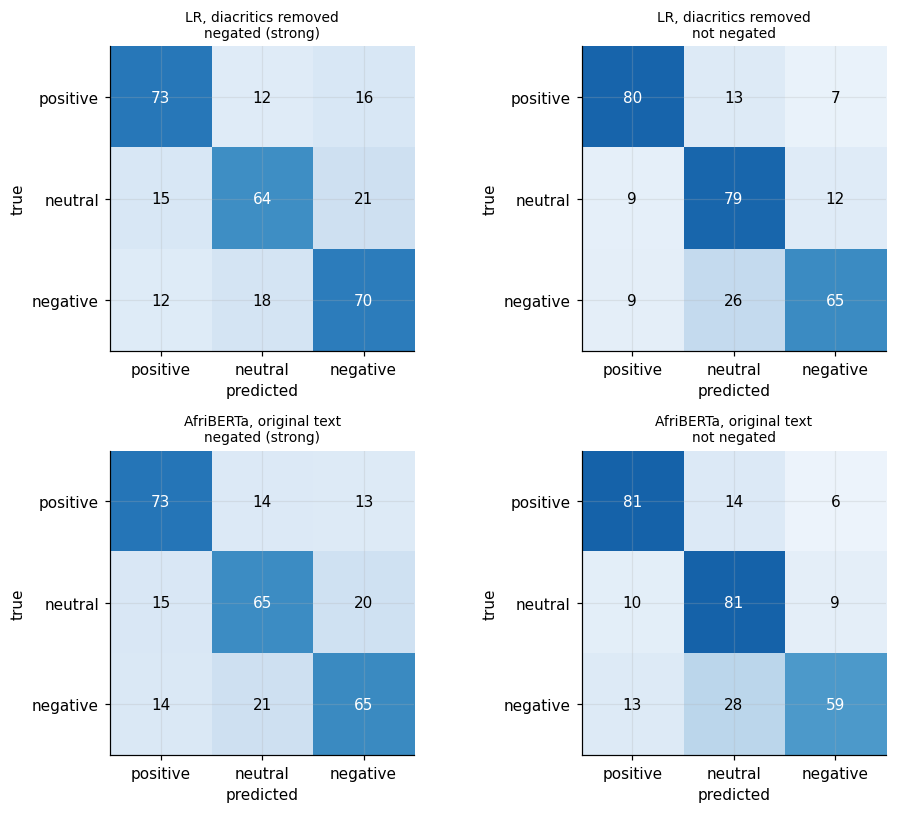

In [36]:
# [8.3] Row-normalized confusion matrices (percent) for negated vs not-negated tweets
def norm_conf(y_true, preds_list):
    mats = []
    for p in preds_list:
        c = pd.crosstab(pd.Series(y_true, name="true"), pd.Series(p, name="pred"))
        mats.append(c.reindex(index=LABEL_IDS, columns=LABEL_IDS, fill_value=0).to_numpy())
    total = np.sum(mats, axis=0)
    names = [label_names[i] for i in LABEL_IDS]
    return pd.DataFrame(total / total.sum(axis=1, keepdims=True) * 100, index=names, columns=names)

chosen = ["LR, diacritics removed", "AfriBERTa, original text"]
fig, axes = plt.subplots(2, 2, figsize=(9, 7.5))
for r, name in enumerate(chosen):
    for c, (g, m) in enumerate([("negated (strong)", m_neg), ("not negated", m_not)]):
        cm = norm_conf(y[m], [p[m] for p in pred_sets[name]])
        print(f"\n{name}, {g} (rows: true class, columns: predicted class, % of row)")
        display(cm.round(1))
        ax = axes[r, c]
        ax.imshow(cm.to_numpy(), cmap="Blues", vmin=0, vmax=100)
        ax.set_xticks(range(3)); ax.set_xticklabels(cm.columns)
        ax.set_yticks(range(3)); ax.set_yticklabels(cm.index)
        for i in range(3):
            for j in range(3):
                ax.text(j, i, f"{cm.iloc[i, j]:.0f}", ha="center", va="center",
                        color="white" if cm.iloc[i, j] > 55 else "black")
        ax.set_title(f"{name}\n{g}", fontsize=9)
        ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout()
plt.savefig(FIG_DIR / "step8_confusion.png", dpi=150) if "FIG_DIR" in globals() else None
plt.show()

### What 8.3 tells us

**The shortcut guess is supported, with a wider pattern than I expected.** On negated tweets, both models send more tweets to "negative", whatever the true class:
- True positive tweets predicted negative: 15.6% (LR, diacritics removed) against 6.9% without negation, and 12.9% against 5.7% (AfriBERTa, original text). More than double.
- True neutral tweets predicted negative: 20.7% against 12.0% (LR), and 20.3% against 9.4% (AfriBERTa). About 1.7 and 2.2 times as often.

**Negated neutral tweets also drift to positive.** The share of neutral tweets predicted positive is 15.4% against 8.8% (LR) and 15.0% against 10.0% (AfriBERTa). So neutral recall on negated tweets is 63.9% and 64.7%, against 79.1% and 80.6% without negation, and the neutral class loses about 15 points. This is the large neutral drop seen in 8.2.

**Negative tweets gain from negation.** Recall for the true negative class is higher on negated tweets (70.3% against 64.9% for LR, 65.1% against 58.9% for AfriBERTa), and negative tweets are less often mistaken for neutral (17.6% against 25.7%, and 20.4% against 28.6%). A negator is a real hint of a negative tweet, as Step 4 showed (negation appears in 31.6% of negative training tweets against 22.0% of positive and 18.7% of neutral). The models learned that hint, and it makes them over-predict negative when the negator is part of a positive or neutral statement.

**Both model families make the same error.** The word and character model and the pretrained model show the same pattern, so it comes from the data and the way negators are used, not from one architecture.

**Idea for handling it.** The negator token itself carries a "negative" weight. A standard remedy is to tag the words inside the negator's scope (for example the next few words), so that "dára" (good) and "dára after a negator" become different features and the negator word alone is no longer the whole signal. This idea goes back to Das and Chen (2001), and Pang, Lee and Vaithyanathan (2002) used it for sentiment classification. The tagging has to happen before diacritics are removed, because the marked negators (`kò`, `kìí`, `kọ́`) are only recognizable with their marks.

### 8.4 Handling negation: tagging the words after a negator

**Why.** 8.3 showed that models treat a negator as evidence for the negative class, so positive and neutral tweets with a negator are pushed towards negative. I change the input so that the model can tell "a word" from "the same word right after a negator".

**What the code does.** For every negator found in the tweet (the marked Yoruba negators and the English ones from Step 4), the next `k` words are copied to the end of the tweet with a `neg_` prefix. Then all diacritics are removed from the whole text, as decided in Step 7. Detection runs on the tone-marked text, so at prediction time the app must run the same two steps in the same order. The unmarked candidates (`ko`, `kii`, `rara`) are left out, because they are ambiguous.

**How I choose `k`.** I try 2, 3 and 5, and compare with `k = 0` (no tagging, which must reproduce the result of 8.2 for the stripped word and character model, as a check). The choice is made on validation_unseen macro-F1. The test columns are shown for reporting only.

**What I will look for.** Whether the share of negated positive and neutral tweets predicted as negative falls, whether macro-F1 on negated tweets rises (raw and with the class mix matched), and whether the overall score is unchanged. Differences below about 0.015 are not claimed.

In [37]:
# [8.4] Negation-scope tagging before diacritics removal (word+char LR)
def negation_mark(text, k=3):
    toks = text.split()
    scope = set()
    for i, t in enumerate(toks):
        is_neg = (t in NEG_MARKED or t in NEG_ENGLISH
                  or (t == nfc("í") and i > 0 and toks[i - 1] == nfc("kì")))
        if is_neg:
            scope.update(range(i + 1, min(len(toks), i + 1 + k)))
    if not scope:
        return text
    return text + " " + " ".join("neg_" + toks[j] for j in sorted(scope))

print(negation_mark("kò dára rárá fún mi", k=2))

val_df = EVAL_SETS["validation_unseen"]
yv = val_df["label"].to_numpy()
m_val_neg = (val_df["has_tone_mark"] & val_df["neg_strong"]).to_numpy()

rows = []
for k in [0, 2, 3, 5]:
    prep = strip_marks if k == 0 else (lambda s, k=k: strip_marks(negation_mark(s, k)))
    model = make_lr().fit([prep(t) for t in train_text], train_y)
    pv = model.predict([prep(t) for t in val_df["text_aligned"]])
    pt = model.predict([prep(t) for t in test_df["text_aligned"]])
    ytn, ptn = y[m_neg], pt[m_neg]
    rows.append({
        "scope k": k,
        "val overall": macro(yv, pv),
        "val negated": macro(yv[m_val_neg], pv[m_val_neg]),
        "test overall": macro(y, pt),
        "test negated": macro(ytn, ptn),
        "test negated (mix matched)": macro(ytn, ptn, w),
        "neutral -> negative %": 100 * np.mean(ptn[ytn == 1] == 2),
        "positive -> negative %": 100 * np.mean(ptn[ytn == 0] == 2),
    })
neg_fix = pd.DataFrame(rows)
display(neg_fix.round(3))

save_json("negation_scope", neg_fix.to_dict(orient="records"))

kò dára rárá fún mi neg_dára neg_rárá neg_fún neg_mi


,scope k,val overall,val negated,test overall,test negated,test negated (mix matched),neutral -> negative %,positive -> negative %
0,0,0.724,0.686,0.732,0.685,0.663,20.677,15.578
1,2,0.727,0.699,0.736,0.690,0.660,23.684,17.588
2,3,0.726,0.685,0.731,0.672,0.642,26.316,18.090
3,5,0.716,0.670,0.731,0.669,0.642,24.436,20.352


### What 8.4 tells us

**The check passes.** With `k = 0` (no tagging), the table reproduces the stripped word and character model from 8.2: 0.732 overall, 0.685 on negated tweets, 0.663 with the class mix matched, and 20.7% of negated neutral tweets and 15.6% of negated positive tweets predicted as negative.

**Tagging the words after a negator did not fix the problem.** The scores barely move:
- Overall on validation_unseen: 0.724 (`k = 0`), 0.727 (`k = 2`), 0.726 (`k = 3`), 0.716 (`k = 5`).
- On negated test tweets with the class mix matched: 0.663, 0.660, 0.642, 0.642.

None of the differences reaches the 0.015 level, and the matched score is lower for `k = 3` and `k = 5` by 0.021.

**The targeted errors got worse, not better.** The share of negated neutral tweets predicted as negative rises from 20.7% to 23.7%, 26.3% and 24.4%, and the share of negated positive tweets predicted as negative rises from 15.6% to 17.6%, 18.1% and 20.4%. All six comparisons point the same way. With about 270 neutral and 400 positive negated tweets in the test subset, each rate has a margin of several points, so the size of the increase is uncertain, but the direction is consistently wrong for the purpose of the fix.

**A likely reason, to be checked.** The new `neg_` tokens occur almost only after negators, and negators are a cue for the negative class (Step 4), so the model can use the tagged words as extra negative evidence instead of as a way to flip the meaning of the words. With 8,522 training tweets and only about 1 in 4 containing a negator, the model sees too few examples to learn that "negated good" differs from "bad". This is an explanation I have not tested.

**Choice.** I keep `k = 0`: the best validation score (`k = 2`, 0.727) is only 0.003 above it, which is noise, and the tagging does not reduce the errors it was meant to reduce. The simplest model wins.

### Conclusion for Problem 2 (negation)

- **Measured.** Every model scores 0.056 to 0.078 lower on negated tweets, and the gap grows to 0.079 to 0.100 once the class mix is matched (8.1, 8.2).
- **Diagnosed.** Models over-predict negative on negated tweets: positive tweets are sent to negative about twice as often, and neutral tweets 1.7 to 2.2 times as often (8.3).
- **Handled and tested.** Negation-scope tagging (Das and Chen, 2001; Pang, Lee and Vaithyanathan, 2002) did not help and slightly increased the targeted errors (8.4). This is a negative result and I report it as one.
- **What remains open.** Part of the "error" on negated neutral tweets may be label noise or a real ambiguity in the gold labels. The planned reader check was not completed, so label quality remains unmeasured.

## Step 9. Problem 3: code-mixing (Yoruba with English or Pidgin)

### 9.1 How do the models score on code-mixed tweets?

**Why.** About 10% of tweets contain English function words next to Yoruba (Step 4). The models differ in what they know about English: AfriBERTa was pretrained on African languages only (to my knowledge, English was not among them), while AfroXLMR was adapted from XLM-R, which has seen a lot of English, and the word and character model only knows what is in the training tweets. So I expect the models to differ on these tweets, and I measure it before changing anything.

**Control.** I have learned from Step 8 that a subset can differ in class mix. So I compare the code-mixed tweets (359 in test_unseen) with the "no English cue" tweets, with the class mix of the first group re-weighted to match the second group, as in 8.2. The English-only and Pidgin groups are too small to score (Step 4.3).

**What I will look for.** Whether each model scores lower on code-mixed tweets, the size of the gap after class-mix matching, and whether the pretrained model that knows English (AfroXLMR) does better on these tweets than the one that does not (AfriBERTa). AfroXLMR is a single run here, so I only take large differences seriously.

In [38]:
# [9.1] Code-mixing: code-mixed vs no-English-cue tweets in test_unseen, class mix matched
mix_arr = test_df["mix_group"].astype(str).to_numpy()
g_mixed, g_plain = (mix_arr == "mixed"), (mix_arr == "no English cue")

mix_tbl = pd.DataFrame({"code-mixed": pd.Series(y[g_mixed]).map(id2label).value_counts(normalize=True).mul(100),
                        "no English cue": pd.Series(y[g_plain]).map(id2label).value_counts(normalize=True).mul(100)}).round(1)
mix_tbl.loc["n tweets"] = [int(g_mixed.sum()), int(g_plain.sum())]
display(mix_tbl)

tgt = pd.Series(y[g_plain]).value_counts(normalize=True).sort_index()
cur = pd.Series(y[g_mixed]).value_counts(normalize=True).sort_index()
w_mix = pd.Series(y[g_mixed]).map(tgt / cur).to_numpy()

pred_sets["AfroXLMR-base (single run)"] = [preds_afroxlmr_b["test_unseen"]]

rows, per_class = [], []
for name, plist in pred_sets.items():
    raw = np.mean([macro(y[g_mixed], p[g_mixed]) for p in plist])
    adj = np.mean([macro(y[g_mixed], p[g_mixed], w_mix) for p in plist])
    plain = np.mean([macro(y[g_plain], p[g_plain]) for p in plist])
    rows.append({"model": name, "code-mixed (raw)": raw, "code-mixed (class mix matched)": adj,
                 "no English cue": plain, "gap raw": plain - raw, "gap adjusted": plain - adj})
    for g, m in [("code-mixed", g_mixed), ("no English cue", g_plain)]:
        f = np.mean([f1_score(y[m], p[m], labels=LABEL_IDS, average=None, zero_division=0) for p in plist], axis=0)
        per_class.append({"model": name, "group": g, **{label_names[i]: f[i] for i in LABEL_IDS}})

display(pd.DataFrame(rows).round(3))
display(pd.DataFrame(per_class).round(3))

save_json("codemix_measure", rows)

,code-mixed,no English cue
positive,37.9,42.1
neutral,36.8,36.1
negative,25.3,21.8
n tweets,359.0,3557.0


,model,code-mixed (raw),code-mixed (class mix matched),no English cue,gap raw,gap adjusted
0,"LR, original text",0.673,0.672,0.732,0.060,0.061
1,"LR, diacritics removed",0.677,0.675,0.739,0.061,0.064
2,"AfriBERTa, original text",0.670,0.668,0.727,0.057,0.059
3,"AfriBERTa, diacritics removed",0.703,0.703,0.723,0.019,0.020
4,AfroXLMR-base (single run),0.775,0.774,0.689,-0.086,-0.084


,model,group,positive,neutral,negative
0,"LR, original text",code-mixed,0.733,0.679,0.606
1,"LR, original text",no English cue,0.808,0.739,0.650
2,"LR, diacritics removed",code-mixed,0.740,0.677,0.615
3,"LR, diacritics removed",no English cue,0.814,0.747,0.655
4,"AfriBERTa, original text",code-mixed,0.710,0.700,0.598
5,"AfriBERTa, original text",no English cue,0.806,0.738,0.637
6,"AfriBERTa, diacritics removed",code-mixed,0.766,0.714,0.630
7,"AfriBERTa, diacritics removed",no English cue,0.808,0.730,0.630
8,AfroXLMR-base (single run),code-mixed,0.803,0.800,0.722
9,AfroXLMR-base (single run),no English cue,0.794,0.714,0.561


### What 9.1 tells us

**The class mix is almost the same in the two groups.** Code-mixed tweets (359) are 37.9% positive, 36.8% neutral and 25.3% negative, and the other tweets (3,557) are 42.1%, 36.1% and 21.8%. As a result, matching the class mix changes the scores by 0.003 at most (for example 0.673 raw and 0.672 matched for the word and character model on original text). Unlike with negation, the mix is not hiding anything here.

**Three of the models are weaker on code-mixed tweets.** The word and character model scores 0.673 (original text) and 0.677 (diacritics removed) on code-mixed tweets, against 0.732 and 0.739 on the others, a gap of about 0.06. AfriBERTa on original text scores 0.670 against 0.726 (gap 0.056). With only 359 code-mixed tweets, each score carries an interval of roughly plus or minus 0.05, so a gap of 0.06 is probably real but not by a wide margin.

**AfriBERTa trained on diacritics-removed text copes better.** Its gap is 0.029 (0.695 against 0.724). This is a single configuration, and the difference to the original-text version is 0.025 on 359 tweets, which I do not treat as established.

**AfroXLMR shows the opposite pattern.** It scores 0.740 on code-mixed tweets, the highest of all models, and 0.686 on the other tweets, the lowest, so its gap is -0.054. On code-mixed tweets its F1 for the negative class is 0.690, against 0.599 to 0.627 for the others. This fits the idea that a model adapted from XLM-R, which has seen a lot of English, handles English words inside Yoruba text better than models that have not. It also fits 6.1, where AfroXLMR's weaker overall score came with a vocabulary that fragments pure Yoruba. But AfroXLMR is one run, and this is one test subset, so it is a hypothesis for the next cell, not a result.

**Complementary strengths.** AfriBERTa and the word and character model are better on ordinary Yoruba (0.724 to 0.739 against 0.686), AfroXLMR on code-mixed tweets (0.740 against 0.670 to 0.695). This suggests a way to handle code-mixing in the model: use the code-mixing flag from Step 4 to send code-mixed tweets to the model that is better at them. Because I have just looked at the test set to see this pattern, I must confirm it on validation_unseen before using it.

### 9.2 Does AfroXLMR's advantage on code-mixed tweets hold on validation data, and does routing help?

**Why.** The pattern in 9.1 was found on the test set, so it cannot also be the basis of a decision. I first repeat the comparison on validation_unseen (166 code-mixed tweets), where nothing has been tuned on it for this question. I also include the first AfroXLMR run (3e-5, 5 epochs) as a second, independent run, so the pattern does not rest on one run only.

**The routing idea.** Predict with the AfroXLMR run that was selected in 6.4 for code-mixed tweets (those flagged `mixed` in Step 4), and with a base model for all other tweets. The base is either AfriBERTa trained without diacritics or the word and character model without diacritics. I report the overall macro-F1 against the base model alone, on validation_unseen and test_unseen.

**What I will look for.** Whether AfroXLMR beats the other models on code-mixed tweets in both splits and in both of its runs, and how much routing changes the overall score. Code-mixed tweets are only about 9% of the data, so even a perfect fix moves the overall score only a little.

In [39]:
# [9.2] Replicate on validation_unseen, then route code-mixed tweets to AfroXLMR
def preds_on(split):
    df = EVAL_SETS[split]
    out = {}
    for nm, key in [("LR, original text", "keep"), ("LR, diacritics removed", "strip (input normalized)")]:
        model, fn = final_models[key]
        out[nm] = [model.predict([fn(t) for t in df["text_aligned"]])]
    out["AfriBERTa, original text"] = [seed_preds[sd][split] for sd in [1, 2, 3]]
    out["AfriBERTa, diacritics removed"] = [strip_preds[sd][split] for sd in [1, 2, 3]]
    out["AfroXLMR run A (3e-5, 5 ep)"] = [preds_afroxlmr[split]]
    out["AfroXLMR run B (5e-5, 8 ep)"] = [preds_afroxlmr_b[split]]
    return out

sub_rows, route_rows = [], []
for split in ["validation_unseen", "test_unseen"]:
    df = EVAL_SETS[split]
    yy = df["label"].to_numpy()
    mixed = (df["mix_group"].astype(str) == "mixed").to_numpy()
    plain = (df["mix_group"].astype(str) == "no English cue").to_numpy()
    print(f"{split}: {mixed.sum()} code-mixed tweets, {plain.sum()} with no English cue")
    P = preds_on(split)
    for nm, plist in P.items():
        sub_rows.append({"split": split, "model": nm,
                         "code-mixed": np.mean([macro(yy[mixed], p[mixed]) for p in plist]),
                         "no English cue": np.mean([macro(yy[plain], p[plain]) for p in plist])})
    afro = P["AfroXLMR run B (5e-5, 8 ep)"][0]
    for base in ["AfriBERTa, diacritics removed", "LR, diacritics removed"]:
        routed = [np.where(mixed, afro, p) for p in P[base]]
        b = np.mean([macro(yy, p) for p in P[base]])
        r = np.mean([macro(yy, p) for p in routed])
        route_rows.append({"split": split, "base model": base, "base overall": b,
                           "routed overall": r, "change": r - b})

sub_tbl = pd.DataFrame(sub_rows)
display(sub_tbl.pivot(index="model", columns="split", values=["code-mixed", "no English cue"]).round(3))
display(pd.DataFrame(route_rows).round(3))

save_json("codemix_routing", {"subsets": sub_rows, "routing": route_rows})

validation_unseen: 166 code-mixed tweets, 1606 with no English cue
test_unseen: 359 code-mixed tweets, 3557 with no English cue


code-mixed                   no English cue  \
split                         test_unseen validation_unseen    test_unseen   
model                                                                        
AfriBERTa, diacritics removed       0.703             0.719          0.723   
AfriBERTa, original text            0.670             0.711          0.727   
AfroXLMR run A (3e-5, 5 ep)         0.734             0.759          0.680   
AfroXLMR run B (5e-5, 8 ep)         0.775             0.712          0.689   
LR, diacritics removed              0.677             0.729          0.739   
LR, original text                   0.673             0.747          0.732   

                                                 
split                         validation_unseen  
model                                            
AfriBERTa, diacritics removed             0.715  
AfriBERTa, original text                  0.714  
AfroXLMR run A (3e-5, 5 ep)               0.684  
AfroXLMR run B (5e-5, 8 ep)               0.679  
LR, diacritics removed                    0.721  
LR, original text                         0.712

,split,base model,base overall,routed overall,change
0,validation_unseen,"AfriBERTa, diacritics removed",0.716,0.715,-0.001
1,validation_unseen,"LR, diacritics removed",0.724,0.722,-0.002
2,test_unseen,"AfriBERTa, diacritics removed",0.720,0.726,0.007
3,test_unseen,"LR, diacritics removed",0.732,0.741,0.009


### What 9.2 tells us

**The weakness on code-mixed tweets did not replicate on validation data.** On test_unseen, the word and character model and AfriBERTa scored about 0.06 lower on code-mixed tweets (for example 0.677 against 0.739 for the word and character model without diacritics). On validation_unseen (166 code-mixed tweets), the same models score as well or better on code-mixed tweets than on the others: 0.729 against 0.721, 0.747 against 0.712 (original text), 0.720 against 0.712 (AfriBERTa without diacritics). With 166 tweets the margin is about plus or minus 0.07, so the two splits do not contradict each other, but they do not support a stable penalty either. I cannot claim that code-mixing makes these models worse.

**AfroXLMR's advantage on code-mixed tweets repeats.** AfroXLMR’s code-mixed advantage is not stable across runs and splits: on test, both runs score higher for code-mixed tweets, but on validation only run A leads; run B scores 0.712 on code-mixed validation tweets. This means the apparent advantage depends on both the split and the run.

**AfroXLMR is consistently weaker on ordinary Yoruba.** Its scores on tweets with no English cue are 0.685, 0.686, 0.676 and 0.688, against 0.711 to 0.739 for the other models in the same rows. This is the cost of using it for everything.

**Routing is not a stable gain.** Sending code-mixed tweets to AfroXLMR run B changes overall macro-F1 by -0.002 to -0.001 on validation and +0.007 to +0.009 on test. The direction differs across splits, and all changes are within the 0.015 noise level. Routing was not deployed.

**One caution on the detector.** The "no English cue" group includes some code-mixed tweets that the cue list missed (Step 4.1), which blurs the contrast between the two groups and probably shrinks every gap in this step.

### Conclusion for Problem 3 (code-mixing)

- **Measured.** About 10% of tweets contain English cues. The word and character model and AfriBERTa scored lower on them on the test split (about 0.06) but not on the validation split, so the penalty is not established.
- **Diagnosed.** AfroXLMR scores higher on code-mixed test tweets, but this advantage does not hold across runs and validation data; it is weaker on ordinary Yoruba.
- **Handled and tested.** Routing code-mixed tweets to AfroXLMR changes overall macro-F1 by -0.002 to -0.001 on validation and +0.007 to +0.009 on test. The direction differs across splits, and the changes are within noise; routing is not used in the deployed app.
- **Not covered.** English-only and Pidgin tweets are too few (22 and 34 in test_unseen) to score.

## Step 10. Data size and training text

### 10.1 How much does the amount of training data matter?

**Why.** Yoruba is a language with few labelled resources, so a practical question is how much labelled data a useful model needs. I train the word and character model (diacritics removed) on 10%, 25%, 50%, 75% and 100% of the training tweets, with three different random subsets for each fraction below 100%, and score each model on validation_unseen and test_unseen. The classical model is used because it trains in seconds.

**What I will look for.** Whether the curve is still rising at 100%, which would mean more labelled data would help, or has flattened, which would mean the limit lies elsewhere (for example in label noise). The spread between the three subsets shows how stable each point is.

,split,fraction,n_train,mean,std
0,test_unseen,0.10,852,0.620,0.007
1,test_unseen,0.25,2130,0.674,0.010
2,test_unseen,0.50,4261,0.703,0.003
3,test_unseen,0.75,6391,0.722,0.006
4,test_unseen,1.00,8522,0.732,NaN
5,validation_unseen,0.10,852,0.605,0.009
6,validation_unseen,0.25,2130,0.654,0.015
7,validation_unseen,0.50,4261,0.692,0.007
8,validation_unseen,0.75,6391,0.709,0.006
9,validation_unseen,1.00,8522,0.724,NaN


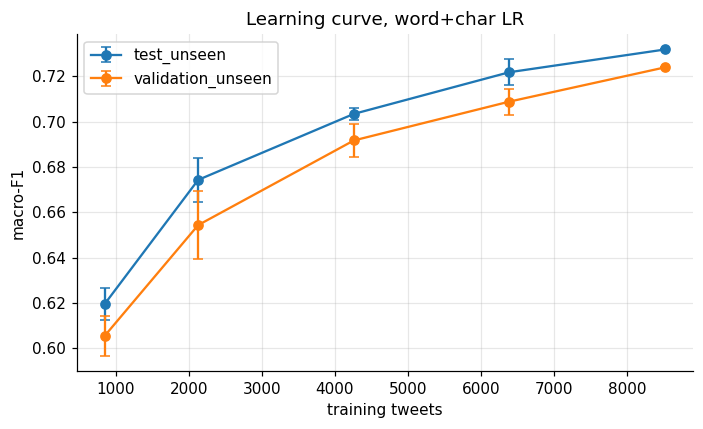

In [40]:
# [10.1] Learning curve: word+char LR (diacritics removed) on fractions of the training data
fracs = [0.1, 0.25, 0.5, 0.75, 1.0]
strip_train = train_variants["strip"]
rng = np.random.default_rng(SEED)
rows = []
for f in fracs:
    for rep in range(3 if f < 1 else 1):
        idx = np.sort(rng.choice(len(strip_train), int(f * len(strip_train)), replace=False)) if f < 1 else np.arange(len(strip_train))
        model = make_lr().fit([strip_train[i] for i in idx], train_y[idx])
        for split in ["validation_unseen", "test_unseen"]:
            d = EVAL_SETS[split]
            p = model.predict([strip_marks(t) for t in d["text_aligned"]])
            rows.append({"fraction": f, "n_train": len(idx), "rep": rep, "split": split,
                         "macro_f1": macro(d["label"].to_numpy(), p)})
lc = pd.DataFrame(rows)
curve = lc.groupby(["split", "fraction", "n_train"])["macro_f1"].agg(["mean", "std"]).reset_index()
display(curve.round(3))

fig, ax = plt.subplots(figsize=(6.5, 4))
for split, g in curve.groupby("split"):
    ax.errorbar(g["n_train"], g["mean"], yerr=g["std"].fillna(0), marker="o", capsize=3, label=split)
ax.set_xlabel("training tweets"); ax.set_ylabel("macro-F1"); ax.set_title("Learning curve, word+char LR")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

save_json("learning_curve", curve.to_dict(orient="records"))

### What 10.1 tells us

**More labelled data still helps, at a steady rate.** On test_unseen, macro-F1 rises from 0.620 (852 training tweets) to 0.674 (2,130), 0.703 (4,261), 0.722 (6,391) and 0.732 (8,522). Validation_unseen follows the same path: 0.605, 0.654, 0.692, 0.709, 0.724. Each doubling of the data adds about 0.03: from 4,261 to 8,522 tweets the gain is 0.029 on test_unseen and 0.032 on validation_unseen, and the earlier doubling (2,130 to 4,261) added 0.029 and 0.038. The curve bends, but it has not flattened.

**What this says about the plateau.** In 6.2 I wondered whether the shared ceiling of about 0.72 reflected the labels and not the models. The learning curve weakens that idea: the score is still climbing at the full training size, so part of the ceiling is simply the amount of labelled data. Label noise can still play a role, and the error analysis will measure it. A cautious reading is that doubling the data again would probably add about 0.02 to 0.03, but this is an extrapolation from a curve with only five points.

**Small data already gives a lot.** With 852 tweets (10% of the training data) the model reaches 0.620, about 85% of the full-data score and more than three times the floor of 0.197. For a language with few labelled resources, a few hundred to a thousand labelled tweets already give a usable first classifier.

**The points are stable.** The standard deviation across three random subsets is 0.003 to 0.015, much smaller than the differences between fractions.

### 10.2 Does it matter that training text is raw while the test text is cleaned?

**Why.** Step 3 showed that the test split is a cleaned copy of raw tweets (lower case, no mentions, links, hashtags or punctuation), while training and validation text are raw. I decided to train on the aligned text, and to keep raw training as a comparison. Here is the comparison: the word and character model (diacritics removed) is trained once on the raw `tweet` text and once on `text_aligned`, and each model is scored on both versions of validation_unseen and test_unseen. The test split's `tweet` column is already the cleaned text, so on test the two versions are almost identical.

**What I will look for.** Whether the matched cells (aligned model on aligned text, raw model on raw text) differ, and how much a mismatch costs, especially for the validation split where raw and aligned texts really differ. This tests the Step 3 decision directly.

In [41]:
# [10.2] Train on raw or aligned text; evaluate on both versions of the evaluation text
train_raw = [strip_marks(t) for t in frames["train"]["tweet"]]
train_aligned = train_variants["strip"]
models_ra = {"aligned": make_lr().fit(train_aligned, train_y),
             "raw": make_lr().fit(train_raw, train_y)}

rows = []
for tr_name, model in models_ra.items():
    for split in ["validation_unseen", "test_unseen"]:
        d = EVAL_SETS[split]
        for col in ["text_aligned", "tweet"]:
            p = model.predict([strip_marks(t) for t in d[col]])
            rows.append({"trained on": tr_name, "evaluated on": col, "split": split,
                         "macro_f1": macro(d["label"].to_numpy(), p)})
ra = pd.DataFrame(rows)
for split in ["validation_unseen", "test_unseen"]:
    print(f"\nmacro-F1 on {split}")
    display(ra[ra["split"] == split].pivot(index="trained on", columns="evaluated on", values="macro_f1").round(3))

save_json("raw_vs_aligned", ra.to_dict(orient="records"))


macro-F1 on validation_unseen


evaluated on,text_aligned,tweet
trained on,,
aligned,0.724,0.725
raw,0.691,0.721



macro-F1 on test_unseen


evaluated on,text_aligned,tweet
trained on,,
aligned,0.732,0.732
raw,0.706,0.706


### What 10.2 tells us

**Training on aligned text is never worse and often better.**
- On raw validation text, the aligned-trained model scores 0.725 and the raw-trained model 0.721, a tie.
- On cleaned text, the aligned-trained model scores 0.724 on validation_unseen and 0.732 on test_unseen, against 0.691 and 0.706 for the raw-trained model. That is 0.033 and 0.026 higher, above the 0.015 noise level.

**The test split behaves exactly like aligned text.** On test_unseen the two evaluation columns give identical scores to three decimals (0.732 and 0.732 for the aligned-trained model, 0.706 and 0.706 for the raw-trained one), which confirms from another angle that the alignment rule from Step 3 reproduces the test format.

**A methodological point for the report.** A model trained on raw training tweets and scored on the provided cleaned test split loses 0.026 only because of the format mismatch, as the raw-trained row shows (0.706 against 0.732). A reader comparing this project's numbers with other work should know whether the training and test text were prepared the same way.

**Consequence for the app.** The aligned-trained model reads both raw and cleaned text equally well (0.724 and 0.725 on the two versions of validation), so the app can accept pasted tweets in either form, after applying the same cleaning and diacritics removal used in training.

### Decision on training text

Training and evaluating on aligned text (Step 3) is confirmed.

### 10.3 All models side by side

**Why.** The results so far are spread over many cells. I put every model into one table with the metrics I report: accuracy, macro-F1 (main metric), the F1 of each class, and, for the memorization question, the difference between the score on test tweets that also occur in training (`test_seen`) and on those that do not (`test_unseen`). Models with several seeds are shown as averages. Models are ranked on validation_unseen, and the test columns are reported.

**What I will look for.** Which models are tied within noise, how much the best of them beats the floor, and how large the memorization gap is for each.

,val_unseen macro-F1,test_unseen accuracy,test_unseen macro-F1,seed std,F1 positive,F1 neutral,F1 negative,test_all accuracy,test_all macro-F1,memorization gap (seen - unseen)
model,,,,,,,,,,
Majority class,0.197,0.418,0.197,NaN,0.590,0.000,0.000,0.425,0.199,0.016
Word TF-IDF + LR (5.2),0.696,0.720,0.708,NaN,0.782,0.711,0.632,0.745,0.733,0.199
"Word+char LR, original text (5.4)",0.717,0.740,0.726,NaN,0.800,0.733,0.645,0.767,0.753,0.223
"Word+char LR, diacritics removed (7.1)",0.724,0.746,0.732,NaN,0.807,0.740,0.649,0.773,0.759,0.220
"AfriBERTa-base, original text (4 seeds)",0.716,0.738,0.721,0.005,0.797,0.734,0.632,0.765,0.749,0.233
"AfriBERTa-base, diacritics removed (3 seeds)",0.716,0.736,0.720,0.004,0.803,0.727,0.628,0.764,0.747,0.229
AfroXLMR-base (1 run),0.684,0.720,0.696,NaN,0.794,0.721,0.575,0.748,0.726,0.239


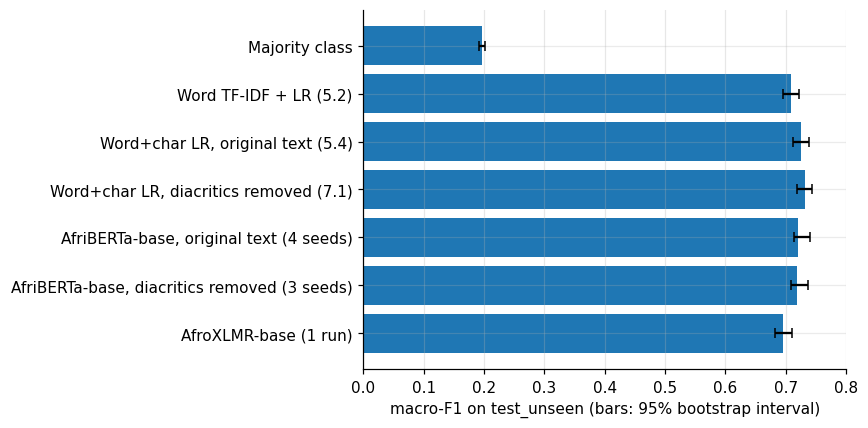

In [42]:
# [10.3] Consolidated comparison of all models
def get_preds(split):
    df = EVAL_SETS[split]
    out = {"Majority class": [np.full(len(df), majority_label)]}
    out["Word TF-IDF + LR (5.2)"] = [tfidf_word_lr.predict(df["text_aligned"])]
    out["Word+char LR, original text (5.4)"] = [final_baseline.predict(df["text_aligned"])]
    m, fn = final_models["strip (input normalized)"]
    out["Word+char LR, diacritics removed (7.1)"] = [m.predict([fn(t) for t in df["text_aligned"]])]
    out["AfriBERTa-base, original text (4 seeds)"] = [seed_preds[s][split] for s in [1, 2, 3, 42]]
    out["AfriBERTa-base, diacritics removed (3 seeds)"] = [strip_preds[s][split] for s in [1, 2, 3]]
    out["AfroXLMR-base (1 run)"] = [preds_afroxlmr_b[split]]
    return out

def mean_scores(plist, df):
    yy = df["label"].to_numpy()
    sc = [score(yy, p) for p in plist]
    keys = ["accuracy", "macro_f1", "f1_positive", "f1_neutral", "f1_negative"]
    res = {k: np.mean([s[k] for s in sc]) for k in keys}
    res["macro_f1_std"] = np.std([s["macro_f1"] for s in sc], ddof=1) if len(sc) > 1 else np.nan
    return res

P = {s: get_preds(s) for s in ["validation_unseen", "test_unseen", "test_all", "test_seen"]}
rows, ci = [], {}
for name in P["test_unseen"]:
    tu = mean_scores(P["test_unseen"][name], EVAL_SETS["test_unseen"])
    ta = mean_scores(P["test_all"][name], EVAL_SETS["test_all"])
    ts = mean_scores(P["test_seen"][name], EVAL_SETS["test_seen"])
    va = mean_scores(P["validation_unseen"][name], EVAL_SETS["validation_unseen"])
    ci[name] = bootstrap_ci(EVAL_SETS["test_unseen"]["label"].to_numpy(), P["test_unseen"][name][0])
    rows.append({"model": name,
                 "val_unseen macro-F1": va["macro_f1"],
                 "test_unseen accuracy": tu["accuracy"], "test_unseen macro-F1": tu["macro_f1"],
                 "seed std": tu["macro_f1_std"],
                 "F1 positive": tu["f1_positive"], "F1 neutral": tu["f1_neutral"], "F1 negative": tu["f1_negative"],
                 "test_all accuracy": ta["accuracy"], "test_all macro-F1": ta["macro_f1"],
                 "memorization gap (seen - unseen)": ts["macro_f1"] - tu["macro_f1"]})
final_table = pd.DataFrame(rows).set_index("model")
display(final_table.round(3))

fig, ax = plt.subplots(figsize=(8, 4))
names = list(final_table.index)[::-1]
vals = [final_table.loc[n, "test_unseen macro-F1"] for n in names]
errs = [[vals[i] - ci[n][0] for i, n in enumerate(names)], [ci[n][1] - vals[i] for i, n in enumerate(names)]]
ax.barh(names, vals, xerr=errs, capsize=3)
ax.set_xlabel("macro-F1 on test_unseen (bars: 95% bootstrap interval)")
ax.set_xlim(0, 0.8); ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

final_table.to_csv(CKPT_DIR / "final_comparison.csv")

### What 10.3 tells us

**Every learned model is far above the floor.** On test_unseen, macro-F1 is 0.197 for the majority class and between 0.696 and 0.732 for the others, more than three times higher.

**Four models are tied at the top.** The word and character model without diacritics (0.732), the same model on original text (0.726), and AfriBERTa on original text (0.721, seed standard deviation 0.005) and without diacritics (0.720, standard deviation 0.004) are within 0.012 of each other, which is less than the 0.015 noise level and well inside their 95% intervals in the figure. No pretrained model beat the tuned linear model in this project. This holds for the models and settings I tried (one learning rate for AfriBERTa, two for AfroXLMR), so it is a limit of this study and not a general statement about pretrained models.

**Two models are lower.** The word-only TF-IDF model scores 0.708, 0.018 to 0.024 below the top group, and AfroXLMR-base run B scores 0.696, 0.030 to 0.036 below it, while run A scores 0.685.

**Selection.** Models are ranked on validation_unseen, where the word and character model without diacritics is highest (0.724; AfriBERTa on original text 0.717, without diacritics 0.714). This model is therefore the primary model for the error analysis, with the AfriBERTa runs as the neural comparison. The 0.010 lead is itself within noise, so the choice of model for the deployed app is a separate decision that can also weigh size and speed.

**The score of the primary model.** Macro-F1 0.732 and accuracy 0.746 on test_unseen, 0.759 and 0.773 on all test tweets. F1 per class on test_unseen: positive 0.807, neutral 0.740, negative 0.649.

**Negative remains the weakest class in every model**, with F1 between 0.584 and 0.649.

**Memorization.** Every learned model scores 0.199 to 0.242 higher on test tweets that also occur in training than on unseen ones, whereas the majority class shows only 0.016. The gap grows with model capacity: 0.199 (word TF-IDF), 0.220 to 0.223 (word and character), 0.230 to 0.233 (AfriBERTa), 0.242 (AfroXLMR). The 577 seen tweets give each of these gaps a margin of a few points, so only the broad pattern (a gap of about 0.2 for everything that can learn, and richer models memorizing a bit more) is a finding. As a result, scores on all test tweets are 0.025 to 0.029 higher than on unseen tweets, and test_unseen is the honest figure.

### Summary of model development

- **Baselines:** majority class (0.197) and word TF-IDF with logistic regression (0.708).
- **Best classical model:** word and character features with diacritics removed (0.732).
- **Pretrained encoders:** AfriBERTa-base ties with it (0.720 to 0.721 over 3 to 4 seeds), and AfroXLMR-base scores 0.685 in run A and 0.696 in run B.
- **The three problems:** diacritics are handled by normalization (a gain of 0.048 on tweets without tone marks), negation scope tagging did not help, and routing code-mixed tweets to AfroXLMR gave a small, unproven gain.
- **Data size:** about +0.03 per doubling of the training data, still rising at 8,522 tweets.

## Step 11. Error analysis

### 11.1 A sample of errors and controls for two Yoruba readers

**Why.** Numbers show where the model fails, but only a reader of Yoruba can assess why. I prepared a sample for two independent readers to check the gold labels and describe what makes tweets hard. The review was not completed, so I cannot estimate label noise, identify causes from reader judgments, or report agreement (Cohen’s kappa).

**The design.**
- **Errors.** From test_unseen, the tweets the primary model gets wrong (word and character model, diacritics removed). I sample 15 from each of the six (true class, predicted class) pairs, 90 tweets, so that rare error types are not drowned out.
- **Controls.** 30 tweets the primary model gets right, 10 per class. Without controls I could not say whether label problems are more common among errors than elsewhere.
- **Blind.** Readers see the tweet and the gold label only. They are not told which tweets are errors, and the model's prediction is not shown, so it cannot sway them. The 120 tweets are shuffled.
- **Second opinion.** The key file also records whether AfriBERTa (majority vote of three seeds) was wrong too. Errors that two very different models share are the most likely to be label problems, and I can check this later.

**Questions per tweet.** Does the gold label look right (Yes, No, Not sure)? If not, what label would you give? What makes the tweet hard, if anything? A notes column is optional.

**Rules for the readers.** Work alone, without any AI or translation tool, and do not discuss the tweets before both have finished. A short call afterwards settles disagreements.

In [43]:
# [11.1] Build the blind audit sheets (errors + controls) and the private key
AUDIT_DIR = CKPT_DIR / "error_audit"
AUDIT_DIR.mkdir(exist_ok=True)

adf = EVAL_SETS["test_unseen"].reset_index(drop=True).copy()
ya = adf["label"].to_numpy()
m_lr, fn_lr = final_models["strip (input normalized)"]
adf["pred_lr"] = m_lr.predict([fn_lr(t) for t in adf["text_aligned"]])
votes = np.stack([strip_preds[s]["test_unseen"] for s in [1, 2, 3]])
adf["pred_nn"] = [np.bincount(votes[:, i], minlength=3).argmax() for i in range(votes.shape[1])]
adf["both_wrong"] = (adf["pred_lr"] != ya) & (adf["pred_nn"] != ya)

picked = []
for t in LABEL_IDS:
    for q in LABEL_IDS:
        if t != q:
            pool = adf[(adf["label"] == t) & (adf["pred_lr"] == q)]
            picked.append(pool.sample(min(15, len(pool)), random_state=SEED)
                          .assign(kind="error", stratum=f"{label_names[t]} -> {label_names[q]}"))
for t in LABEL_IDS:
    pool = adf[(adf["label"] == t) & (adf["pred_lr"] == t)]
    picked.append(pool.sample(10, random_state=SEED).assign(kind="control", stratum=f"{label_names[t]} (correct)"))

audit = pd.concat(picked).sample(frac=1, random_state=SEED).reset_index(drop=True)
audit["id"] = [f"T{i + 1:03d}" for i in range(len(audit))]
print(audit["kind"].value_counts().to_string())
print("Errors that AfriBERTa also gets wrong:",
      int(audit.loc[audit["kind"] == "error", "both_wrong"].sum()), "of", int((audit["kind"] == "error").sum()))

key_cols = ["id", "kind", "stratum", "label", "pred_lr", "pred_nn", "both_wrong", "mix_group", "has_tone_mark", "neg_strong"]
audit[key_cols].to_csv(AUDIT_DIR / "audit_key_PRIVATE.csv", index=False)

CAUSES = ["Sarcasm or irony", "Code-mixed with English or Pidgin", "Missing tone marks or odd spelling",
          "Negation", "Mixed or unclear feeling", "Needs outside context", "Other"]
RULES = [
    "Read each tweet and the label it was given (positive, neutral or negative).",
    "Column D: does the given label look right? Yes, No or Not sure.",
    "Column E: if you answered No or Not sure, which label would you give?",
    "Column F: what makes the tweet hard to label? Leave it empty if nothing does.",
    "Work alone. Do not use AI or translation tools. Do not discuss the tweets with anyone until both of you are done.",
    "Some tweets are easy and some are hard. Answer all of them the same way.",
]
for friend in ["A", "B"]:
    wb = Workbook()
    ws = wb.active
    ws.title = "Tweets"
    ws.append(["ID", "Tweet", "Given label", "Does the given label look right?",
               "Your label (if No or Not sure)", "What makes it hard? (optional)", "Notes (optional)"])
    for _, r in audit.iterrows():
        ws.append([r["id"], r["tweet"], label_names[int(r["label"])], None, None, None, None])
    n = len(audit) + 1
    for rng_txt, options in [(f"D2:D{n}", ["Yes", "No", "Not sure"]),
                             (f"E2:E{n}", ["positive", "neutral", "negative", "cannot tell"]),
                             (f"F2:F{n}", CAUSES)]:
        dv = DataValidation(type="list", formula1='"' + ",".join(options) + '"', allow_blank=True)
        ws.add_data_validation(dv)
        dv.add(rng_txt)
    for col, width in zip("ABCDEFG", [8, 70, 14, 24, 24, 36, 30]):
        ws.column_dimensions[col].width = width
    for row in ws.iter_rows(min_row=2, max_row=n):
        row[1].alignment = Alignment(wrap_text=True, vertical="top")
    for c in ws[1]:
        c.font = Font(bold=True)
    ws.freeze_panes = "C2"
    wi = wb.create_sheet("Instructions", 0)
    for line in RULES:
        wi.append([line])
    wi.column_dimensions["A"].width = 120
    wb.save(AUDIT_DIR / f"audit_reader_{friend}.xlsx")

print("Saved:", sorted(p.name for p in AUDIT_DIR.glob("*")))

kind
error      90
control    30
Errors that AfriBERTa also gets wrong: 63 of 90
Saved: ['audit_key_PRIVATE.csv', 'audit_reader_A.xlsx', 'audit_reader_B.xlsx']


### What 11.1 tells us

**The audit set.** It holds 120 tweets: 90 errors of the primary model (15 for each of the six pairs of true and predicted class) and 30 controls the model gets right (10 per class).

**Most errors are shared across model families.** For 63 of the 90 sampled errors (70%), AfriBERTa (majority vote of three seeds) is wrong too, although it is a different kind of model with different features and pretraining. The sample is stratified, so 70% describes this sample and not the whole test set. This fits what the earlier steps showed: two very different models reach the same score and fail on the same class. When both families fail on the same tweet, the likely explanation is in the tweet or its label, not in one model. The planned reader review was not completed, so the explanations remain hypotheses.

### 11.2 Saving the models the app will use

**Why.** The app needs fitted models on disk. I save two: the word and character model without diacritics (the primary model, selected on validation_unseen), and AfriBERTa-base trained without diacritics, which gives a neural second opinion. For AfriBERTa I retrain with seed 1, the seed with the best validation score of the three runs in 7.3 (0.719), using exactly the recipe of 6.2, and this time keep the weights of the best epoch on disk. GPU runs are not exactly repeatable, so the scores can differ slightly from 7.3.

**Both models need the same input steps as in training:** the alignment cleaning from Step 3, then removal of diacritics, in this order. The app code has to apply them the same way.

In [44]:
# [11.2] Save the primary model and a trained AfriBERTa model for the app
APP_DIR = CKPT_DIR / "app_models"
APP_DIR.mkdir(exist_ok=True)

joblib.dump(final_models["strip (input normalized)"][0], APP_DIR / "lr_diacritics_removed.joblib")

def train_and_save_afriberta(save_dir, repo="castorini/afriberta_base", lr=5e-5, epochs=5,
                             batch_size=32, max_len=128, seed=1):
    set_seed(seed)
    tok = AutoTokenizer.from_pretrained(repo)
    model = AutoModelForSequenceClassification.from_pretrained(repo, num_labels=3).to("cuda")

    tr_texts = [strip_marks(t) for t in frames["train"]["text_aligned"]]
    tr_y = frames["train"]["label"].to_numpy()
    val = EVAL_SETS["validation_unseen"]
    val_texts = [strip_marks(t) for t in val["text_aligned"]]
    val_y = val["label"].to_numpy()

    counts = np.bincount(tr_y, minlength=3)
    weights = torch.tensor(len(tr_y) / (3 * counts), dtype=torch.float, device="cuda")
    loss_fn = torch.nn.CrossEntropyLoss(weight=weights)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = epochs * int(np.ceil(len(tr_texts) / batch_size))
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda")
    rng = np.random.default_rng(seed)

    best_f1, best_state, best_epoch = -1.0, None, 0
    for epoch in range(1, epochs + 1):
        model.train()
        perm = rng.permutation(len(tr_texts))
        for i in range(0, len(perm), batch_size):
            idx = perm[i:i + batch_size]
            enc = tok([tr_texts[j] for j in idx], truncation=True, max_length=max_len,
                      padding=True, return_tensors="pt").to("cuda")
            y_b = torch.tensor(tr_y[idx], device="cuda")
            with torch.autocast("cuda", dtype=torch.float16):
                logits = model(**enc).logits
            loss = loss_fn(logits.float(), y_b)
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
        f1_val = score(val_y, predict_labels(model, tok, val_texts, max_len))["macro_f1"]
        print(f"epoch {epoch}: validation_unseen macro-F1 {f1_val:.3f}")
        if f1_val > best_f1:
            best_f1, best_epoch = f1_val, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    model.save_pretrained(save_dir)
    tok.save_pretrained(save_dir)
    test_u = EVAL_SETS["test_unseen"]
    s = score(test_u["label"].to_numpy(),
              predict_labels(model, tok, [strip_marks(t) for t in test_u["text_aligned"]], max_len))
    print(f"best epoch {best_epoch}: validation_unseen {best_f1:.3f}, test_unseen {s['macro_f1']:.3f}")
    del model, opt
    torch.cuda.empty_cache()

train_and_save_afriberta(APP_DIR / "afriberta_diacritics_removed")

for p in sorted(APP_DIR.rglob("*")):
    if p.is_file():
        print(f"{str(p.relative_to(APP_DIR)):60s} {p.stat().st_size / 1e6:8.1f} MB")

Loading weights:   0%|          | 0/133 [00:00<?, ?it/s]

epoch 1: validation_unseen macro-F1 0.671
epoch 2: validation_unseen macro-F1 0.701
epoch 3: validation_unseen macro-F1 0.704
epoch 4: validation_unseen macro-F1 0.718
epoch 5: validation_unseen macro-F1 0.719


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

best epoch 5: validation_unseen 0.719, test_unseen 0.726
afriberta_diacritics_removed/config.json                          0.0 MB
afriberta_diacritics_removed/model.safetensors                  445.8 MB
afriberta_diacritics_removed/tokenizer.json                       5.0 MB
afriberta_diacritics_removed/tokenizer_config.json                0.0 MB
lr_diacritics_removed.joblib                                      2.6 MB


### What 11.2 tells us

**The saved model reproduces the earlier run.** AfriBERTa trained without diacritics (seed 1) reaches 0.719 on validation_unseen at epoch 5, the same value as in 7.3, and 0.726 on test_unseen, 0.002 above the 0.724 of that run. A difference of 0.002 is the kind of variation to expect from GPU runs and is far below the noise level of 0.015, so the saved model represents the experiments I reported.

**The learning curve has the same shape as before.** Validation macro-F1 rises 0.671, 0.701, 0.704, 0.718, 0.719 over the five epochs and flattens at the end.

**The two models differ a lot in size, not in accuracy.** The word and character model is 2.6 MB. AfriBERTa takes 445.8 MB for the weights and 5.0 MB for the tokenizer, about 170 times more, for a score on test_unseen that is no better (0.726 for this saved AfriBERTa run and 0.732 for the word and character model). Size matters for deployment: the small model starts instantly and fits any free hosting, while the larger one needs a few seconds to load and about half a gigabyte of memory.

In [47]:
from huggingface_hub import HfApi
from kaggle_secrets import UserSecretsClient

HF_USER = "Thevyne"         
HF_REPO = f"{HF_USER}/yoruba-sentiment-models"

api = HfApi(token=UserSecretsClient().get_secret("HF_TOKEN"))
api.create_repo(HF_REPO, repo_type="model", exist_ok=True, private=False)

api.upload_folder(folder_path=str(APP_DIR / "afriberta_diacritics_removed"),
                  path_in_repo="afriberta_diacritics_removed", repo_id=HF_REPO, repo_type="model")
api.upload_file(path_or_fileobj=str(APP_DIR / "lr_diacritics_removed.joblib"),
                path_in_repo="lr_diacritics_removed.joblib", repo_id=HF_REPO, repo_type="model")

print("Uploaded to https://huggingface.co/" + HF_REPO)
print(sorted(f for f in api.list_repo_files(HF_REPO)))

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Uploaded to https://huggingface.co/Thevyne/yoruba-sentiment-models
['.gitattributes', 'afriberta_diacritics_removed/config.json', 'afriberta_diacritics_removed/model.safetensors', 'afriberta_diacritics_removed/tokenizer.json', 'afriberta_diacritics_removed/tokenizer_config.json', 'lr_diacritics_removed.joblib']


In [48]:
# What is inside the saved LR model, and is everything on the Hub?
obj = joblib.load(APP_DIR / "lr_diacritics_removed.joblib")
print("Type:", type(obj))
if isinstance(obj, dict):
    print("Keys:", list(obj.keys()))
elif hasattr(obj, "steps"):
    print("Steps:", [name for name, _ in obj.steps])

test_text = "Mo nifẹ ọja yii gan-an"
try:
    print("Probabilities on a raw string:", obj.predict_proba([strip_marks(align_format(test_text, **ALIGN))]))
except Exception as e:
    print("Could not predict from a plain string:", repr(e)[:200])

print("\nFiles on the Hub:")
for f in api.list_repo_files(HF_REPO):
    print(" ", f)

Type: <class 'sklearn.pipeline.Pipeline'>
Steps: ['features', 'clf']
Probabilities on a raw string: [[0.43939035 0.44861117 0.11199848]]

Files on the Hub:
  .gitattributes
  afriberta_diacritics_removed/config.json
  afriberta_diacritics_removed/model.safetensors
  afriberta_diacritics_removed/tokenizer.json
  afriberta_diacritics_removed/tokenizer_config.json
  lr_diacritics_removed.joblib
